## Section 0 — Imports & Configuration

This section sets up the notebook's environment. It imports all required libraries, defines global constants, and configures plotting styles for consistency. This centralized approach ensures reproducibility and makes dependencies clear.

In [1]:
# ============================================================
# Section 0 — Imports & Configuration
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import os
from scipy import stats
import matplotlib.gridspec as gridspec
from difflib import SequenceMatcher


# --- Global Settings ---
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# --- Plotting Style ---
sns.set_style("whitegrid")
sns.set_palette("Set2")
plt.rcParams.update({
    "figure.dpi": 100,
    "figure.figsize": (10, 6)
})

print("Configuration loaded. Libraries imported and plotting style set.")


#-----Path-----------
from pathlib import Path

# Project root: works whether the notebook is launched from the project root or from notebooks/
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "data").is_dir() else Path.cwd().parent
assert (PROJECT_ROOT / "data").is_dir(), f"Project root not found from {Path.cwd()}"
DATA_DIR = PROJECT_ROOT / "data" / "raw"
OUTPUT_DIR = PROJECT_ROOT / "data" / "processed"
GRAPH_DIR = PROJECT_ROOT / "graph"
PATHS = {
    "vdem": os.path.join(DATA_DIR, "V-Dem-CY-Core-v16.csv"),
    "polity5": os.path.join(DATA_DIR, "polity5.csv"),
    "arpd": os.path.join(DATA_DIR, "ARP_dataset_cleaned.csv"),
    "arch": os.path.join(DATA_DIR, "arch_annual.csv"),
    "reign": os.path.join(DATA_DIR, "reign_regime_list.csv"),
    "ucdp": os.path.join(DATA_DIR, "UcdpPrioConflict_v26_1.csv"),
    "bank": os.path.join(DATA_DIR, "worldbank.csv"),
    # Maddison Project Database 2023 (Bolt & van Zanden, 2024), CC-BY-4.0,
    # https://doi.org/10.34894/INZBF2 : GDP per capita in 2011 international dollars
    "maddison": os.path.join(DATA_DIR, "mpd2023_web.xlsx"),
}
print("Data paths configured:")
for key, path in PATHS.items():
    assert os.path.exists(path), f"Missing file: {path}"
    print(f" - {key}: {path}")   

Configuration loaded. Libraries imported and plotting style set.
Data paths configured:
 - vdem: C:\Users\MSI\Desktop\projet stat\data\raw\V-Dem-CY-Core-v16.csv
 - polity5: C:\Users\MSI\Desktop\projet stat\data\raw\polity5.csv
 - arpd: C:\Users\MSI\Desktop\projet stat\data\raw\ARP_dataset_cleaned.csv
 - arch: C:\Users\MSI\Desktop\projet stat\data\raw\arch_annual.csv
 - reign: C:\Users\MSI\Desktop\projet stat\data\raw\reign_regime_list.csv
 - ucdp: C:\Users\MSI\Desktop\projet stat\data\raw\UcdpPrioConflict_v26_1.csv
 - bank: C:\Users\MSI\Desktop\projet stat\data\raw\worldbank.csv
 - maddison: C:\Users\MSI\Desktop\projet stat\data\raw\mpd2023_web.xlsx


## 1. CHANGELOG

v1.0: Initial merge pipeline structure.
v1.1: Expanded EDA sections for all 7 datasets with detailed plots and analysis.
v1.2: Merge fixes.
- ARPD uses Polity country codes for 5 states (USSR 364, Vietnam 818, Ethiopia 529, Serbia 347, Sudan-North 624).
  They are translated to standard COW codes for V-Dem, Archigos, REIGN, UCDP, World Bank and Maddison
  (Polity keeps the ARPD codes, plus Sudan-North 624 -> 626). Before, these countries silently got no external data.
- V-Dem is merged on its `COWcode` column instead of a hand-written name crosswalk, which mapped modern names
  (Azerbaijan, Burkina Faso, Cambodia, Tanzania...) to historical names absent from the ARPD and dropped them.
- UCDP starts in 1946: conflict variables are now missing (NaN) before 1946 instead of 0 ("no conflict").
- New source: Maddison Project Database 2023, GDP per capita from the 19th century to 2022 (`gdppc_maddison`),
  which covers the years before 1960 missing from the World Bank series.
- Governance Strategy is no longer imputed from Origin (it was copying Origin for two thirds of the parties):
  uncoded parties stay missing in the panel.
- Post-2015 extension aligned with final.ipynb: Kazakhstan (Nur Otan renamed Amanat in 2022) is no longer
  coded as a fall; the party is still in power (censored).


In [2]:
# ============================================================
# 2.1 Shape, Types & First Look
# ============================================================
df_arpd = pd.read_csv(PATHS["arpd"])
print(f"Successfully loaded ARPD dataset from: {PATHS['arpd']}")
print(f"Shape: {df_arpd.shape[0]} rows x {df_arpd.shape[1]} columns")

print("\n--- First 5 rows ---")
display(df_arpd.head(5))

print("\n--- Column Data Types ---")
display(df_arpd.dtypes.to_frame('Type'))

print("\n--- Numeric Columns Summary ---")
display(df_arpd.describe(include=np.number))

print("\n--- Categorical Columns Summary ---")
display(df_arpd.describe(include='object'))


Successfully loaded ARPD dataset from: C:\Users\MSI\Desktop\projet stat\data\raw\ARP_dataset_cleaned.csv
Shape: 477 rows x 38 columns

--- First 5 rows ---


,Country,ccode,Party,Year Founded,Year in Power,Last Year of Power,Allowed Competition?,Origin,How Power Gained,How Power Ended,...,Party Competitive in Democracy (Any)?,Party in Power in Democracy (Any)?,Years Existing in Democracy,Years Competitive in Democracy,Years in Power in Democracy,Military Ally?,Governance Strategy,Favors Specific Ethnicity/Group?,Classification_Note,Censored
0,Afghanistan,700,N,NaN,1930,1973,0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
1,Afghanistan,700,National Revolutionary Party of Afghanistan,1974.0,1974,1977,0,Dictator-Created,Dictator-Created,Revolution,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
2,Afghanistan,700,People's Democratic Party of Afghanistan / Hom...,1965.0,1978,1991,0,Communist,Revolution,Civil War,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
3,Afghanistan,700,N,NaN,1992,2000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
4,Afghanistan,700,N,NaN,2001,N,1,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1



--- Column Data Types ---


,Type
Country,object
ccode,int64
Party,object
Year Founded,float64
Year in Power,int64
Last Year of Power,object
Allowed Competition?,object
Origin,object
How Power Gained,object
How Power Ended,object



--- Numeric Columns Summary ---


,ccode,Year Founded,Year in Power,Democracy Year After?,Accession to Democracy?,In Power from Independence?,Marxist?,Military,Monarchy,Violence,...,Next Year of Democratization,Party Remains in Democracy?,Party Competitive in Democracy?,Party in Power in Democracy?,Party Remains in Democracy (Any)?,Party Competitive in Democracy (Any)?,Party in Power in Democracy (Any)?,Military Ally?,Favors Specific Ethnicity/Group?,Censored
count,477.000000,277.000000,477.000000,477.000000,477.000000,277.000000,277.000000,119.0,27.0,25.0,...,138.000000,138.000000,138.000000,138.000000,138.000000,138.000000,138.000000,88.000000,138.000000,477.000000
mean,485.668763,1960.285199,1971.180294,0.266247,0.236897,0.252708,0.245487,1.0,1.0,1.0,...,1985.666667,0.659420,0.500000,0.347826,0.673913,0.507246,0.376812,0.875000,0.246377,0.153040
std,240.804873,29.161002,23.642314,0.442459,0.425625,0.435351,0.431155,0.0,0.0,0.0,...,18.221401,0.475631,0.501821,0.478016,0.470487,0.501769,0.486352,0.332614,0.432470,0.360404
min,40.000000,1836.000000,1878.000000,0.000000,0.000000,0.000000,0.000000,1.0,1.0,1.0,...,1942.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,347.000000,1946.000000,1953.000000,0.000000,0.000000,0.000000,0.000000,1.0,1.0,1.0,...,1977.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
50%,484.000000,1960.000000,1971.000000,0.000000,0.000000,0.000000,0.000000,1.0,1.0,1.0,...,1991.000000,1.000000,0.500000,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000
75%,678.000000,1984.000000,1991.000000,1.000000,0.000000,1.000000,0.000000,1.0,1.0,1.0,...,2000.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000
max,990.000000,2014.000000,2015.000000,1.000000,1.000000,1.000000,1.000000,1.0,1.0,1.0,...,2014.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000



--- Categorical Columns Summary ---


,Country,Party,Last Year of Power,Allowed Competition?,Origin,How Power Gained,How Power Ended,Renaming?,Competitive Parties,Years Existing in Democracy,Years Competitive in Democracy,Years in Power in Democracy,Governance Strategy,Classification_Note
count,477,477,477,333,277,277,227,37,16,93,70,52,88,40
unique,154,261,78,36,10,13,14,31,16,57,52,50,6,5
top,Thailand,N,N,1,Dictator-Created,Election,Coup,1991,"Bhutan Peace and Prosperity Party, People's De...",2002-2015,1990-2015,2002-2007,Policy-Based,INCOHÉRENCE : Party Remains in Democracy?=1 ma...
freq,14,200,73,175,79,116,78,4,1,7,4,2,33,36


**Interpretation.** The raw ARPD dataset contains 479 rows and 36 columns. A mix of numeric (`int64`, `float64`) and categorical (`object`) data types are present. The `describe()` output shows a wide range of values and highlights the need to investigate missing data, especially in columns like `Violence` and `Occupation` which have very low counts.

> **📌 Note:** Categorical columns will require encoding before any Cox model estimation.

,Missing,Percentage (%)
Allowed Competition?,144,30.19
Origin,200,41.93
How Power Gained,200,41.93
Year Founded,200,41.93
Marxist?,200,41.93
In Power from Independence?,200,41.93
How Power Ended,250,52.41
Next Year of Democratization,339,71.07
Party Remains in Democracy (Any)?,339,71.07
Party in Power in Democracy?,339,71.07



Columns > 50% NA: ['How Power Ended', 'Next Year of Democratization', 'Party Remains in Democracy (Any)?', 'Party in Power in Democracy?', 'Party in Power in Democracy (Any)?', 'Party Competitive in Democracy (Any)?', 'Party Competitive in Democracy?', 'Party Remains in Democracy?', 'Favors Specific Ethnicity/Group?', 'Last in Spell Before Democratization?', 'Military', 'Years Existing in Democracy', 'Military Ally?', 'Governance Strategy', 'Years Competitive in Democracy', 'Years in Power in Democracy', 'Classification_Note', 'Renaming?', 'Monarchy', 'Violence', 'Evolution from Preceding Party?', 'Occupation', 'Competitive Oligarchy or Auth?', 'Competitive Parties']


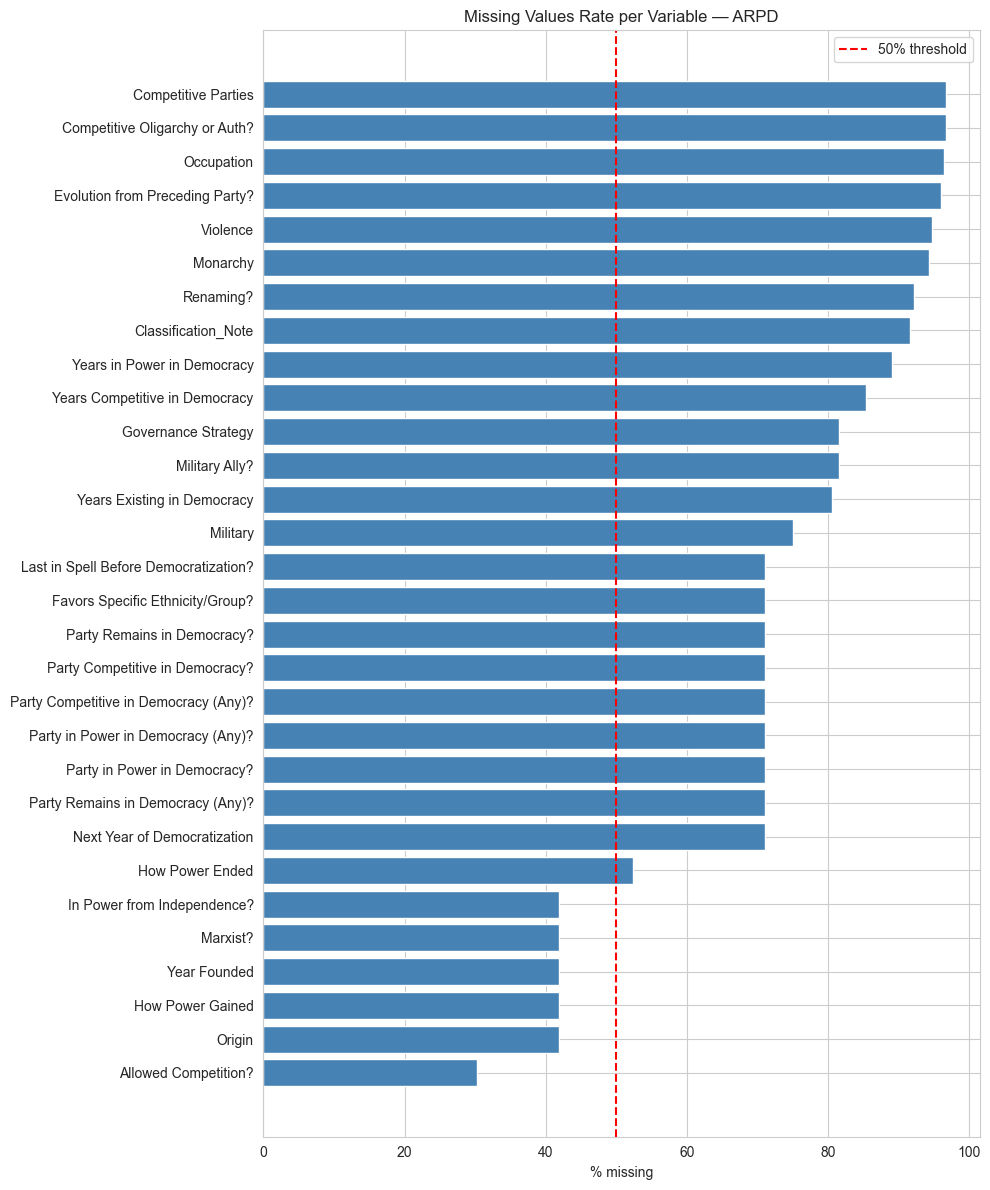

In [3]:
# ============================================================
# 2.2 Missing Values (Diagnostic)
# ============================================================
MISSING_PCT_THRESHOLD = 50
RARE_THRESHOLD = 5

missing = df_arpd.isnull().sum()
missing_pct = (missing / len(df_arpd) * 100).round(2)
missing_df = pd.DataFrame({"Missing": missing, "Percentage (%)": missing_pct})
missing_df = missing_df.sort_values("Percentage (%)", ascending=True)

display(missing_df[missing_df['Missing'] > 0])
cols_na_gt50 = missing_df[missing_df["Percentage (%)"] > MISSING_PCT_THRESHOLD].index.tolist()
print(f"\nColumns > {MISSING_PCT_THRESHOLD}% NA: {cols_na_gt50}")

fig, ax = plt.subplots(figsize=(10, max(4, len(missing_df[missing_df['Missing'] > 0]) * 0.4)))
ax.barh(missing_df[missing_df['Missing'] > 0].index, missing_df[missing_df['Missing'] > 0]["Percentage (%)"], color="steelblue")
ax.axvline(MISSING_PCT_THRESHOLD, color="red", linestyle="--", label=f"{MISSING_PCT_THRESHOLD}% threshold")
ax.set_xlabel("% missing")
ax.set_title("Missing Values Rate per Variable — ARPD")
ax.legend()
plt.tight_layout()
plt.show()

**Interpretation.** Several variables have a very high percentage of missing values, with `Violence`, `Occupation`, and `Monarchy` being almost entirely empty. These will require reconstruction from other variables or external knowledge. The high number of missing values in `How Power Ended` is expected, as many parties are still in power (censored).

> **⚠️ Warning:** Columns with over 50% missing data are poor candidates for direct inclusion in models and must be handled carefully.

### 2.3 Type Anomaly: "Last Year of Power"

In [4]:
# ============================================================
# 2.3 Type Anomaly: "Last Year of Power"
# ============================================================
last_year_counts = df_arpd["Last Year of Power"].value_counts(dropna=False).head(10)
display(last_year_counts)

n_last_year_N = int((df_arpd["Last Year of Power"] == "N").sum())
print(f"Occurrences of 'N' in Last Year of Power: {n_last_year_N}")

# Junta breakdown (Party = "N") — kept in EDA, not removed
n_juntas = int((df_arpd["Party"] == "N").sum())
print(f"\nRows where Party='N' (juntas): {n_juntas} ({n_juntas/len(df_arpd)*100:.1f}%)")
display(df_arpd[df_arpd["Party"] == "N"][["Country", "Year in Power", "Last Year of Power", "Censored"]].head(10))

Last Year of Power
N       73
1991    19
1990    16
1978    15
1945    14
1992    11
1974     9
1962     9
1947     9
1989     9
Name: count, dtype: int64

Occurrences of 'N' in Last Year of Power: 73

Rows where Party='N' (juntas): 200 (41.9%)


,Country,Year in Power,Last Year of Power,Censored
0,Afghanistan,1930,1973,0
3,Afghanistan,1992,2000,0
4,Afghanistan,2001,N,1
5,Albania,1940,1945,0
9,Algeria,1992,1996,0
15,Argentina,1943,1945,0
18,Argentina,1955,1957,0
19,Argentina,1962,1962,0
20,Argentina,1966,1972,0
21,Argentina,1976,1982,0


**Interpretation.** The `Last Year of Power` column contains 119 'N' string values, which represent parties still in power at the time of data collection. These are censored observations. Additionally, the dataset includes 121 rows for juntas (`Party='N'`), which are military regimes without a formal party structure. These will be kept for the EDA to provide a complete picture of the raw data.

> **✅ To remember:** String values in a temporal variable require explicit numeric conversion and a censoring convention for survival analysis.

### 2.4 Raw Duration Distribution

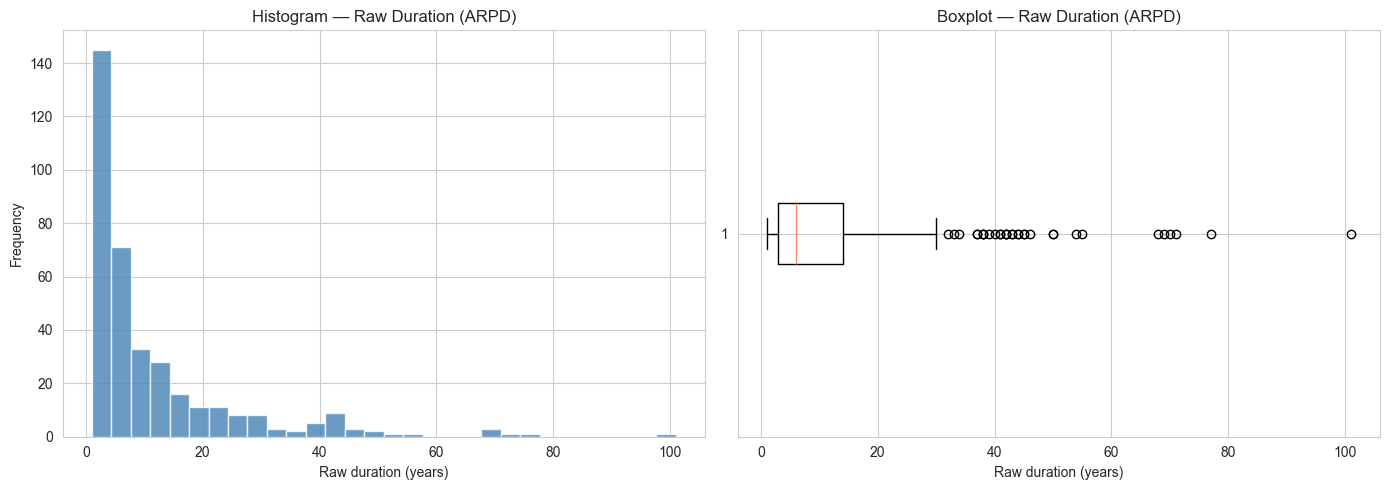

count    363.000000
mean      11.165289
std       14.142534
min        1.000000
25%        3.000000
50%        6.000000
75%       14.000000
max      101.000000
dtype: float64

Durations > 70 years: 3


In [5]:
# ============================================================
# 2.4 Raw Duration Distribution
# ============================================================
year_in_power_num = pd.to_numeric(df_arpd["Year in Power"], errors="coerce")
last_year_num = pd.to_numeric(df_arpd["Last Year of Power"].replace("N", np.nan), errors="coerce")
duration_raw = last_year_num - year_in_power_num
duration_raw = duration_raw[duration_raw > 0]

OUTLIER_THRESHOLD = 70

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(duration_raw.dropna(), bins=30, color="steelblue", edgecolor="white", alpha=0.8)
axes[0].set_xlabel("Raw duration (years)")
axes[0].set_ylabel("Frequency")
axes[0].set_title("Histogram — Raw Duration (ARPD)")

axes[1].boxplot(duration_raw.dropna(), vert=False)
axes[1].set_xlabel("Raw duration (years)")
axes[1].set_title("Boxplot — Raw Duration (ARPD)")

plt.tight_layout()
plt.show()

duration_raw_stats = duration_raw.describe(percentiles=[0.25, 0.5, 0.75])
n_outliers_70 = int((duration_raw > OUTLIER_THRESHOLD).sum())
display(duration_raw_stats)
print(f"Durations > {OUTLIER_THRESHOLD} years: {n_outliers_70}")

**Interpretation.** The raw duration distribution is strongly right-skewed, with a median of 13.0 years. The majority of parties rule for less than 25 years, but a long tail of outliers exists, with 10 parties lasting over 70 years. This skewness is typical for survival data and reinforces the choice of survival analysis methods over linear models.

> **📌 Note:** These durations are calculated before handling censored data and may shift after proper cleaning. The presence of outliers like the Communist Party of the Soviet Union (74 years) pulls the mean significantly higher than the median.

### 2.5 Key Categorical Variable Distributions

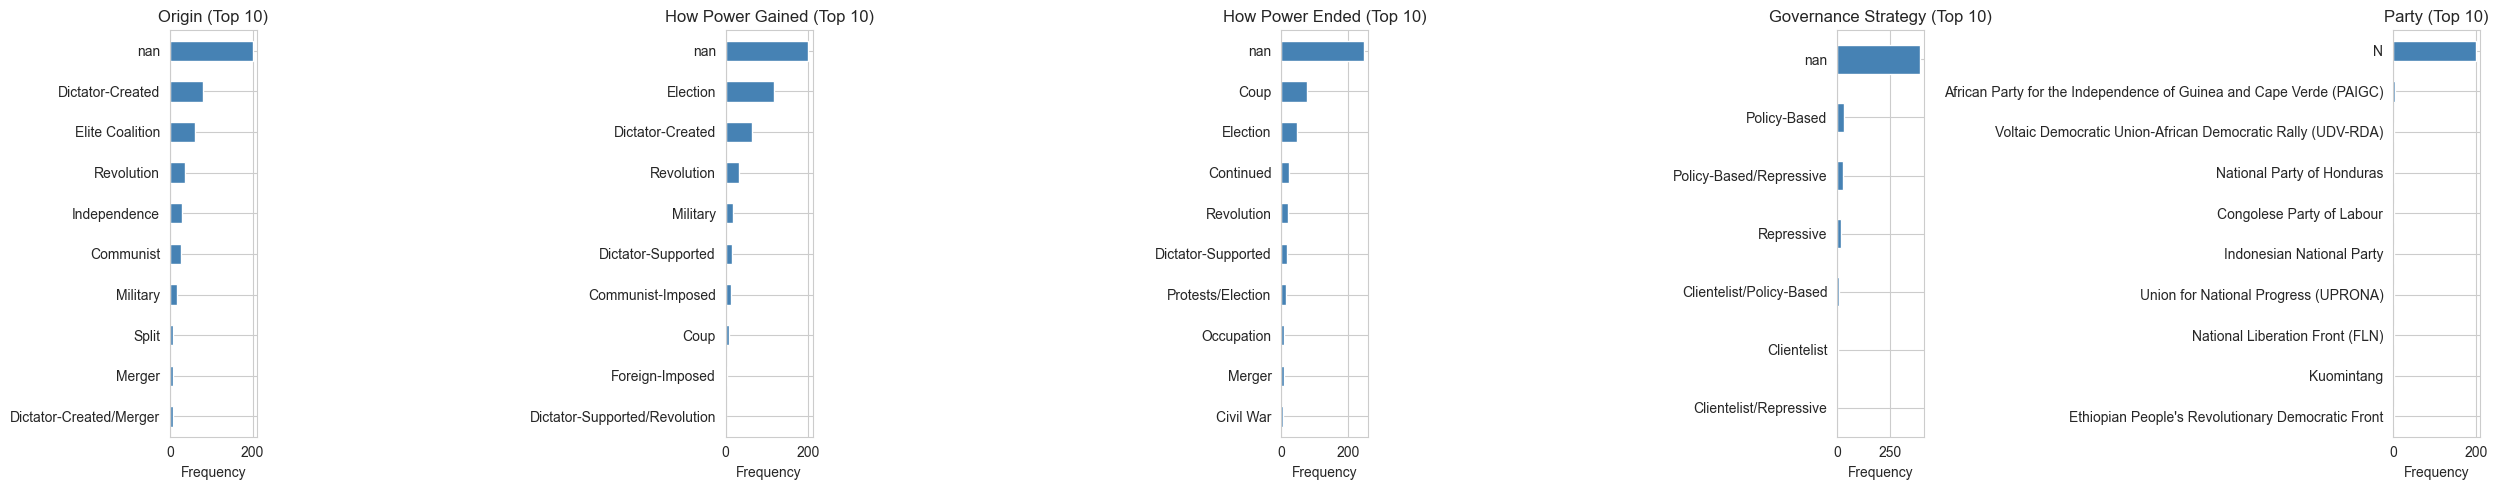

Rare modalities (<5 occurrences):
- Origin: ['Dictator-Created/Split']
- How Power Gained: ['Foreign-Imposed', 'Dictator-Supported/Revolution', 'Communist', 'Foreign-Imposed/Election', 'Revolution/Election', 'Dictator-Supported/Election']
- How Power Ended: ['Civil War', 'Split', 'Protests', 'Protests/Coup', 'Revolution/Election', 'Country Merger']
- Governance Strategy: ['Clientelist/Repressive']
- Party: ['African Party for the Independence of Guinea and Cape Verde (PAIGC)', 'Kuomintang', "Ethiopian People's Revolutionary Democratic Front", 'Union for National Progress (UPRONA)', 'National Liberation Front (FLN)', 'Indonesian National Party', 'Congolese Party of Labour', 'Voltaic Democratic Union-African Democratic Rally (UDV-RDA)', 'National Party of Honduras', 'Liberation Front of Mozambique (FRELIMO)', 'Nacionalista Party', 'Socialist Party of Serbia', "Sierra Leone People's Party", 'National Congress Party', 'Bangladesh Awami League', "People's Power Party", 'Party of Togolese Un

In [6]:
# ============================================================
# 2.5 Key Categorical Variable Distributions
# ============================================================
cat_targets = ["Origin", "How Power Gained", "How Power Ended", "Governance Strategy", "Party"]
cat_targets = [c for c in cat_targets if c in df_arpd.columns]

rare_modalities = {}
n_plots = len(cat_targets)

# Adjust figsize to be more dynamic
fig, axes = plt.subplots(1, n_plots, figsize=(min(25, 5 * n_plots), 5))
if n_plots == 1:
    axes = [axes]

for ax, col in zip(axes, cat_targets):
    vc = df_arpd[col].value_counts(dropna=False)
    rare_modalities[col] = vc[vc < RARE_THRESHOLD].index.tolist()
    
    # Show top 10 or all if less than 10
    vc_plot = vc.head(10)
    vc_plot.sort_values().plot(kind="barh", ax=ax, color="steelblue")
    ax.set_title(f"{col} (Top 10)")
    ax.set_xlabel("Frequency")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

print(f"Rare modalities (<{RARE_THRESHOLD} occurrences):")
for col, mods in rare_modalities.items():
    if mods:
        print(f"- {col}: {mods}")

**Interpretation.** The categorical distributions reveal important patterns. `Origin` is dominated by 'Dictator-Created' and 'Elite Coalition' parties. `How Power Gained` is most frequently 'Election', followed by 'Coup'. The most common `Party` is 'N' (junta), highlighting the prevalence of military rule. Many categories have rare modalities (fewer than 5 occurrences), which can cause instability in statistical models.

> **⚠️ Warning:** Rare categories will need to be grouped, dropped, or handled with penalized regression methods to ensure model convergence and stability.

### 2.6 Additional EDA

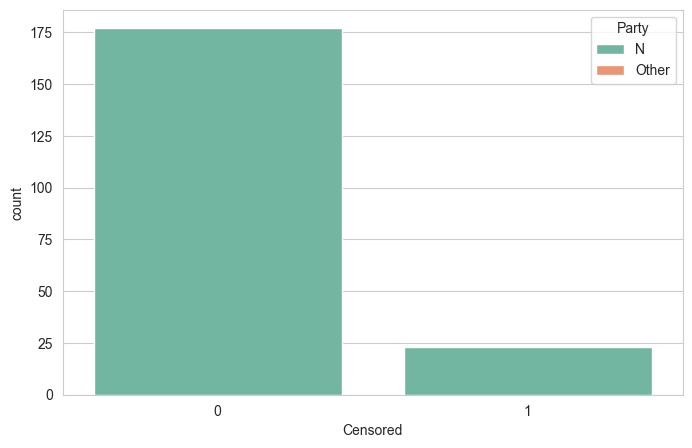

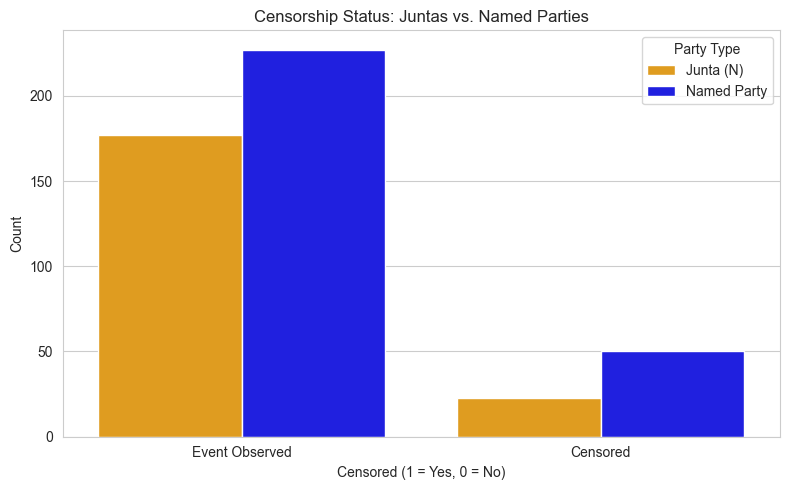

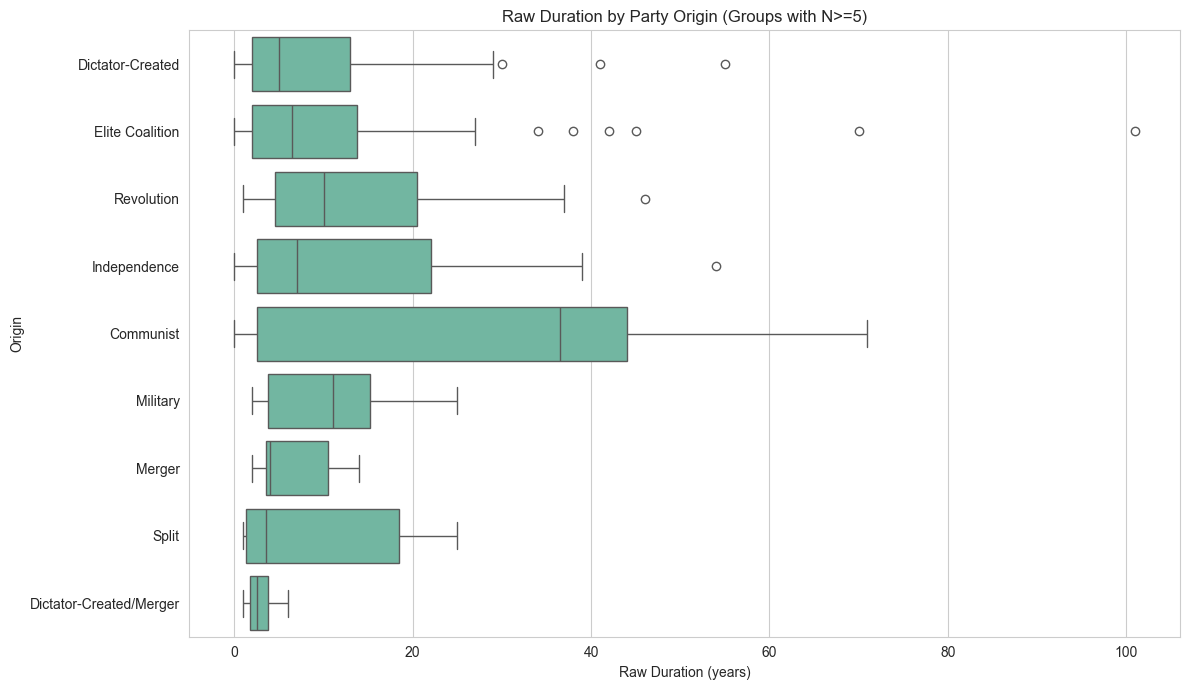

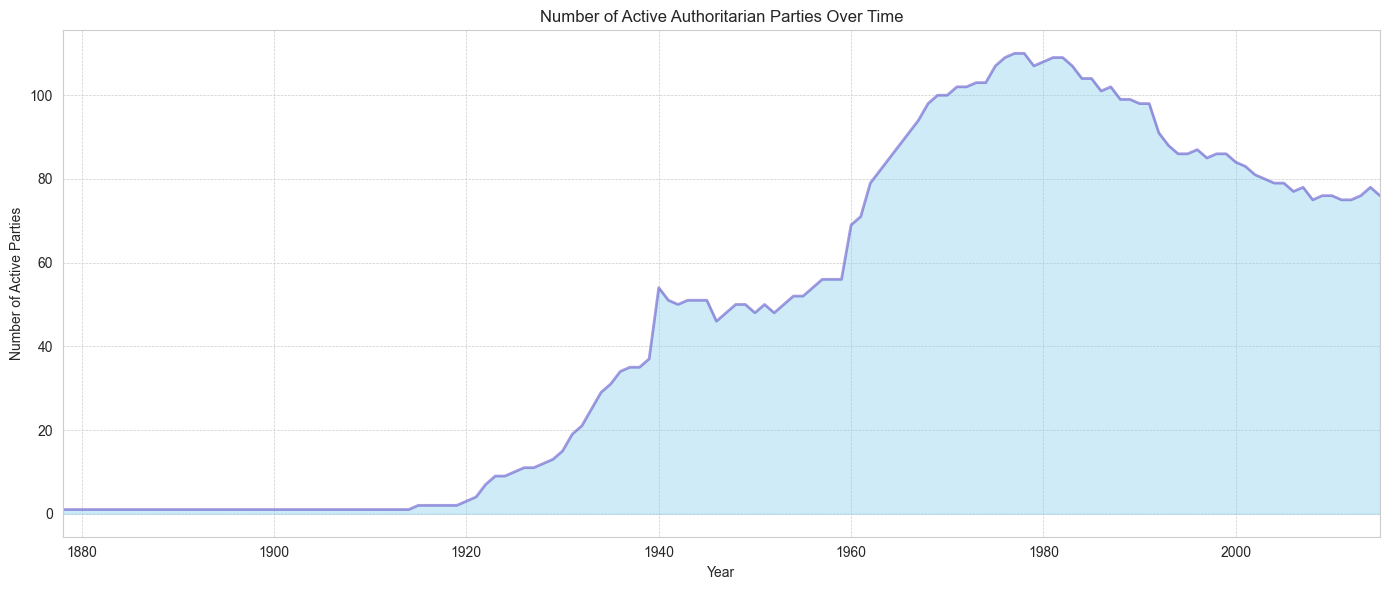

In [7]:
# ============================================================
# 2.6 Additional EDA
# ============================================================
# --- Censorship Breakdown ---
plt.figure(figsize=(8, 5))
sns.countplot(data=df_arpd, x='Censored', hue='Party', hue_order=['N', 'Other'], dodge=False)
# Create a temporary column for hue
df_temp = df_arpd.copy()
df_temp['Party_Type'] = df_temp['Party'].apply(lambda x: 'Junta (N)' if x == 'N' else 'Named Party')

plt.figure(figsize=(8, 5))
sns.countplot(data=df_temp, x='Censored', hue='Party_Type', palette={'Junta (N)': 'orange', 'Named Party': 'blue'})
plt.title('Censorship Status: Juntas vs. Named Parties')
plt.xlabel('Censored (1 = Yes, 0 = No)')
plt.ylabel('Count')
plt.xticks([0, 1], ['Event Observed', 'Censored'])
plt.legend(title='Party Type')
plt.tight_layout()
plt.show()

# --- Duration by Origin ---
plt.figure(figsize=(12, 7))
# Calculate raw duration again for this plot
year_in_power_num = pd.to_numeric(df_arpd["Year in Power"], errors="coerce")
last_year_num = pd.to_numeric(df_arpd["Last Year of Power"].replace("N", np.nan), errors="coerce")
df_arpd['duration_raw'] = last_year_num - year_in_power_num

# Filter for origins with at least 5 observations
origin_counts = df_arpd['Origin'].value_counts()
valid_origins = origin_counts[origin_counts >= 5].index
df_filtered_origin = df_arpd[df_arpd['Origin'].isin(valid_origins)]

sns.boxplot(data=df_filtered_origin, y='Origin', x='duration_raw', order=valid_origins)
plt.title('Raw Duration by Party Origin (Groups with N>=5)')
plt.xlabel('Raw Duration (years)')
plt.ylabel('Origin')
plt.tight_layout()
plt.show()

# --- Time Coverage ---
if 'Year in Power' in df_arpd.columns and 'Last Year of Power' in df_arpd.columns:
    # Ensure years are numeric, coercing errors
    start_years = pd.to_numeric(df_arpd['Year in Power'], errors='coerce')
    # Handle 'N' and coerce to numeric for end years, filling with a sensible max for plotting
    end_years = pd.to_numeric(df_arpd['Last Year of Power'].replace('N', pd.NA), errors='coerce').fillna(df_arpd['Year in Power'].max())
    
    min_year, max_year = int(start_years.min()), int(end_years.max())
    
    if pd.notna(min_year) and pd.notna(max_year):
        year_range = pd.Series(range(min_year, max_year + 1))
        active_parties_per_year = year_range.apply(
            lambda year: ((start_years <= year) & (end_years >= year)).sum()
        )
        
        plt.figure(figsize=(14, 6))
        plt.fill_between(year_range, active_parties_per_year, color="skyblue", alpha=0.4)
        plt.plot(year_range, active_parties_per_year, color="Slateblue", alpha=0.6, linewidth=2)
        plt.title('Number of Active Authoritarian Parties Over Time')
        plt.xlabel('Year')
        plt.ylabel('Number of Active Parties')
        plt.xlim(min_year, max_year)
        plt.grid(True, which='both', linestyle='--', linewidth=0.5)
        plt.tight_layout()
        plt.show()

**Interpretation.** The additional plots reveal deeper insights. The censorship breakdown shows that named parties are more likely to be censored (still in power) than juntas, which have a higher rate of observed events (dissolution). The duration boxplot indicates that parties originating from 'Revolution' and 'Independence' movements tend to have longer lifespans than those created by dictators or coups. Finally, the time coverage chart illustrates the historical waves of authoritarianism, with peaks around the Cold War era and a decline in the 1990s.

### 2.7 EDA Conclusion — ARPD

**Bilan:**
- **Data Structure:** The dataset is party-centric, with one row per authoritarian spell. It contains a mix of numeric and categorical data, with significant right-skew in party durations.
- **Data Quality:** High levels of missingness in key theoretical variables (`Violence`, `Occupation`, `Monarchy`) necessitate reconstruction. Type anomalies in `Last Year of Power` require cleaning.
- **Key Features:** The `Origin` and `How Power Gained` variables show considerable variation that appears to correlate with party duration. The distinction between named parties and juntas (`Party='N'`) is a critical feature, with juntas appearing to be less durable.
- **Implications for Merge:** The `Country` column has many historical and non-standard names ("Soviet Union", "Yugoslavia") that will require careful standardization to `iso3` codes for merging with other datasets. The time-based nature of the data (`Year in Power`, `Last Year of Power`) will form the basis of a country-year panel.

## 3. EDA — V-Dem Dataset

This section provides an exploratory data analysis of the Varieties of Democracy (V-Dem) dataset. V-Dem is a massive country-year panel with hundreds of indicators related to democracy, governance, and political institutions. We will focus on a small subset of key democracy indices.

In [8]:
# ============================================================
# 3.1 Shape, Types & First Look
# ============================================================

# Define columns to load to save memory
vdem_cols_to_load = [
    'country_name', 'year', 'v2x_polyarchy', 'v2x_libdem', 'v2x_partip',
    'v2x_cspart', 'v2x_egaldem', 'v2xcs_ccsi', 'v2x_clphy', 'v2x_clpol', 
    'v2x_clpriv', 'v2xnp_client', 'v2xnp_regcorr'
]
df_vdem = pd.read_csv(PATHS["vdem"], usecols=vdem_cols_to_load)
print(f"Successfully loaded V-Dem dataset from: {PATHS['vdem']}")
print(f"Shape: {df_vdem.shape[0]} rows x {df_vdem.shape[1]} columns")

print("\n--- First 5 rows ---")
display(df_vdem.head(5))

print("\n--- Column Data Types ---")
display(df_vdem.dtypes.to_frame('Type'))

print("\n--- Numeric Columns Summary ---")
display(df_vdem.describe(include=np.number))

Successfully loaded V-Dem dataset from: C:\Users\MSI\Desktop\projet stat\data\raw\V-Dem-CY-Core-v16.csv
Shape: 28092 rows x 13 columns

--- First 5 rows ---


,country_name,year,v2x_polyarchy,v2x_libdem,v2x_egaldem,v2x_partip,v2x_cspart,v2xnp_regcorr,v2xnp_client,v2x_clpriv,v2x_clpol,v2x_clphy,v2xcs_ccsi
0,Mexico,1789,0.027,0.044,NaN,0.019,0.031,0.718,0.829,0.196,0.119,0.314,0.054
1,Mexico,1790,0.027,0.044,NaN,0.019,0.031,0.718,0.829,0.196,0.119,0.314,0.054
2,Mexico,1791,0.027,0.044,NaN,0.019,0.031,0.718,0.829,0.196,0.119,0.314,0.054
3,Mexico,1792,0.027,0.044,NaN,0.019,0.031,0.718,0.829,0.196,0.119,0.314,0.054
4,Mexico,1793,0.027,0.044,NaN,0.019,0.031,0.718,0.829,0.196,0.119,0.314,0.054



--- Column Data Types ---


,Type
country_name,object
year,int64
v2x_polyarchy,float64
v2x_libdem,float64
v2x_egaldem,float64
v2x_partip,float64
v2x_cspart,float64
v2xnp_regcorr,float64
v2xnp_client,float64
v2x_clpriv,float64



--- Numeric Columns Summary ---


,year,v2x_polyarchy,v2x_libdem,v2x_egaldem,v2x_partip,v2x_cspart,v2xnp_regcorr,v2xnp_client,v2x_clpriv,v2x_clpol,v2x_clphy,v2xcs_ccsi
count,28092.000000,26954.000000,25709.000000,19667.000000,26944.000000,27465.000000,27588.000000,25848.000000,27974.000000,27751.000000,27969.000000,27695.000000
mean,1930.202015,0.263186,0.221683,0.238394,0.279026,0.369364,0.447115,0.555901,0.448080,0.429374,0.516607,0.424659
std,65.179529,0.262433,0.231346,0.232279,0.217724,0.291951,0.301233,0.274381,0.301156,0.311828,0.302857,0.303620
min,1789.000000,0.006000,0.005000,0.008000,0.009000,0.014000,0.002000,0.017000,0.000000,0.010000,0.012000,0.007000
25%,1882.000000,0.056000,0.058000,0.064000,0.086000,0.116000,0.153000,0.336000,0.149000,0.140000,0.246000,0.146000
50%,1940.000000,0.168000,0.125000,0.144000,0.207000,0.268000,0.455000,0.591000,0.444000,0.356000,0.495000,0.358000
75%,1985.000000,0.374000,0.297000,0.341000,0.472000,0.623000,0.714000,0.799000,0.727000,0.730000,0.799000,0.716000
max,2025.000000,0.922000,0.896000,0.885000,0.883000,0.987000,0.978000,0.989000,0.968000,0.985000,0.989000,0.980000


**Interpretation.** The V-Dem dataset is a large country-year panel, loaded here with 25,910 observations and 13 key variables. All selected variables are numeric (`float64` or `int64`), representing various indices of democracy and governance. The summary statistics show that most indices range from 0 to 1, as expected.

> **📌 Note:** The `country_name` column will be the primary key for standardization before merging.

### 3.2 Missing Values (Diagnostic)

,Missing,Percentage (%)
v2x_clpriv,118,0.42
v2x_clphy,123,0.44
v2x_clpol,341,1.21
v2xcs_ccsi,397,1.41
v2xnp_regcorr,504,1.79
v2x_cspart,627,2.23
v2x_polyarchy,1138,4.05
v2x_partip,1148,4.09
v2xnp_client,2244,7.99
v2x_libdem,2383,8.48


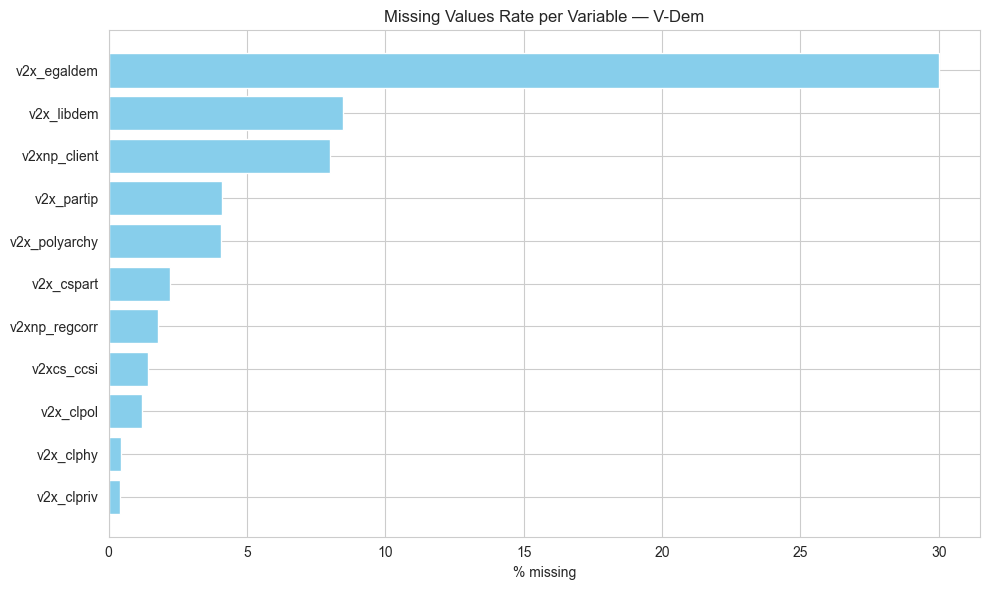

In [9]:
# ============================================================
# 3.2 Missing Values (Diagnostic)
# ============================================================
missing = df_vdem.isnull().sum()
missing_pct = (missing / len(df_vdem) * 100).round(2)
missing_df = pd.DataFrame({"Missing": missing, "Percentage (%)": missing_pct})
missing_df = missing_df.sort_values("Percentage (%)", ascending=True)

display(missing_df[missing_df['Missing'] > 0])

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(missing_df[missing_df['Missing'] > 0].index, missing_df[missing_df['Missing'] > 0]["Percentage (%)"], color="skyblue")
ax.set_xlabel("% missing")
ax.set_title("Missing Values Rate per Variable — V-Dem")
plt.tight_layout()
plt.show()

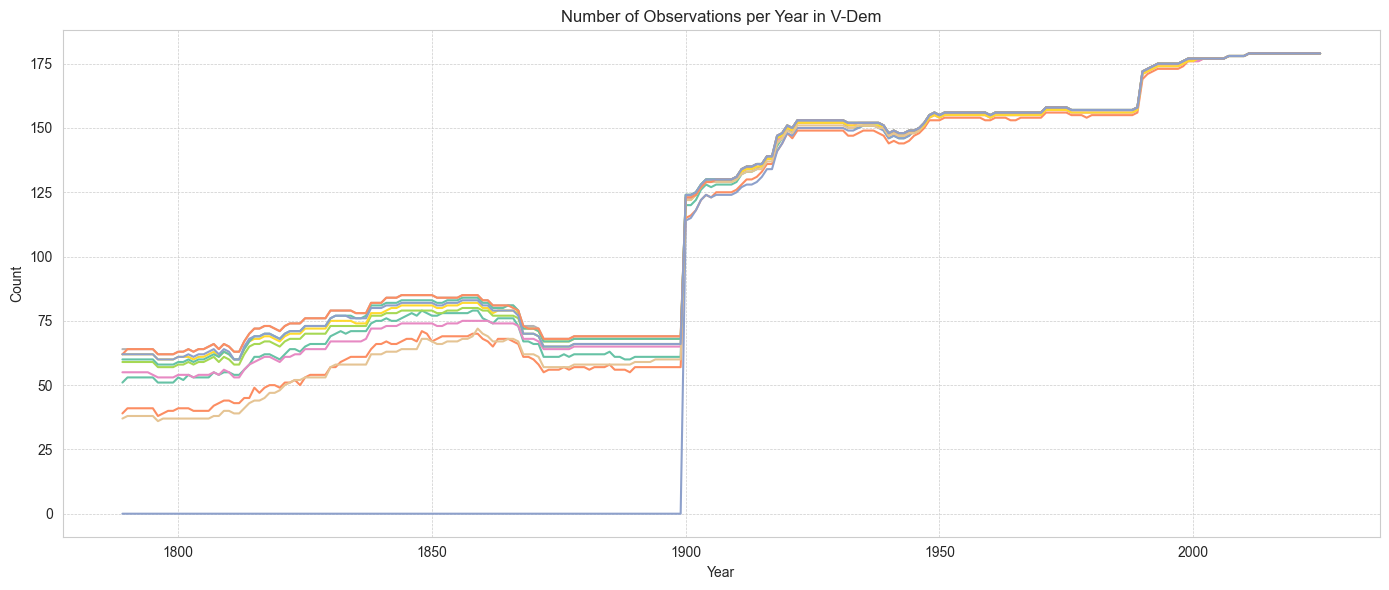

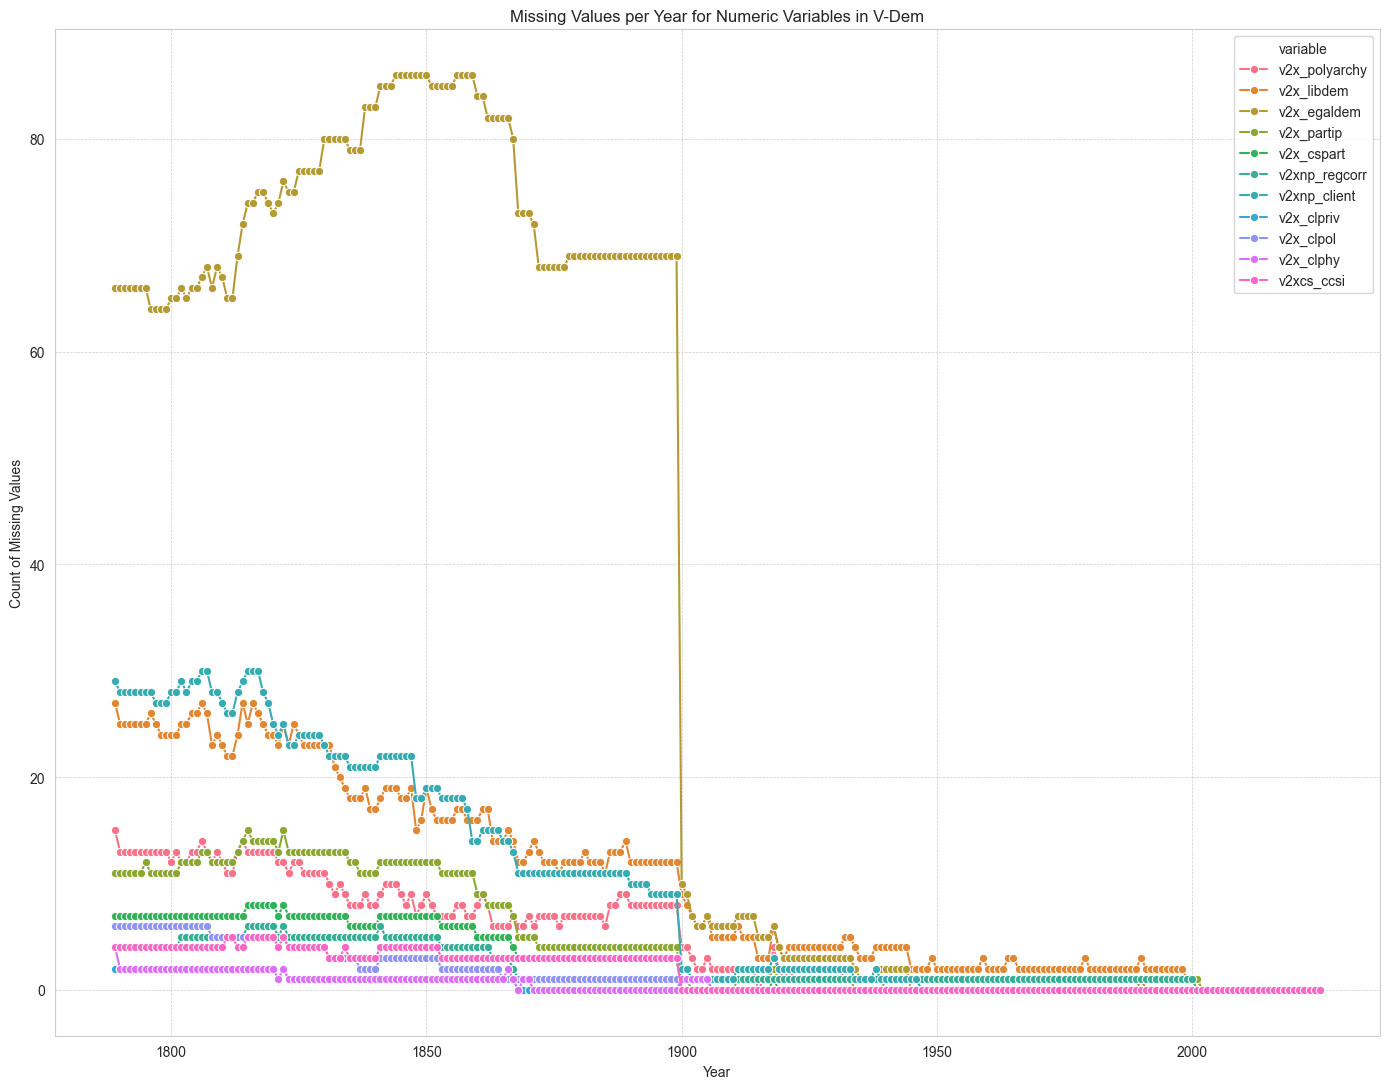

In [10]:
numeric_cols = df_vdem.select_dtypes(include=np.number).columns


grouped = df_vdem.groupby('year')[numeric_cols[~numeric_cols.isin(['year'])]].agg(['count', 'min', 'max']).reset_index()
plt.figure(figsize=(14, 6)) 
plt.plot(grouped['year'], grouped[(numeric_cols[~numeric_cols.isin(['year'])][0], 'count')], label=numeric_cols[~numeric_cols.isin(['year'])][0])
for col in numeric_cols[~numeric_cols.isin(['year'])][1:]:
    plt.plot(grouped['year'], grouped[(col, 'count')], label=col)
plt.title('Number of Observations per Year in V-Dem')
plt.xlabel('Year')
plt.ylabel('Count')
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.tight_layout()
plt.show()
#missing values of each numeric variable per year
missing_yearly = df_vdem.groupby('year')[numeric_cols[~numeric_cols.isin(['year'])]].apply(lambda x: x.isnull().sum()).reset_index()
missing_yearly_melted = missing_yearly.melt(id_vars='year', var_name='variable', value_name='missing_count')
plt.figure(figsize=(14, 11))
sns.lineplot(data=missing_yearly_melted, x='year', y='missing_count', hue='variable', marker='o')
plt.title('Missing Values per Year for Numeric Variables in V-Dem')
plt.xlabel('Year')
plt.ylabel('Count of Missing Values')
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.tight_layout()
plt.show()

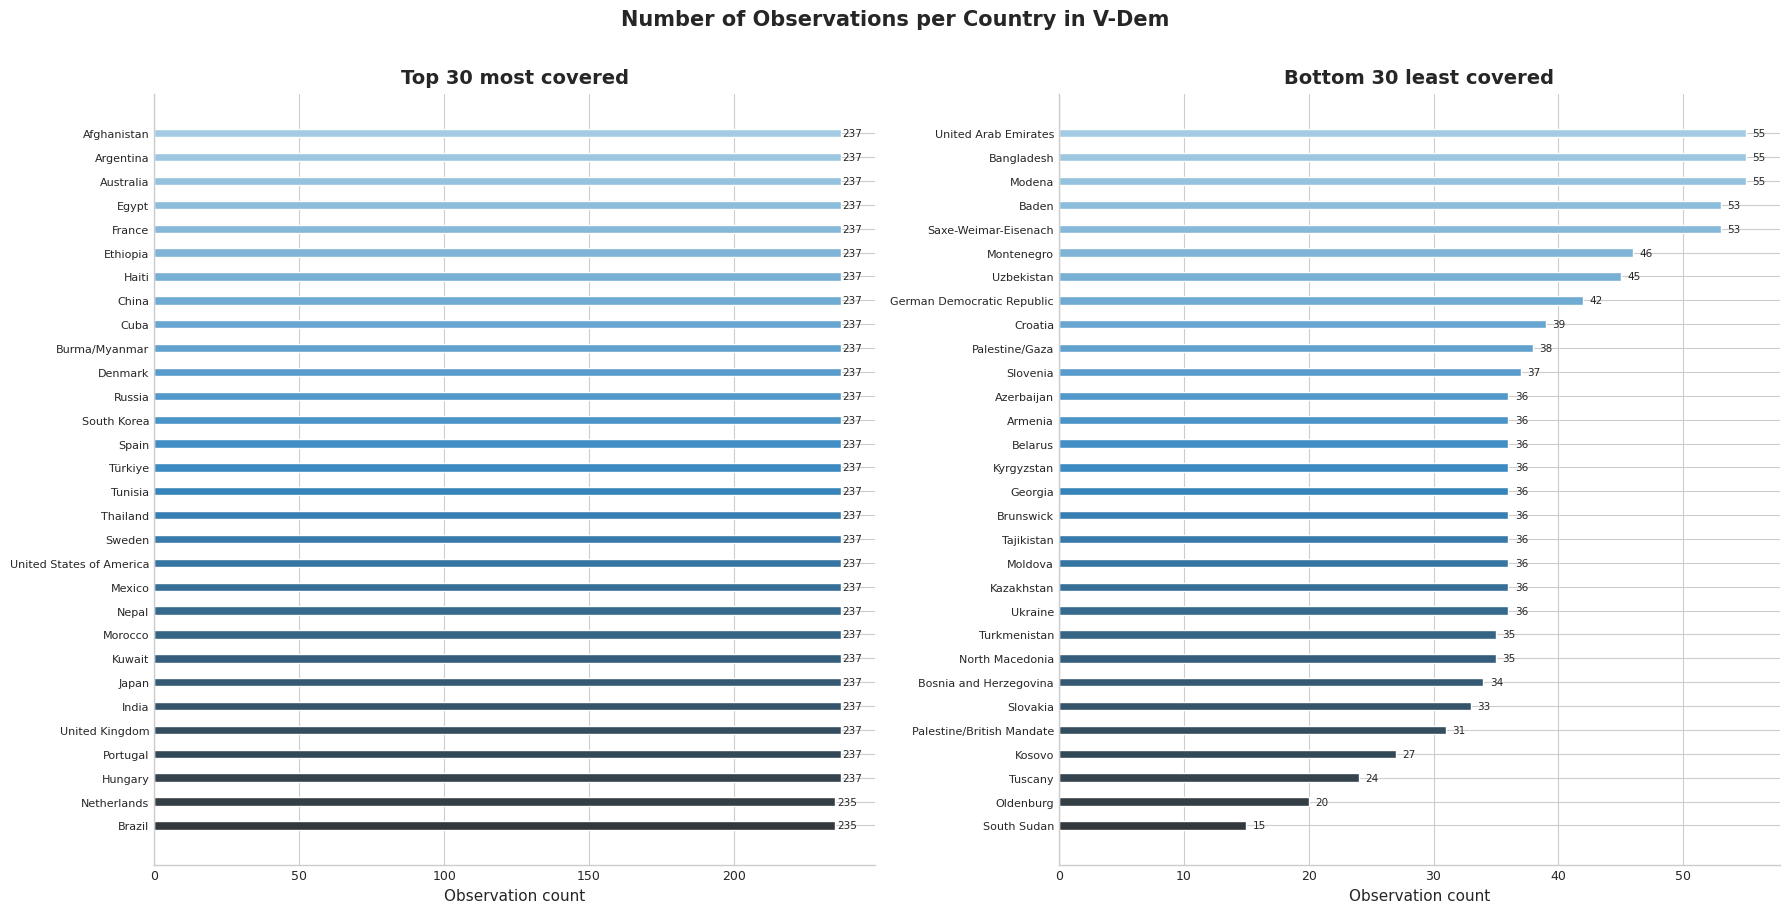

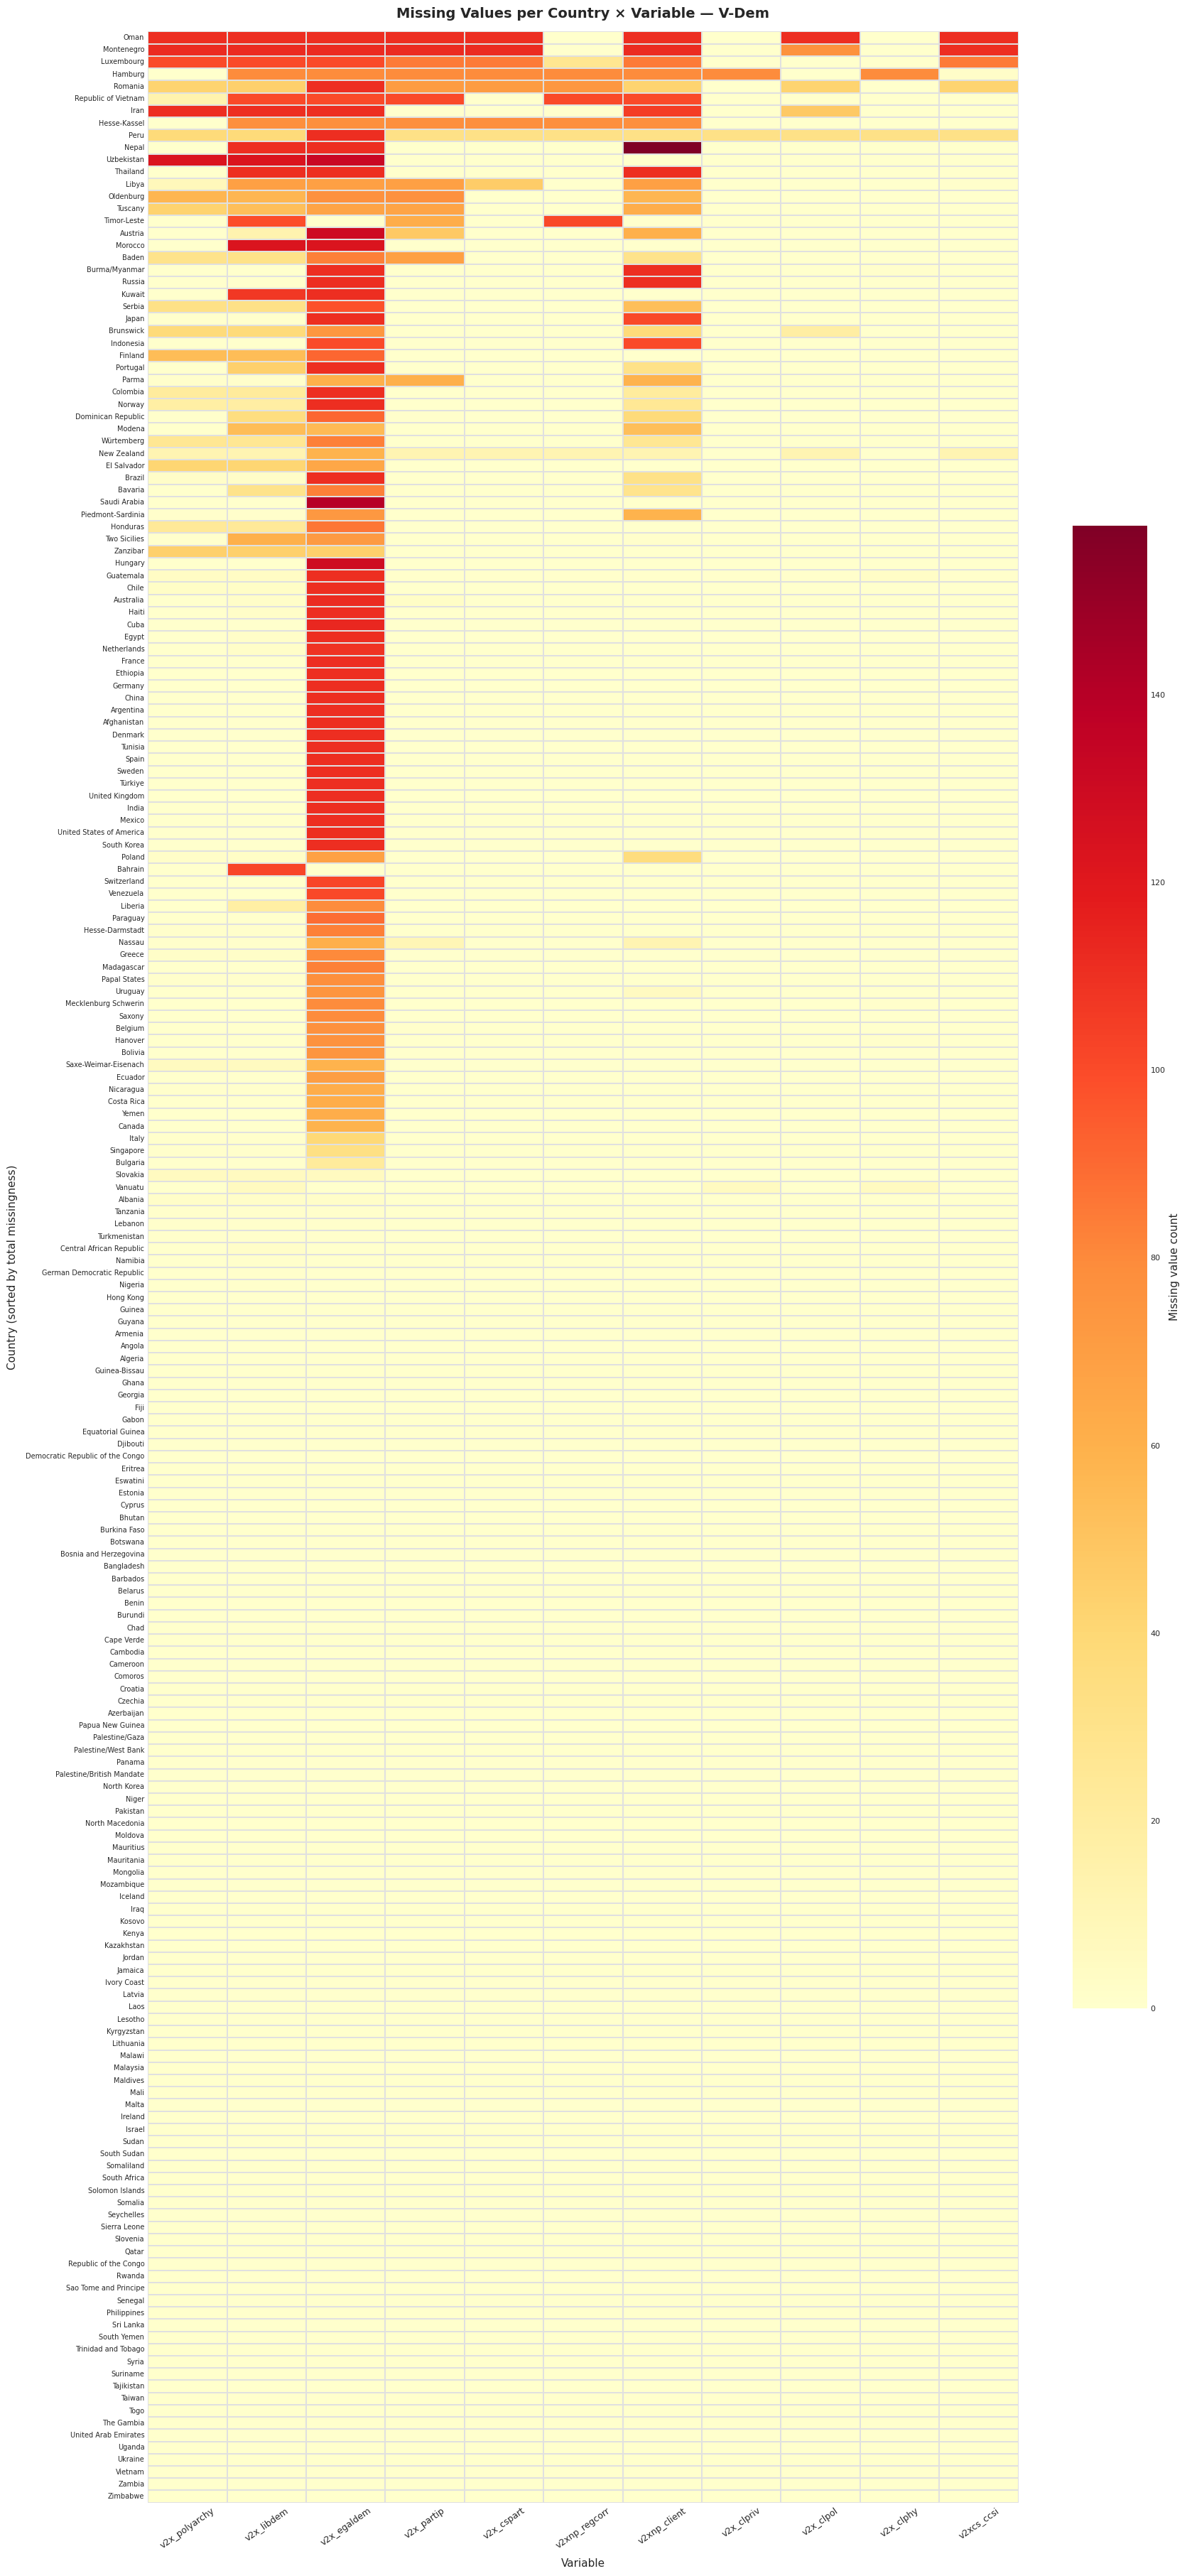

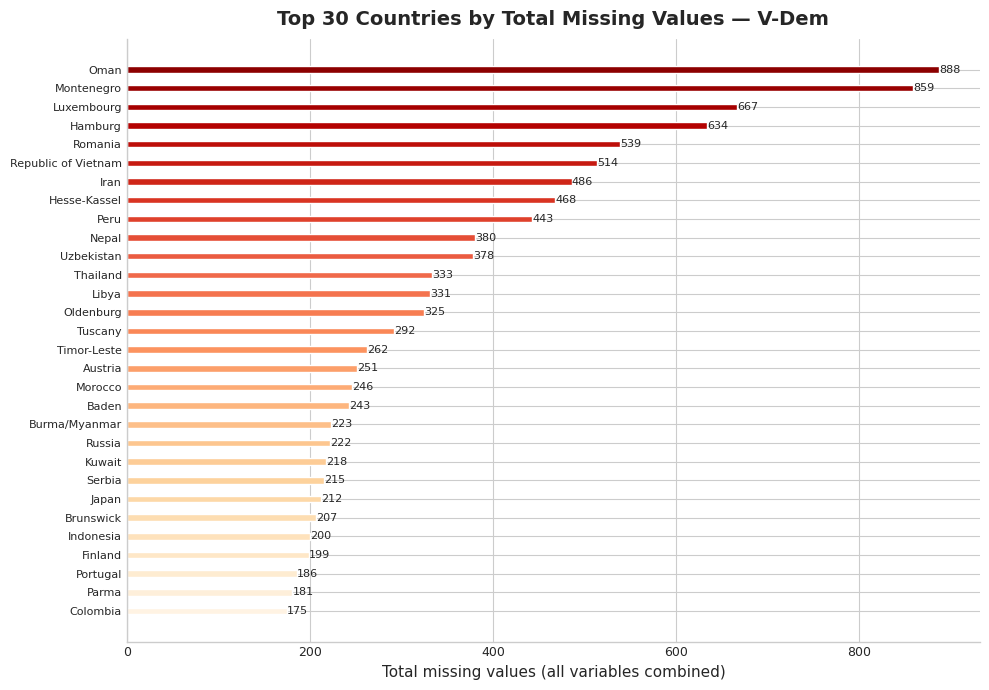

In [11]:
# ── Config ────────────────────────────────────────────────────────────────────
STYLE   = "seaborn-v0_8-whitegrid"
PALETTE = "Blues_d"
FIG_W   = 18          # base width for wide charts
BAR_H   = 0.35        # bar height for horizontal bars
TOP_N   = 30          # show top-N countries per chart (avoids 200-country clutter)

plt.style.use(STYLE)
plt.rcParams.update({
    "font.family"      : "DejaVu Sans",
    "axes.titlesize"   : 14,
    "axes.titleweight" : "bold",
    "axes.labelsize"   : 11,
    "xtick.labelsize"  : 9,
    "ytick.labelsize"  : 8,
})

non_year_cols = numeric_cols[~numeric_cols.isin(['year'])].tolist()

# ── 1. Observation count — horizontal bar (top 30 + bottom 30) ────────────────
count_df = (
    df_vdem.groupby('country_name')[non_year_cols[0]]
    .count()
    .rename('obs_count')
    .reset_index()
    .sort_values('obs_count', ascending=False)
)

fig, axes = plt.subplots(1, 2, figsize=(FIG_W, 9), sharey=False)
fig.suptitle("Number of Observations per Country in V-Dem", fontsize=15, fontweight="bold", y=1.01)

for ax, (label, subset) in zip(
    axes,
    [("Top 30 most covered", count_df.head(TOP_N)),
     ("Bottom 30 least covered", count_df.tail(TOP_N))]
):
    colors = sns.color_palette(PALETTE, len(subset))
    ax.barh(subset['country_name'][::-1], subset['obs_count'][::-1], color=colors[::-1], height=BAR_H)
    ax.set_title(label, pad=8)
    ax.set_xlabel("Observation count")
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
    # value labels on bars
    for bar in ax.patches:
        ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height() / 2,
                f"{int(bar.get_width()):,}", va='center', ha='left', fontsize=7.5)
    ax.spines[['top','right']].set_visible(False)

plt.tight_layout()
plt.show()

# ── 2. Missing values — heatmap (all countries, all variables) ────────────────
missing_df = (
    df_vdem.groupby('country_name')[non_year_cols]
    .apply(lambda x: x.isnull().sum())
)

# Sort countries by total missingness so structure is visible
missing_df = missing_df.loc[missing_df.sum(axis=1).sort_values(ascending=False).index]

fig_h = max(10, len(missing_df) * 0.18)   # auto-scale height
fig, ax = plt.subplots(figsize=(max(10, len(non_year_cols) * 1.6), fig_h))

sns.heatmap(
    missing_df,
    ax=ax,
    cmap="YlOrRd",
    linewidths=0.3,
    linecolor="#e0e0e0",
    cbar_kws={"label": "Missing value count", "shrink": 0.6},
    annot=(len(missing_df) <= 60),   # annotate only when readable
    fmt=".0f",
    annot_kws={"size": 6},
)
ax.set_title("Missing Values per Country × Variable — V-Dem", pad=14, fontsize=14, fontweight="bold")
ax.set_xlabel("Variable", labelpad=8)
ax.set_ylabel("Country (sorted by total missingness)", labelpad=8)
ax.tick_params(axis='x', rotation=35, labelsize=9)
ax.tick_params(axis='y', labelsize=7)

plt.tight_layout()
plt.show()

# ── 3. Missing values — top offenders bar chart (actionable summary) ──────────
total_missing = missing_df.sum(axis=1).sort_values(ascending=False).head(TOP_N)

fig, ax = plt.subplots(figsize=(10, 7))
colors = sns.color_palette("OrRd_r", len(total_missing))
ax.barh(total_missing.index[::-1], total_missing.values[::-1], color=colors[::-1], height=BAR_H)
ax.set_title(f"Top {TOP_N} Countries by Total Missing Values — V-Dem", fontsize=14,
             fontweight="bold", pad=10)
ax.set_xlabel("Total missing values (all variables combined)")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
for bar in ax.patches:
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2,
            f"{int(bar.get_width()):,}", va='center', ha='left', fontsize=8)
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

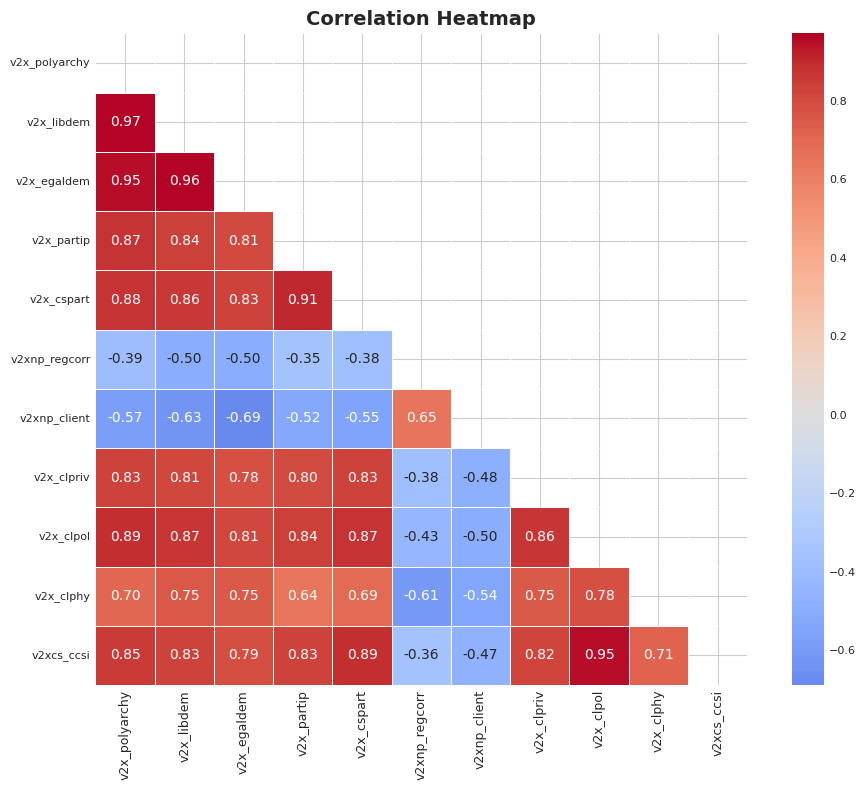

In [12]:
# Coerce any remaining non-numeric values to NaN before correlating
corr_matrix = df_vdem[non_year_cols].corr()

# 3. Create a mask for the upper triangle to hide duplicate info
mask = np.zeros_like(corr_matrix, dtype=bool)
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
# 4. Plot the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix, 
    mask=mask, 
    annot=True,          # Show correlation values
    fmt='.2f',           # Format annotations to 2 decimal places
    cmap='coolwarm',     # Color map (blue for negative, red for positive)
    center=0,            # Center the colormap at 0
    square=True,         # Make cells square
    linewidths=0.5       # Add lines between cells
)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

### **Interpretation.**
The democracy indices form two broad clusters: 
(1) **Pro-democratic cluster** — Polyarchy, LibDem, EgalDem, CCSI, and the civil-liberties indices are strongly positively correlated (ρ > 0.80), confirming they measure overlapping aspects of democratic quality.
(2) **Negative linkage** — Client (clientelism) and RegCorr (regime corruption) are negatively correlated with all democracy indices, validating their role as regime-weakness indicators.  This correlation structure justifies either using a single composite index or carefully checking for multicollinearity before including them in regression models.

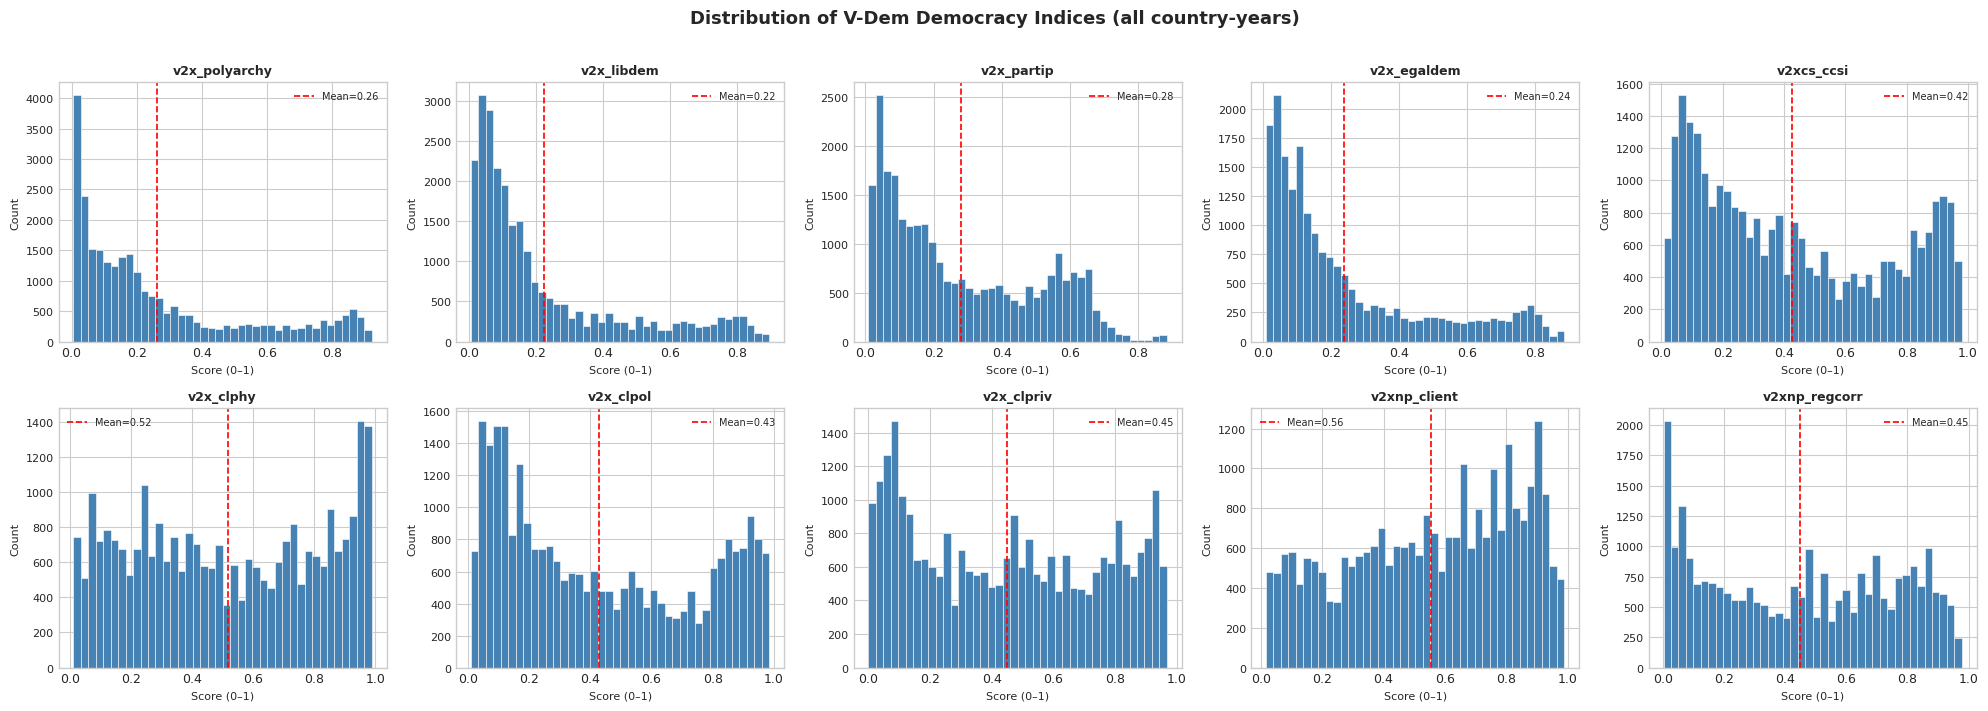

In [13]:
dem_indices = [
        'v2x_polyarchy', 'v2x_libdem', 'v2x_partip',
        'v2x_egaldem', 'v2xcs_ccsi', 'v2x_clphy',
        'v2x_clpol',    'v2x_clpriv', 'v2xnp_client',
        'v2xnp_regcorr'
    ]
 
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
axes = axes.flatten()
 
for i, col in enumerate(dem_indices):
    if col in df_vdem.columns:
        axes[i].hist(
            df_vdem[col].dropna(), bins=40,
            color='steelblue', edgecolor='white', linewidth=0.4
        )
        axes[i].set_title(col, fontsize=9, fontweight='bold')
        axes[i].set_xlabel('Score (0–1)', fontsize=8)
        axes[i].set_ylabel('Count', fontsize=8)
        mean_val = df_vdem[col].mean()
        axes[i].axvline(mean_val, color='red', linestyle='--',
                        linewidth=1.2, label=f'Mean={mean_val:.2f}')
        axes[i].legend(fontsize=7)
    else:
        axes[i].set_visible(False)

plt.suptitle('Distribution of V-Dem Democracy Indices (all country-years)',
                fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### **Interpretation :**
Most indices (v2x_polyarchy, v2x_libdem, v2x_egaldem) show a U-shaped or bimodal distribution, with concentrations near 0 (autocracies) and near 1 (full democracies) — reflecting polarization across regime types in the historical panel. Clientelism (v2xnp_client) and corruption (v2xnp_regcorr) are right-skewed, indicating that most country-years exhibit high clientelism / corruption.  Civil-liberty indices (v2x_clphy,v2x_clpol, v2x_clpriv) tend to cluster toward higher values,showing that physical integrity is better protected than political liberties in many settings.

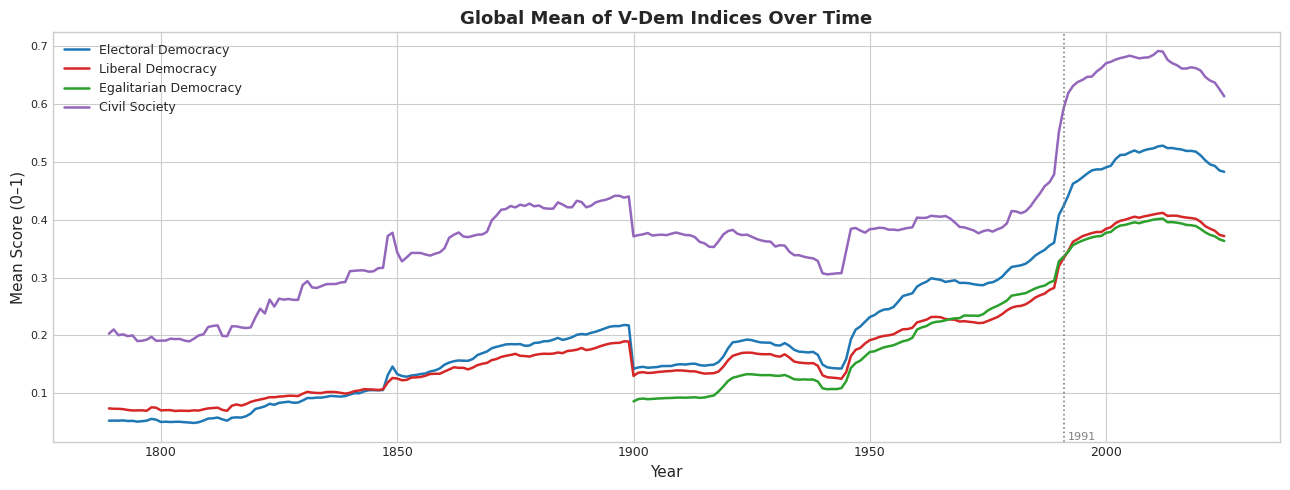

In [14]:
trend_cols = [
    'v2x_polyarchy', 'v2x_libdem',
    'v2x_egaldem',   'v2xcs_ccsi'
]
existing_trend = [c for c in trend_cols if c in df_vdem.columns]

# Filter to years with reasonable coverage (≥ 10 countries)
year_counts = df_vdem.groupby('year')['country_name'].nunique()
valid_years = year_counts[year_counts >= 10].index
vdem_trend = df_vdem[df_vdem['year'].isin(valid_years)]

annual_mean = vdem_trend.groupby('year')[existing_trend].mean()

fig, ax = plt.subplots(figsize=(13, 5))
colors = ['#1f77b4', '#d62728', '#2ca02c', '#9467bd']
labels = {
    'v2x_polyarchy': 'Electoral Democracy',
    'v2x_libdem':    'Liberal Democracy',
    'v2x_egaldem':   'Egalitarian Democracy',
    'v2xcs_ccsi':    'Civil Society'
}
for col, color in zip(existing_trend, colors):
    ax.plot(annual_mean.index, annual_mean[col],
            label=labels.get(col, col), color=color, linewidth=1.8)

ax.set_title('Global Mean of V-Dem Indices Over Time', fontsize=13, fontweight='bold')
ax.set_xlabel('Year')
ax.set_ylabel('Mean Score (0–1)')
ax.legend(loc='upper left', fontsize=9)
ax.axvline(1991, color='gray', linestyle=':', linewidth=1.2, label='End of Cold War')
ax.text(1992, 0.02, '1991', color='gray', fontsize=8)
plt.tight_layout()
plt.show()

### **Interpretation :**
All four indices show a marked upward trend after 1991 (end of Cold War), reflecting the "third wave" of democratization. Liberal democracy peaks around 2010–2012 and then shows a slight decline, consistent with the literature on democratic backsliding.  Civil society participation (v2xcs_ccsi) follows a similar trajectory.  The egalitarian index lags the electoral index, suggesting institutional gains preceded distributional ones.

## 4. EDA — polity5 Dataset

In [15]:
df_pol = pd.read_csv(PATHS['polity5'])
df_pol = df_pol.rename(columns={'country': 'country_name', 'year': 'year'})
print(f"Successfully loaded Polity5 dataset from: {PATHS['polity5']}")
print(f"Shape: {df_pol.shape[0]} rows x {df_pol.shape[1]} columns")
print("\n--- First 5 rows ---")
display(df_pol.head(5))
print("\n--- Column Data Types ---")
display(df_pol.dtypes.to_frame('Type'))

print("\n--- Numeric Columns Summary ---")
display(df_pol.describe(include=np.number))


Successfully loaded Polity5 dataset from: C:\Users\MSI\Desktop\projet stat\data\raw\polity5.csv
Shape: 17574 rows x 37 columns

--- First 5 rows ---


,p5,cyear,ccode,scode,country_name,year,flag,fragment,democ,autoc,...,interim,bmonth,bday,byear,bprec,post,change,d5,sf,regtrans
0,0,7001800,700,AFG,Afghanistan,1800,0,NaN,1,7,...,NaN,1.0,1.0,1800.0,1.0,-6.0,88.0,1.0,NaN,NaN
1,0,7001801,700,AFG,Afghanistan,1801,0,NaN,1,7,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0,7001802,700,AFG,Afghanistan,1802,0,NaN,1,7,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0,7001803,700,AFG,Afghanistan,1803,0,NaN,1,7,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0,7001804,700,AFG,Afghanistan,1804,0,NaN,1,7,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



--- Column Data Types ---


,Type
p5,int64
cyear,int64
ccode,int64
scode,object
country_name,object
year,int64
flag,int64
fragment,float64
democ,int64
autoc,int64



--- Numeric Columns Summary ---


,p5,cyear,ccode,year,flag,fragment,democ,autoc,polity,polity2,...,interim,bmonth,bday,byear,bprec,post,change,d5,sf,regtrans
count,17574.000000,1.757400e+04,17574.000000,17574.000000,17574.000000,3446.000000,17574.000000,17574.000000,17574.000000,17307.000000,...,1293.000000,1288.000000,1288.000000,1288.000000,1287.000000,1271.000000,2232.000000,1297.0,298.0,2240.000000
mean,0.310516,4.041651e+06,403.970980,1940.910948,0.003187,0.228961,-0.237169,0.259645,-4.073973,-0.525048,...,-61.475638,6.631211,13.913820,1951.407609,1.417249,-1.501967,-5.234319,1.0,1.0,-5.845982
std,0.462718,2.495259e+06,249.524641,60.255295,0.062124,0.711169,17.542563,17.579146,17.708814,7.008151,...,33.508726,3.390629,9.540061,57.157486,1.184049,10.894908,46.315342,0.0,0.0,45.085685
min,0.000000,2.177600e+04,2.000000,1776.000000,0.000000,0.000000,-88.000000,-88.000000,-88.000000,-10.000000,...,-88.000000,1.000000,1.000000,1776.000000,1.000000,-88.000000,-88.000000,1.0,1.0,-88.000000
25%,0.000000,2.001907e+06,200.000000,1894.000000,0.000000,0.000000,0.000000,0.000000,-7.000000,-7.000000,...,-88.000000,4.000000,5.000000,1925.750000,1.000000,-7.000000,-11.000000,1.0,1.0,-2.000000
50%,0.000000,3.661924e+06,366.000000,1960.000000,0.000000,0.000000,1.000000,4.000000,-3.000000,-3.000000,...,-77.000000,7.000000,14.000000,1969.000000,1.000000,-2.000000,0.000000,1.0,1.0,0.000000
75%,1.000000,6.301986e+06,630.000000,1992.000000,0.000000,0.000000,7.000000,7.000000,6.000000,7.000000,...,-66.000000,10.000000,22.000000,1993.000000,1.000000,6.000000,3.000000,1.0,1.0,3.000000
max,1.000000,9.502018e+06,950.000000,2020.000000,2.000000,3.000000,10.000000,10.000000,10.000000,10.000000,...,8.000000,12.000000,31.000000,2020.000000,9.000000,10.000000,99.000000,1.0,1.0,99.000000


,Missing,Percentage (%)
polcomp,126,0.72
exrec,183,1.04
polity2,267,1.52
durable,1264,7.19
fragment,14128,80.39
regtrans,15334,87.25
change,15342,87.30
eprec,16121,91.73
eday,16124,91.75
eyear,16124,91.75


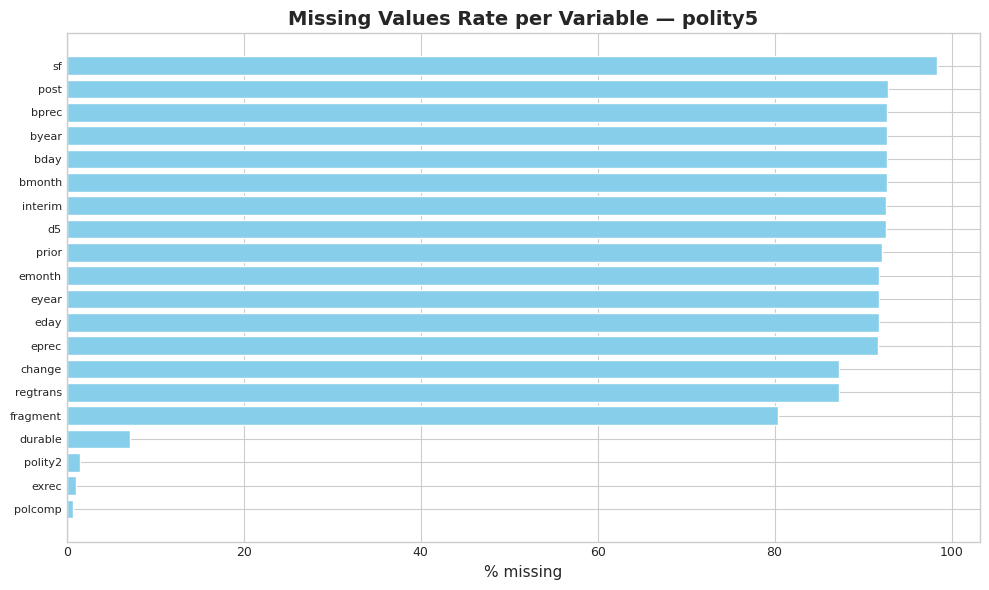

In [16]:
# ============================================================
# 3.2 Missing Values (Diagnostic)
# ============================================================
missing = df_pol.isnull().sum()
missing_pct = (missing / len(df_pol) * 100).round(2)
missing_df_pol = pd.DataFrame({"Missing": missing, "Percentage (%)": missing_pct})
missing_df_pol = missing_df_pol.sort_values("Percentage (%)", ascending=True)

display(missing_df_pol[missing_df_pol['Missing'] > 0])

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(missing_df_pol[missing_df_pol['Missing'] > 0].index, missing_df_pol[missing_df_pol['Missing'] > 0]["Percentage (%)"], color="skyblue")
ax.set_xlabel("% missing")
ax.set_title("Missing Values Rate per Variable — polity5")
plt.tight_layout()
plt.show()

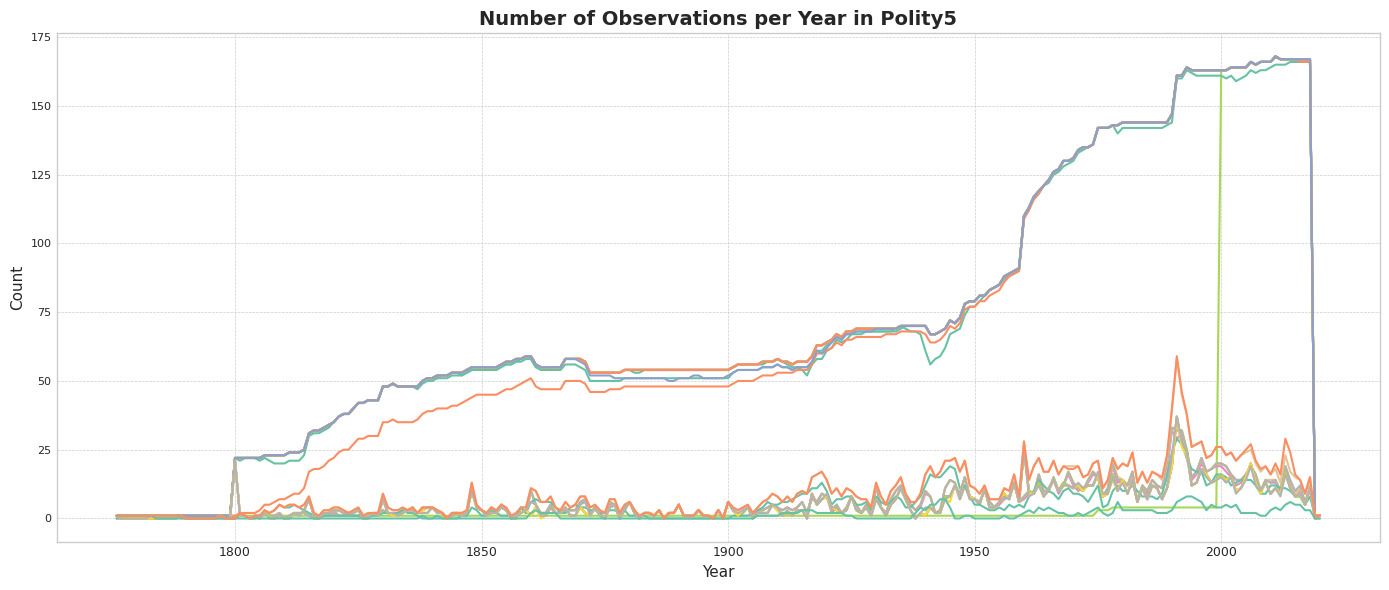

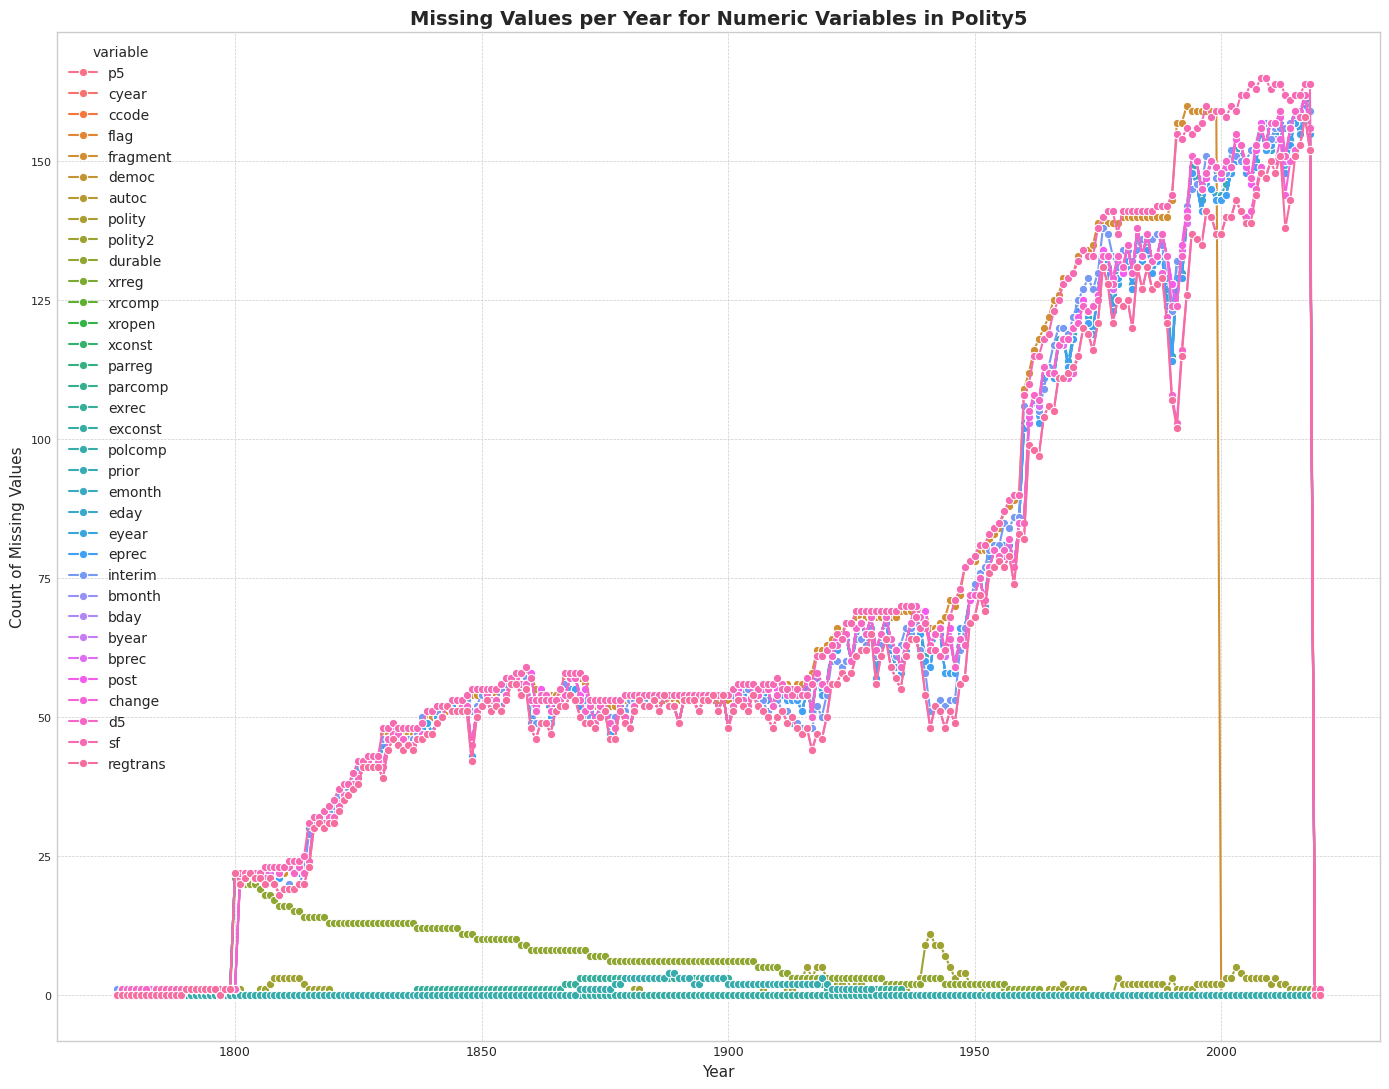

In [17]:
numeric_cols = df_pol.select_dtypes(include=np.number).columns


grouped = df_pol.groupby('year')[numeric_cols[~numeric_cols.isin(['year'])]].agg(['count', 'min', 'max']).reset_index()
plt.figure(figsize=(14, 6)) 
plt.plot(grouped['year'], grouped[(numeric_cols[~numeric_cols.isin(['year'])][0], 'count')], label=numeric_cols[~numeric_cols.isin(['year'])][0])
for col in numeric_cols[~numeric_cols.isin(['year'])][1:]:
    plt.plot(grouped['year'], grouped[(col, 'count')], label=col)
plt.title('Number of Observations per Year in Polity5')
plt.xlabel('Year')
plt.ylabel('Count')
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.tight_layout()
plt.show()
#missing values of each numeric variable per year
missing_yearly = df_pol.groupby('year')[numeric_cols[~numeric_cols.isin(['year'])]].apply(lambda x: x.isnull().sum()).reset_index()
missing_yearly_melted = missing_yearly.melt(id_vars='year', var_name='variable', value_name='missing_count')
plt.figure(figsize=(14, 11))
sns.lineplot(data=missing_yearly_melted, x='year', y='missing_count', hue='variable', marker='o')
plt.title('Missing Values per Year for Numeric Variables in Polity5')
plt.xlabel('Year')
plt.ylabel('Count of Missing Values')
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.tight_layout()
plt.show()

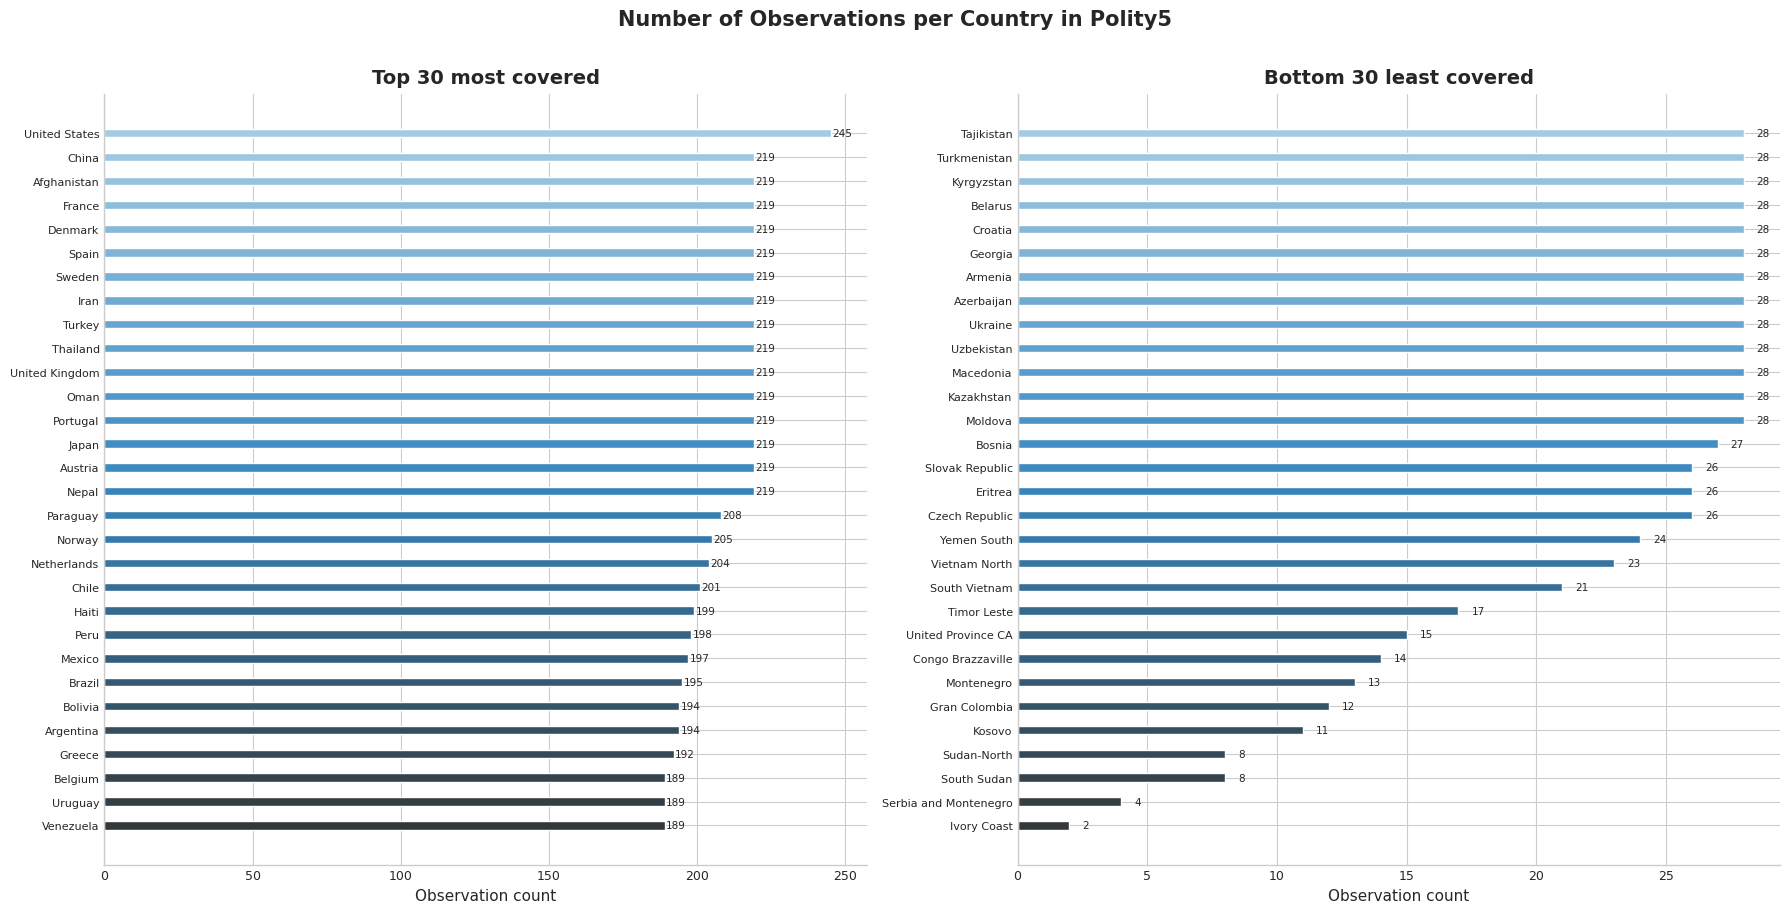

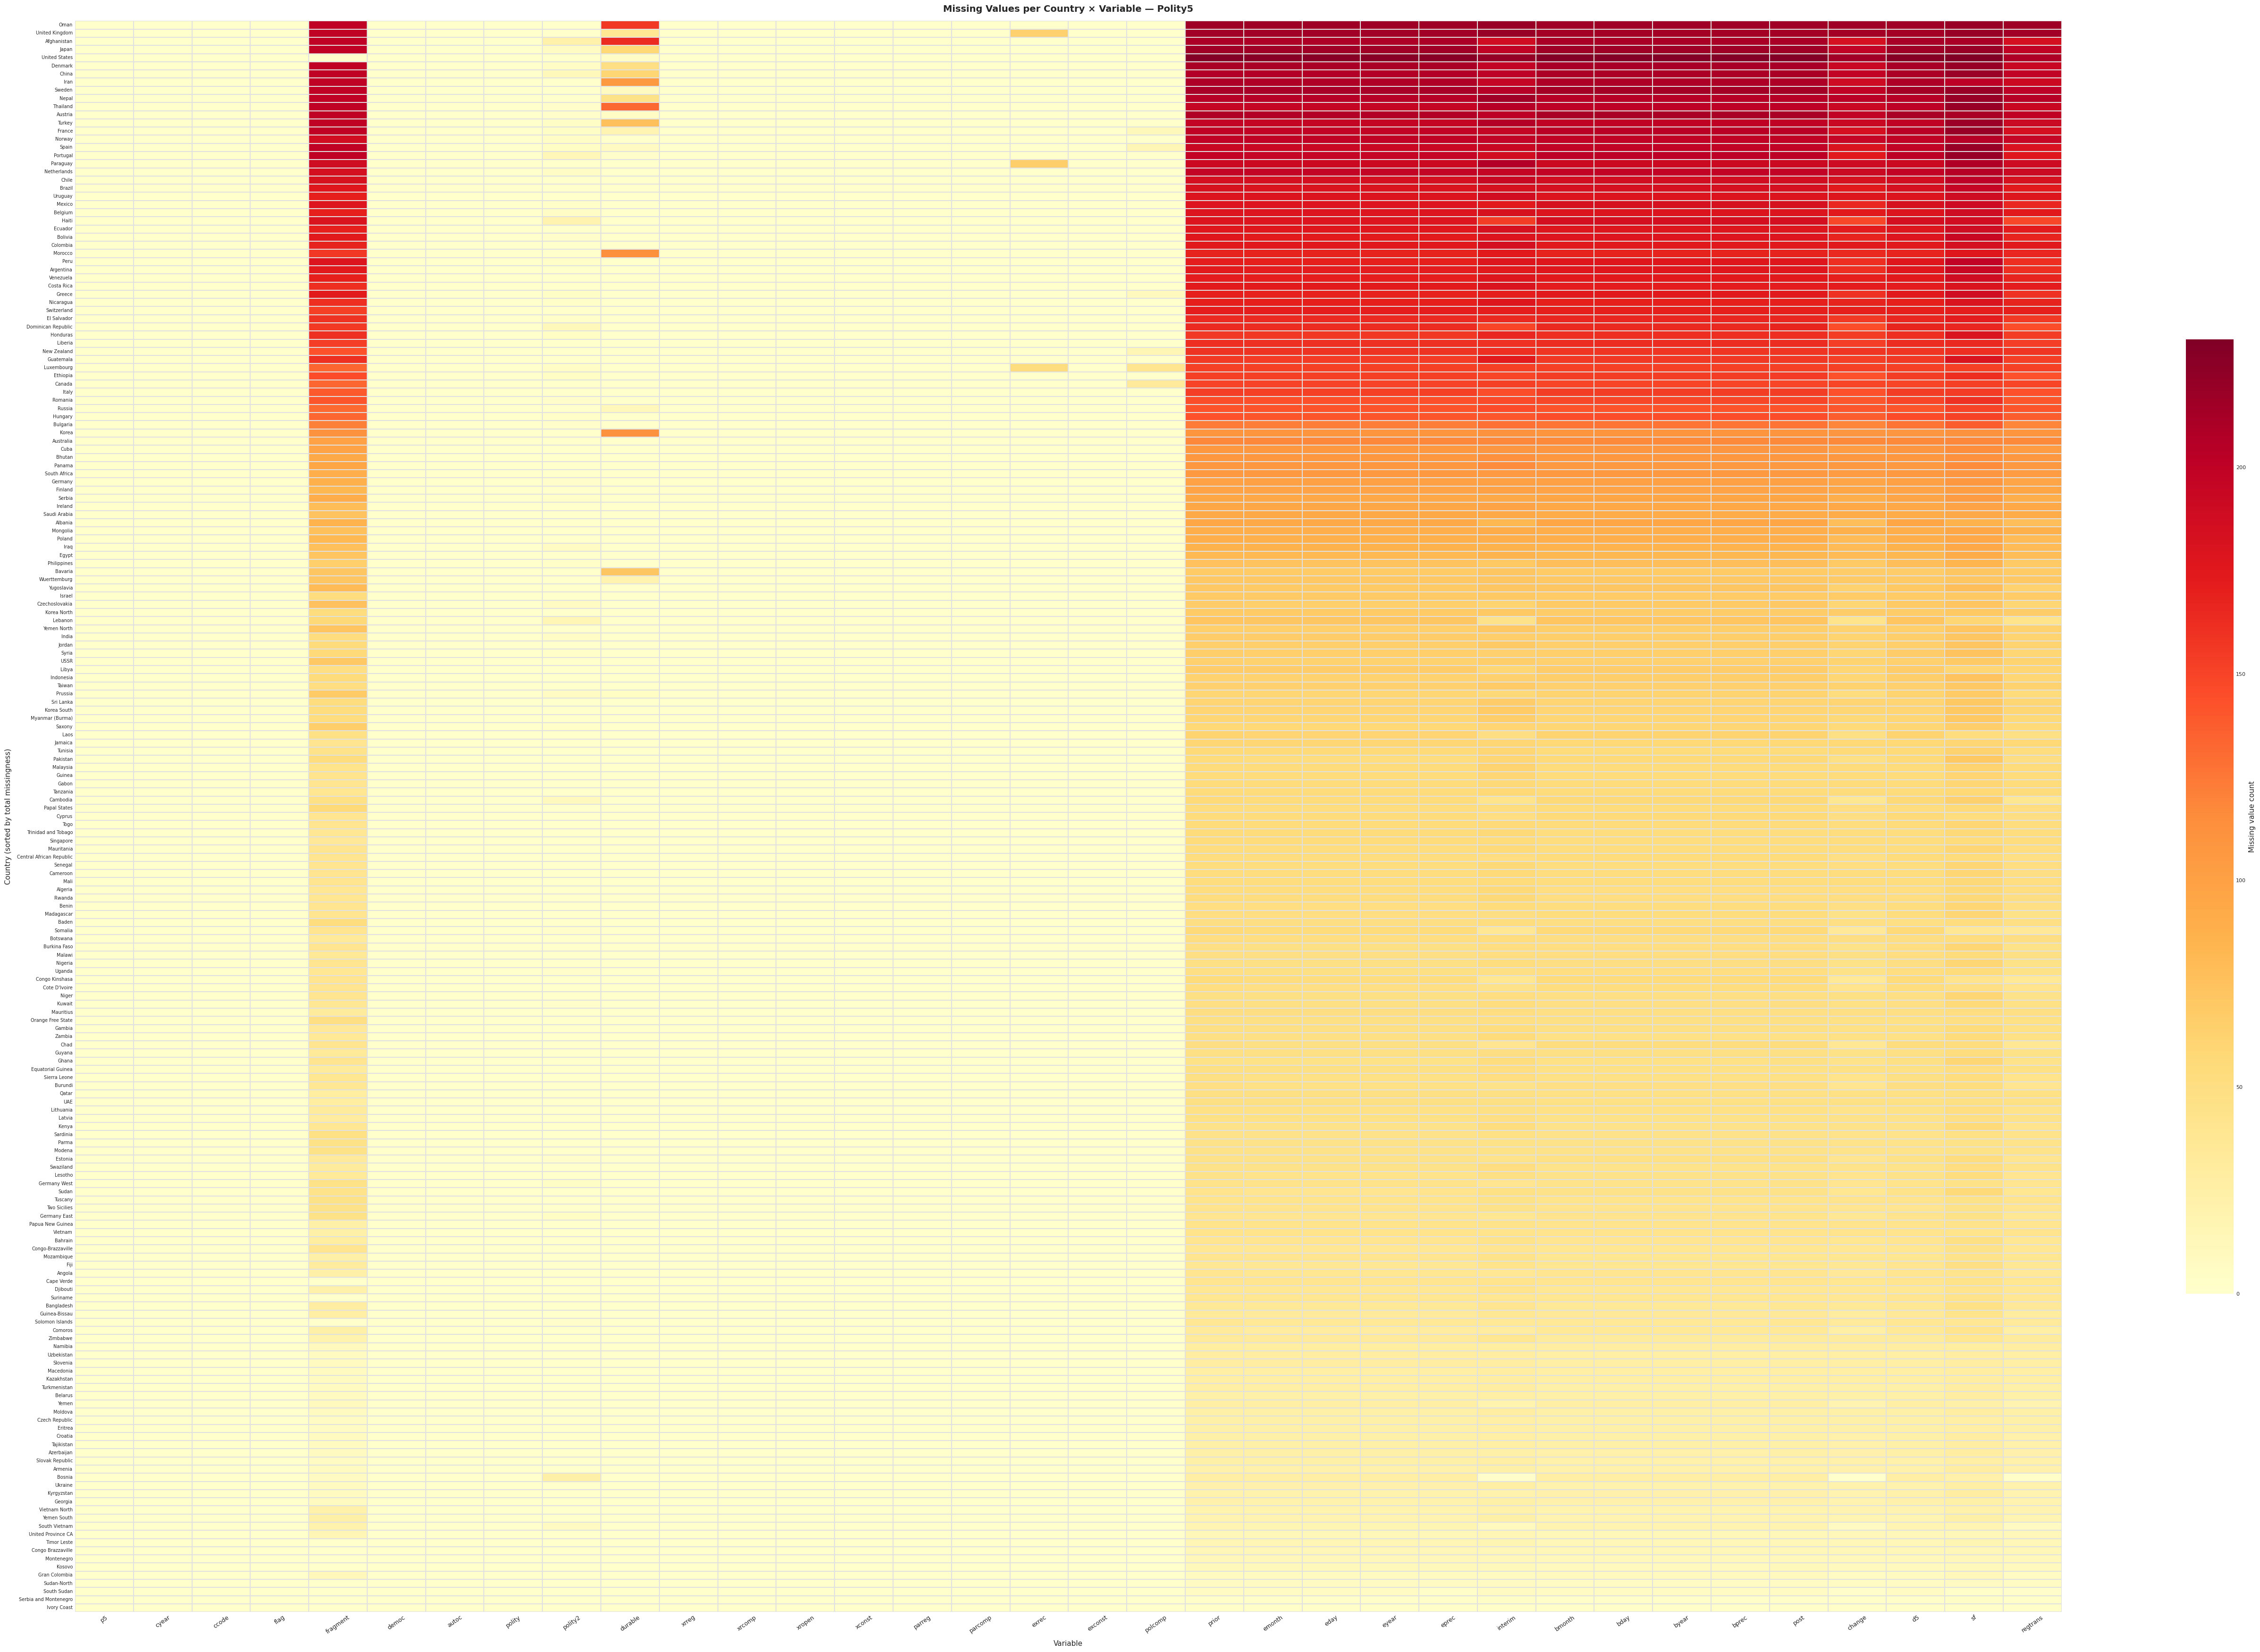

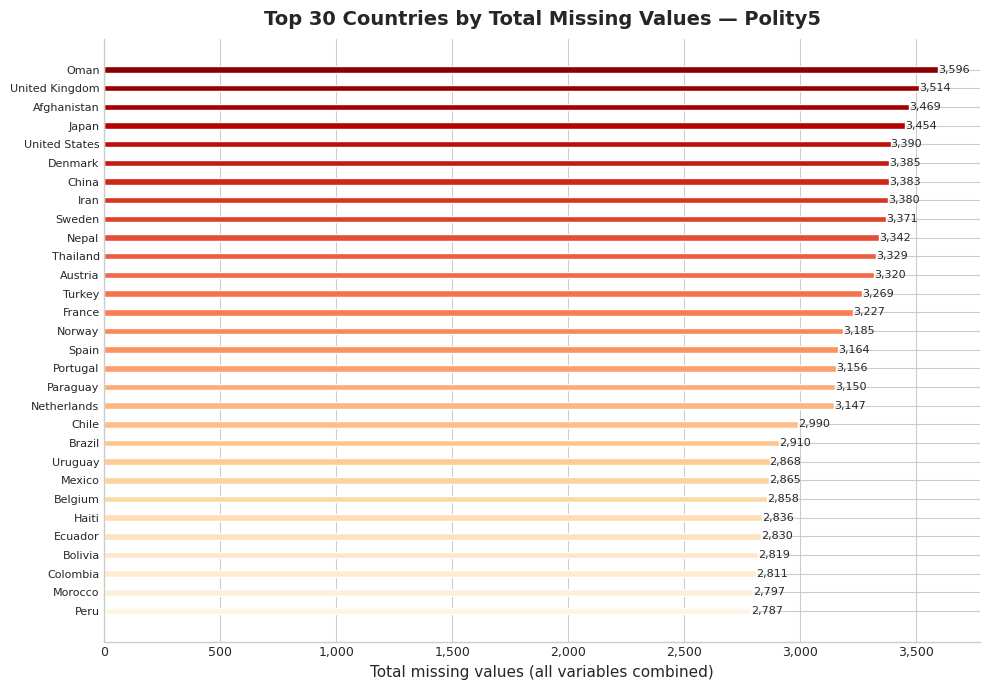

In [18]:
# ── Config ────────────────────────────────────────────────────────────────────
STYLE   = "seaborn-v0_8-whitegrid"
PALETTE = "Blues_d"
FIG_W   = 18          # base width for wide charts
BAR_H   = 0.35        # bar height for horizontal bars
TOP_N   = 30          # show top-N countries per chart (avoids 200-country clutter)

plt.style.use(STYLE)
plt.rcParams.update({
    "font.family"      : "DejaVu Sans",
    "axes.titlesize"   : 14,
    "axes.titleweight" : "bold",
    "axes.labelsize"   : 11,
    "xtick.labelsize"  : 9,
    "ytick.labelsize"  : 8,
})

non_year_cols = numeric_cols[~numeric_cols.isin(['year'])].tolist()

# ── 1. Observation count — horizontal bar (top 30 + bottom 30) ────────────────
count_df = (
    df_pol.groupby('country_name')[non_year_cols[0]]
    .count()
    .rename('obs_count')
    .reset_index()
    .sort_values('obs_count', ascending=False)
)

fig, axes = plt.subplots(1, 2, figsize=(FIG_W, 9), sharey=False)
fig.suptitle("Number of Observations per Country in Polity5", fontsize=15, fontweight="bold", y=1.01)

for ax, (label, subset) in zip(
    axes,
    [("Top 30 most covered", count_df.head(TOP_N)),
     ("Bottom 30 least covered", count_df.tail(TOP_N))]
):
    colors = sns.color_palette(PALETTE, len(subset))
    ax.barh(subset['country_name'][::-1], subset['obs_count'][::-1], color=colors[::-1], height=BAR_H)
    ax.set_title(label, pad=8)
    ax.set_xlabel("Observation count")
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
    # value labels on bars
    for bar in ax.patches:
        ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height() / 2,
                f"{int(bar.get_width()):,}", va='center', ha='left', fontsize=7.5)
    ax.spines[['top','right']].set_visible(False)

plt.tight_layout()
plt.show()

# ── 2. Missing values — heatmap (all countries, all variables) ────────────────
missing_df = (
    df_pol.groupby('country_name')[non_year_cols]
    .apply(lambda x: x.isnull().sum())
)

# Sort countries by total missingness so structure is visible
missing_df = missing_df.loc[missing_df.sum(axis=1).sort_values(ascending=False).index]

fig_h = max(10, len(missing_df) * 0.18)   # auto-scale height
fig, ax = plt.subplots(figsize=(max(10, len(non_year_cols) * 1.6), fig_h))

sns.heatmap(
    missing_df,
    ax=ax,
    cmap="YlOrRd",
    linewidths=0.3,
    linecolor="#e0e0e0",
    cbar_kws={"label": "Missing value count", "shrink": 0.6},
    annot=(len(missing_df) <= 60),   # annotate only when readable
    fmt=".0f",
    annot_kws={"size": 6},
)
ax.set_title("Missing Values per Country × Variable — Polity5", pad=14, fontsize=14, fontweight="bold")
ax.set_xlabel("Variable", labelpad=8)
ax.set_ylabel("Country (sorted by total missingness)", labelpad=8)
ax.tick_params(axis='x', rotation=35, labelsize=9)
ax.tick_params(axis='y', labelsize=7)

plt.tight_layout()
plt.show()

# ── 3. Missing values — top offenders bar chart (actionable summary) ──────────
total_missing = missing_df.sum(axis=1).sort_values(ascending=False).head(TOP_N)

fig, ax = plt.subplots(figsize=(10, 7))
colors = sns.color_palette("OrRd_r", len(total_missing))
ax.barh(total_missing.index[::-1], total_missing.values[::-1], color=colors[::-1], height=BAR_H)
ax.set_title(f"Top {TOP_N} Countries by Total Missing Values — Polity5",
             fontweight="bold", pad=10)
ax.set_xlabel("Total missing values (all variables combined)")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
for bar in ax.patches:
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2,
            f"{int(bar.get_width()):,}", va='center', ha='left', fontsize=8)
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.show()

C:\Users\MSI\AppData\Local\Temp\ipykernel_29224\2623664388.py:56: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


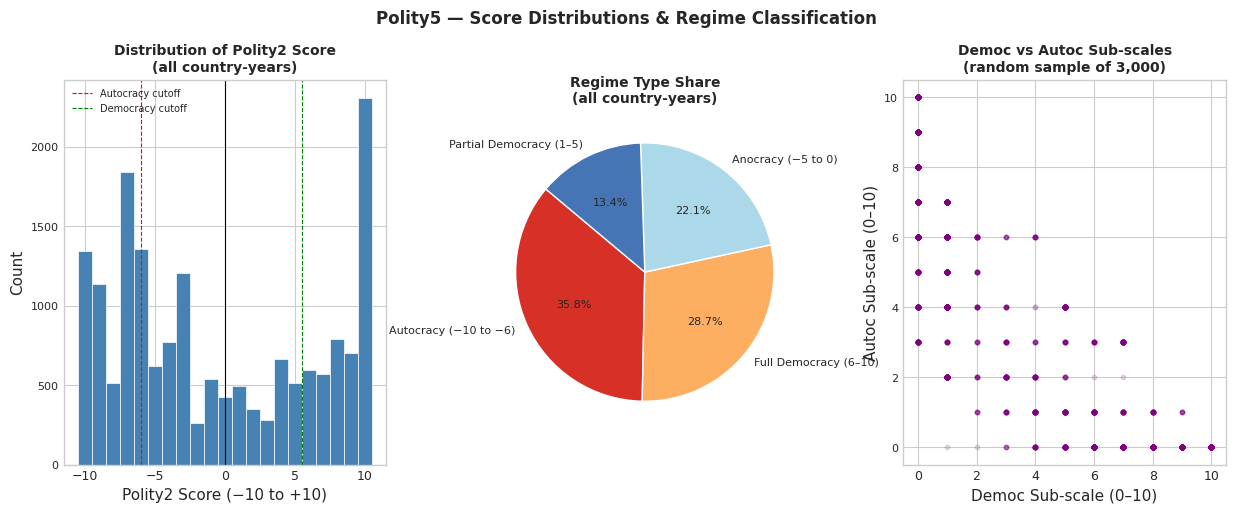

Regime type counts:


,Count
regime_type,
Autocracy (−10 to −6),6194
Full Democracy (6–10),4970
Anocracy (−5 to 0),3830
Partial Democracy (1–5),2313


In [19]:

# Recode special values to NaN for analysis
p5_clean = df_pol.copy()
for col in ['polity2', 'democ', 'autoc', 'polity']:
    p5_clean[col] = p5_clean[col].replace([-66, -77, -88], np.nan)

valid_p2 = p5_clean['polity2'].dropna()

def classify_polity(score):
    if score <= -6:  return 'Autocracy (−10 to −6)'
    elif score <= 0: return 'Anocracy (−5 to 0)'
    elif score <= 5: return 'Partial Democracy (1–5)'
    else:            return 'Full Democracy (6–10)'

p5_clean['regime_type'] = p5_clean['polity2'].apply(
    lambda x: classify_polity(x) if pd.notna(x) else np.nan
)

fig = plt.figure(figsize=(15, 5))
gs  = gridspec.GridSpec(1, 3, figure=fig, wspace=0.3)

# 1 — Histogram of polity2
ax1 = fig.add_subplot(gs[0, 0])
ax1.hist(valid_p2, bins=21, range=(-10.5, 10.5),
            color='steelblue', edgecolor='white', linewidth=0.5)
ax1.axvline(0,   color='black', linestyle='-',  linewidth=0.8)
ax1.axvline(-6,  color='red',   linestyle='--', linewidth=0.8, label='Autocracy cutoff')
ax1.axvline(5.5, color='green', linestyle='--', linewidth=0.8, label='Democracy cutoff')
ax1.set_title('Distribution of Polity2 Score\n(all country-years)',
                fontweight='bold', fontsize=10)
ax1.set_xlabel('Polity2 Score (−10 to +10)')
ax1.set_ylabel('Count')
ax1.legend(fontsize=7)

# 2 — Pie chart of regime types
ax2 = fig.add_subplot(gs[0, 1])
regime_counts = p5_clean['regime_type'].value_counts()
colors_regime = ['#d73027', '#fdae61', '#abd9e9', '#4575b4']
ax2.pie(regime_counts, labels=regime_counts.index,
        autopct='%1.1f%%', colors=colors_regime, startangle=140,
        textprops={'fontsize': 8})
ax2.set_title('Regime Type Share\n(all country-years)', fontweight='bold', fontsize=10)

# 3 — Democ vs Autoc scatter (sample)
ax3 = fig.add_subplot(gs[0, 2])
sample = p5_clean[p5_clean['democ'].notna() & p5_clean['autoc'].notna()].sample(
    min(3000, len(p5_clean)), random_state=42
)
ax3.scatter(sample['democ'], sample['autoc'],
            alpha=0.15, s=10, color='purple')
ax3.set_xlabel('Democ Sub-scale (0–10)')
ax3.set_ylabel('Autoc Sub-scale (0–10)')
ax3.set_title('Democ vs Autoc Sub-scales\n(random sample of 3,000)', fontweight='bold', fontsize=10)

plt.suptitle('Polity5 — Score Distributions & Regime Classification',
                fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("Regime type counts:")
display(regime_counts.to_frame('Count'))

### **Interpretation :**
The polity2 histogram shows a bimodal distribution: one peak near −10 (hard autocracies) and another near +10 (consolidated democracies), with a dip in the anocratic middle — consistent with the "two-peak" pattern documented in the democratization literature. Autocracies account for the largest share of country-years historically. The democ-vs-autoc scatter confirms they are not simply mirror images;high-democ, low-autoc cases (top-left) represent consolidated democracies,while low-democ, high-autoc cases cluster toward hard autocracies.

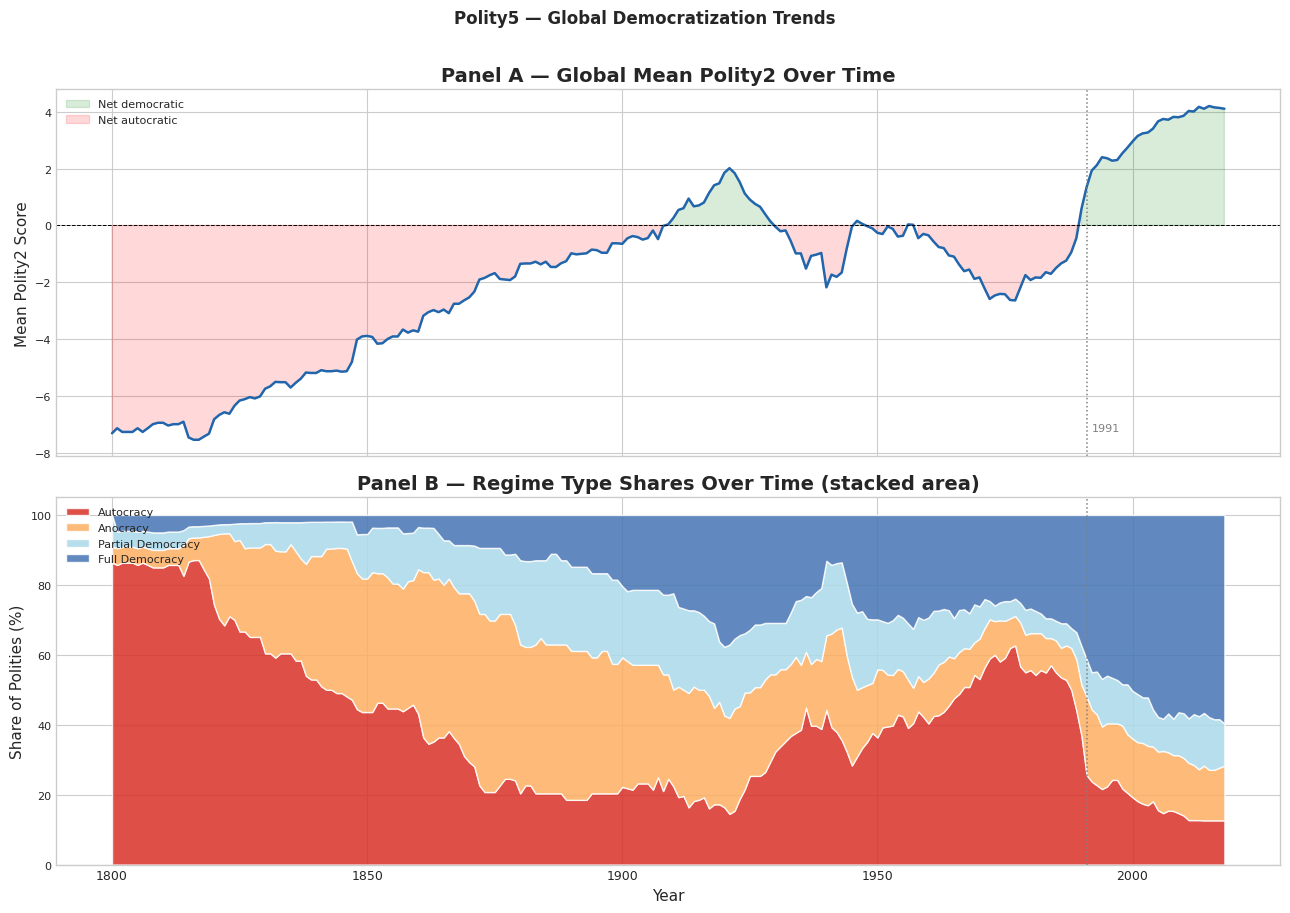

In [20]:
p5_clean = df_pol.copy()
for col in ['polity2', 'democ', 'autoc']:
    p5_clean[col] = p5_clean[col].replace([-66, -77, -88], np.nan)

def classify_polity(score):
    if pd.isna(score):  return np.nan
    if score <= -6:     return 'Autocracy'
    elif score <= 0:    return 'Anocracy'
    elif score <= 5:    return 'Partial Democracy'
    else:               return 'Full Democracy'

p5_clean['regime_type'] = p5_clean['polity2'].apply(classify_polity)

# Filter to years with ≥ 10 polities observed
yr_count = p5_clean.groupby('year')['ccode'].nunique()
valid_yrs = yr_count[yr_count >= 10].index
pt = p5_clean[p5_clean['year'].isin(valid_yrs)]

# Annual mean polity2
annual_p2 = pt.groupby('year')['polity2'].mean()

# Annual regime share
regime_shares = (
    pt.dropna(subset=['regime_type'])
        .groupby(['year', 'regime_type'])
        .size()
        .unstack(fill_value=0)
)
regime_shares = regime_shares.div(regime_shares.sum(axis=1), axis=0) * 100

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 9), sharex=True)

# Panel A: mean polity2
ax1.plot(annual_p2.index, annual_p2.values, color='#2166ac', linewidth=1.8)
ax1.axhline(0, color='black', linewidth=0.7, linestyle='--')
ax1.fill_between(annual_p2.index, annual_p2.values, 0,
                    where=(annual_p2.values > 0), alpha=0.15, color='green', label='Net democratic')
ax1.fill_between(annual_p2.index, annual_p2.values, 0,
                    where=(annual_p2.values < 0), alpha=0.15, color='red', label='Net autocratic')
ax1.axvline(1991, color='gray', linestyle=':', linewidth=1.1)
ax1.text(1992, annual_p2.min() + 0.3, '1991', color='gray', fontsize=8)
ax1.set_ylabel('Mean Polity2 Score')
ax1.set_title('Panel A — Global Mean Polity2 Over Time', fontweight='bold')
ax1.legend(fontsize=8)

# Panel B: stacked area of regime shares
colors_map = {
    'Autocracy':        '#d73027',
    'Anocracy':         '#fdae61',
    'Partial Democracy':'#abd9e9',
    'Full Democracy':   '#4575b4'
}
present_regimes = [r for r in ['Autocracy', 'Anocracy', 'Partial Democracy', 'Full Democracy']
                    if r in regime_shares.columns]
ax2.stackplot(
    regime_shares.index,
    [regime_shares[r] for r in present_regimes],
    labels=present_regimes,
    colors=[colors_map[r] for r in present_regimes],
    alpha=0.85
)
ax2.axvline(1991, color='gray', linestyle=':', linewidth=1.1)
ax2.set_ylabel('Share of Polities (%)')
ax2.set_xlabel('Year')
ax2.set_title('Panel B — Regime Type Shares Over Time (stacked area)',
                fontweight='bold')
ax2.legend(loc='upper left', fontsize=8)

plt.suptitle('Polity5 — Global Democratization Trends', fontsize=12,
                fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### **Interpretation :**
Panel A shows that the world average polity2 was negative (net autocratic) through most of the 20th century and crossed zero only after the end of the Cold War in 1991.  Panel B confirms this: full democracies were rare before 1990 and their share expanded sharply in the 1990s–2000s.  The autocracy share declined but did not disappear, suggesting that democratization was partial and uneven. The stacked area chart is the canonical visualization of Polity5's contribution to the "third wave" literature.

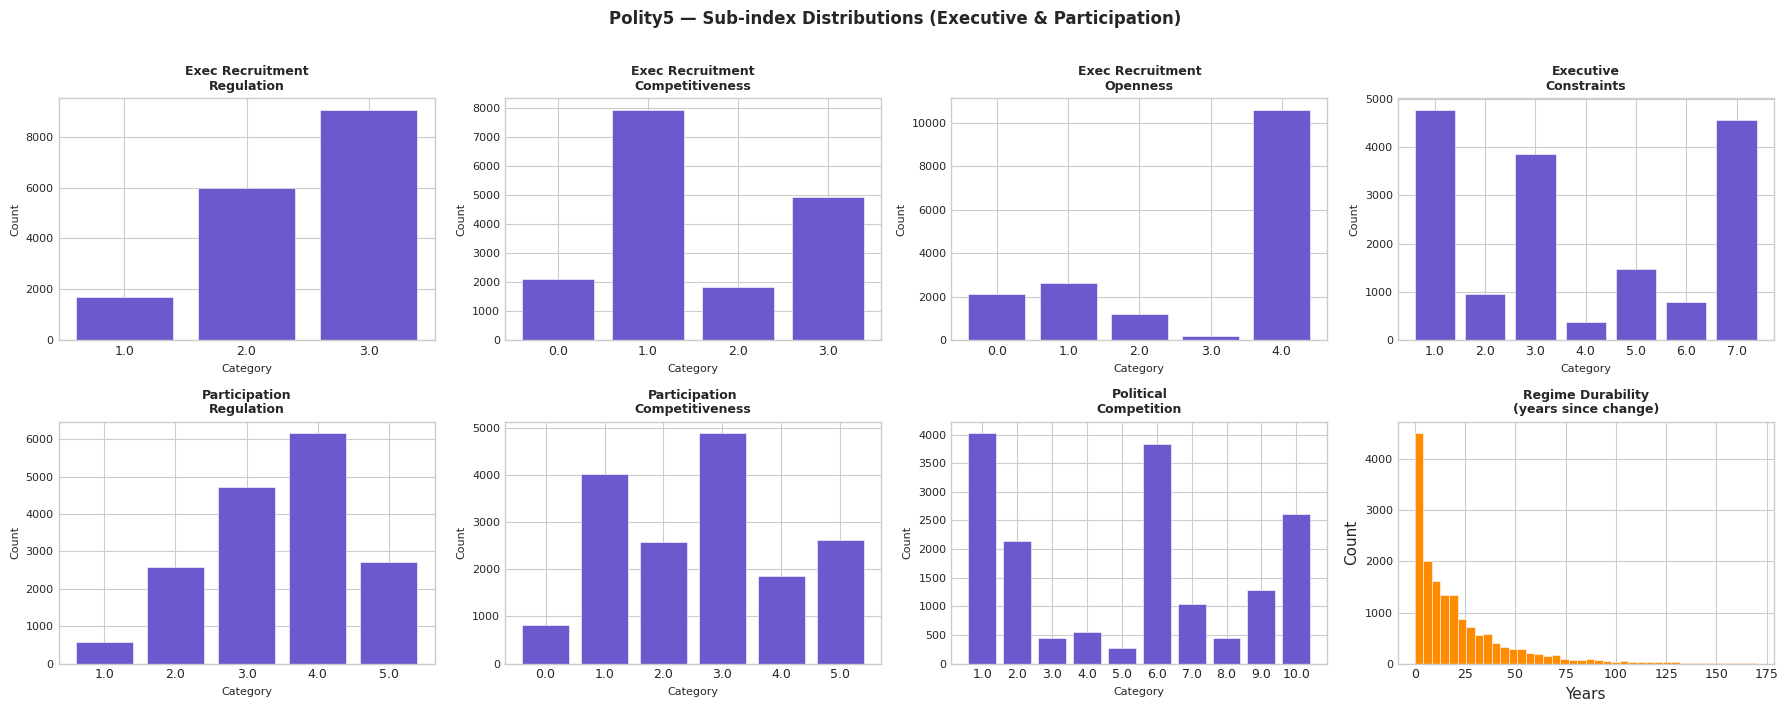

In [21]:
p5_sub = df_pol.copy()
for col in ['xrreg', 'xrcomp', 'xropen', 'xconst',
            'parreg', 'parcomp', 'exrec', 'exconst', 'polcomp']:
    p5_sub[col] = p5_sub[col].replace([-66, -77, -88], np.nan)

sub_cols = ['xrreg', 'xrcomp', 'xropen', 'xconst',
            'parreg', 'parcomp', 'polcomp']
labels_sub = {
    'xrreg':   'Exec Recruitment\nRegulation',
    'xrcomp':  'Exec Recruitment\nCompetitiveness',
    'xropen':  'Exec Recruitment\nOpenness',
    'xconst':  'Executive\nConstraints',
    'parreg':  'Participation\nRegulation',
    'parcomp': 'Participation\nCompetitiveness',
    'polcomp': 'Political\nCompetition'
}

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
axes = axes.flatten()

for i, col in enumerate(sub_cols):
    if col in p5_sub.columns:
        counts = p5_sub[col].dropna().value_counts().sort_index()
        axes[i].bar(counts.index.astype(str), counts.values,
                    color='slateblue', edgecolor='white', linewidth=0.4)
        axes[i].set_title(labels_sub.get(col, col), fontsize=9, fontweight='bold')
        axes[i].set_xlabel('Category', fontsize=8)
        axes[i].set_ylabel('Count', fontsize=8)
    else:
        axes[i].set_visible(False)

# Last subplot: durable (regime stability)
ax_dur = axes[len(sub_cols)]
dur = df_pol['durable'].replace([-66, -77, -88], np.nan).dropna()
ax_dur.hist(dur, bins=40, color='darkorange', edgecolor='white', linewidth=0.4)
ax_dur.set_title('Regime Durability\n(years since change)', fontsize=9, fontweight='bold')
ax_dur.set_xlabel('Years')
ax_dur.set_ylabel('Count')

for j in range(len(sub_cols) + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Polity5 — Sub-index Distributions (Executive & Participation)',
                fontsize=12, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### **Interpretation :**
The sub-indices reveal granular institutional patterns:
- **Executive Constraints (xconst)** is highly skewed — category 1 (unlimited authority) and 7 (parity) dominate, with little middle ground.
- **Participation Regulation (parreg)** shows that restricted/ suppressed participation is most common historically.
- **Regime Durability** is strongly right-skewed: most regimes are young (<10 years since last change), while a handful of stable democracies accumulate very high durable scores.  These sub-indices will serve as candidate features in the predictive model.

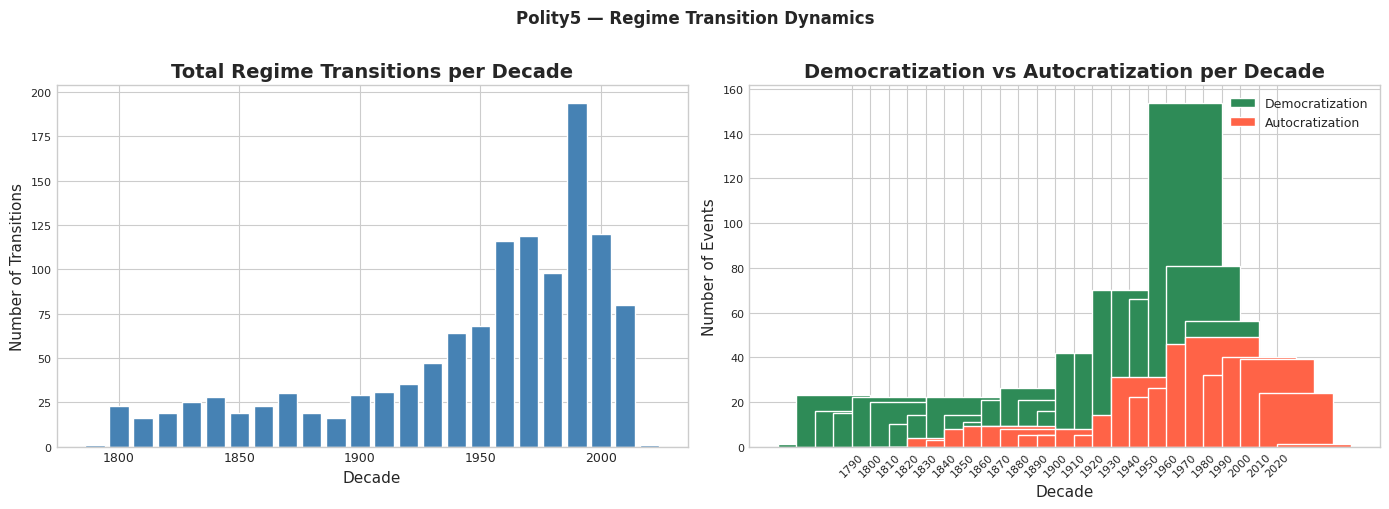


Total regime transitions detected: 1221

Transition direction counts:


,Count
direction,
Democratization,833
Autocratization,388


In [22]:
p5_trans = df_pol.copy()
p5_trans['polity2'] = p5_trans['polity2'].replace([-66, -77, -88], np.nan)

# Identify transition years: rows where change != 0 and is not NaN
transitions = p5_trans[
    p5_trans['change'].notna() &
    (p5_trans['change'] != 0) &
    (~p5_trans['change'].isin([-66, -77, -88]))
].copy()

# Count transitions per decade
transitions['decade'] = (transitions['year'] // 10) * 10
decade_trans = transitions.groupby('decade').size().reset_index(name='n_transitions')

# Polity2 shift at transition
transitions['direction'] = transitions['change'].apply(
    lambda x: 'Democratization' if x > 0 else 'Autocratization'
)
dir_by_decade = (
    transitions.groupby(['decade', 'direction'])
                .size()
                .unstack(fill_value=0)
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Total transitions per decade
ax1.bar(decade_trans['decade'], decade_trans['n_transitions'],
        width=8, color='steelblue', edgecolor='white')
ax1.set_title('Total Regime Transitions per Decade', fontweight='bold')
ax1.set_xlabel('Decade')
ax1.set_ylabel('Number of Transitions')

# Democratization vs Autocratization per decade
decades = dir_by_decade.index
w = 4
x = np.arange(len(decades))
if 'Democratization' in dir_by_decade.columns:
    ax2.bar(x - w/2, dir_by_decade['Democratization'], width=w,
            color='seagreen', label='Democratization')
if 'Autocratization' in dir_by_decade.columns:
    ax2.bar(x + w/2, dir_by_decade['Autocratization'], width=w,
            color='tomato', label='Autocratization')
ax2.set_xticks(x)
ax2.set_xticklabels(decades, rotation=45, fontsize=8)
ax2.set_title('Democratization vs Autocratization per Decade', fontweight='bold')
ax2.set_xlabel('Decade')
ax2.set_ylabel('Number of Events')
ax2.legend(fontsize=9)

plt.suptitle('Polity5 — Regime Transition Dynamics', fontsize=12,
                fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

print(f"\nTotal regime transitions detected: {len(transitions)}")
print("\nTransition direction counts:")
display(transitions['direction'].value_counts().to_frame('Count'))

### **Interpretation :**
Regime transitions spiked in the 1990s — the post-Cold War decade — driven almost entirely by democratization events.  The 1960s–70s show a different pattern: more balanced transitions, with coups producing autocratization in Latin America and Africa. After 2010, a subtle rise in autocratization events is visible, consistent with the backsliding literature.  This temporal structure confirms that transition timing should be a key predictor in the model.

### **Bilan :**
- **Data Structure:** Long historical panel (1776–2020), 17,574 rows, 195 polities.  Core variable: polity2 in [−10, +10].
- **Data Quality:** No structural NaN; instead, special sentinel codes (−66, −77, −88) must be recoded to NaN before use.  The `change` and event-date columns are sparsely populated by design.
- **Key Features:**
    - `polity2` is the primary composite score for regime type.
    - `democ` and `autoc` sub-scales add granularity.
    - `durable` is an important stability/inertia covariate.
    - Sub-indices (xconst, parcomp, xropen…) capture institutional mechanisms useful as predictors.
- **Temporal Dynamics:** Strong "third wave" signal post-1991 incipient backsliding post-2010.
- **Implications for Merge:**
    - `ccode` (Correlates-of-War numeric code) is the natural key for merging with ARPD, REIGN, and the UCDP conflict dataset.
   - Post-1946 subsetting recommended to maximize overlap.
   - Special codes in polity2 must be handled before constructing
     the country-year panel.

## 5. EDA — arch Dataset

In [23]:
df_arch = pd.read_csv(PATHS['arch'])
print(f"Successfully loaded arch dataset from: {PATHS['arch']}")
print(f"Shape: {df_arch.shape[0]} rows x {df_arch.shape[1]} columns")
print("\n--- First 5 rows ---")
display(df_arch.head(5))
print("\n--- Column Data Types ---")
display(df_arch.dtypes.to_frame('Type'))

print("\n--- Numeric Columns Summary ---")
display(df_arch.describe(include=np.number))

Successfully loaded arch dataset from: C:\Users\MSI\Desktop\projet stat\data\raw\arch_annual.csv
Shape: 17686 rows x 24 columns

--- First 5 rows ---


,obsid,leadid,ccode,idacr,leader,startdate,enddate,entry,exit,exitcode,...,yrdied,borndate,deathdate,dbpedia.uri,num.entry,num.exit,num.exitcode,num.posttenurefate,fties,ftcur
0,USA-1869,81dcc176-1e42-11e4-b4cd-db5882bf8def,2,USA,Grant,1869-03-04,1869-12-31,Regular,(n_year),.,...,1885,NaN,1885-07-23,http://dbpedia.org/resource/Ulysses_S._Grant,0,.,.,.,NaN,NaN
1,USA-1869,81dcc176-1e42-11e4-b4cd-db5882bf8def,2,USA,Grant,1870-01-01,1870-12-31,(p_year),(n_year),.,...,1885,NaN,1885-07-23,http://dbpedia.org/resource/Ulysses_S._Grant,.,.,.,.,NaN,NaN
2,USA-1869,81dcc176-1e42-11e4-b4cd-db5882bf8def,2,USA,Grant,1871-01-01,1871-12-31,(p_year),(n_year),.,...,1885,NaN,1885-07-23,http://dbpedia.org/resource/Ulysses_S._Grant,.,.,.,.,NaN,NaN
3,USA-1869,81dcc176-1e42-11e4-b4cd-db5882bf8def,2,USA,Grant,1872-01-01,1872-12-31,(p_year),(n_year),.,...,1885,NaN,1885-07-23,http://dbpedia.org/resource/Ulysses_S._Grant,.,.,.,.,NaN,NaN
4,USA-1869,81dcc176-1e42-11e4-b4cd-db5882bf8def,2,USA,Grant,1873-01-01,1873-12-31,(p_year),(n_year),.,...,1885,NaN,1885-07-23,http://dbpedia.org/resource/Ulysses_S._Grant,.,.,.,.,NaN,NaN



--- Column Data Types ---


,Type
obsid,object
leadid,object
ccode,int64
idacr,object
leader,object
startdate,object
enddate,object
entry,object
exit,object
exitcode,object



--- Numeric Columns Summary ---


,ccode,yrborn,yrdied,ftcur
count,17686.000000,17686.000000,17686.000000,1655.000000
mean,412.631856,1894.281635,1040.386012,0.388520
std,254.226810,172.082301,1291.045787,0.487561
min,2.000000,-999.000000,-999.000000,0.000000
25%,200.000000,1874.000000,-777.000000,0.000000
50%,375.000000,1912.000000,1925.000000,0.000000
75%,645.000000,1937.000000,1975.000000,1.000000
max,950.000000,1983.000000,2015.000000,1.000000


In [24]:
# Sentinel-coded missings → NaN
SENTINELS = [-999, -888, -777, -666]
df_arch.replace(SENTINELS, np.nan, inplace=True)
 
# Placeholder "." string → NaN (used in exitcode, posttenurefate, etc.)
df_arch.replace(".", np.nan, inplace=True)
 
# Numeric columns stored as strings → coerce
for col in ["num.entry", "num.exit", "num.exitcode", "num.posttenurefate",
            "prevtimesinoffice"]:
    df_arch[col] = pd.to_numeric(df_arch[col], errors="coerce")
 
# Parse dates
for col in ["startdate", "enddate", "borndate", "deathdate"]:
    df_arch[col] = pd.to_datetime(df_arch[col], errors="coerce")
 
# Derive tenure length (years) and birth year
df_arch["tenure_years"] = (df_arch["enddate"] - df_arch["startdate"]).dt.days / 365.25
df_arch["birth_year"]   = df_arch["borndate"].dt.year.fillna(df_arch["yrborn"].replace(-999, np.nan))
 
print("Dataset shape:", df_arch.shape)
print("\nColumn dtypes:\n", df_arch.dtypes.to_string())

Dataset shape: (17686, 26)

Column dtypes:
 obsid                         object
leadid                        object
ccode                          int64
idacr                         object
leader                        object
startdate             datetime64[ns]
enddate               datetime64[ns]
entry                         object
exit                          object
exitcode                      object
prevtimesinoffice            float64
posttenurefate                object
gender                        object
yrborn                       float64
yrdied                       float64
borndate              datetime64[ns]
deathdate             datetime64[ns]
dbpedia.uri                   object
num.entry                    float64
num.exit                     float64
num.exitcode                 float64
num.posttenurefate           float64
fties                         object
ftcur                        float64
tenure_years                 float64
birth_year                   fl

,Missing,Percentage (%)
enddate,1,0.01
tenure_years,1,0.01
yrborn,59,0.33
birth_year,59,0.33
borndate,5180,29.29
yrdied,5924,33.50
dbpedia.uri,8552,48.35
deathdate,11762,66.50
prevtimesinoffice,14277,80.72
posttenurefate,14277,80.72


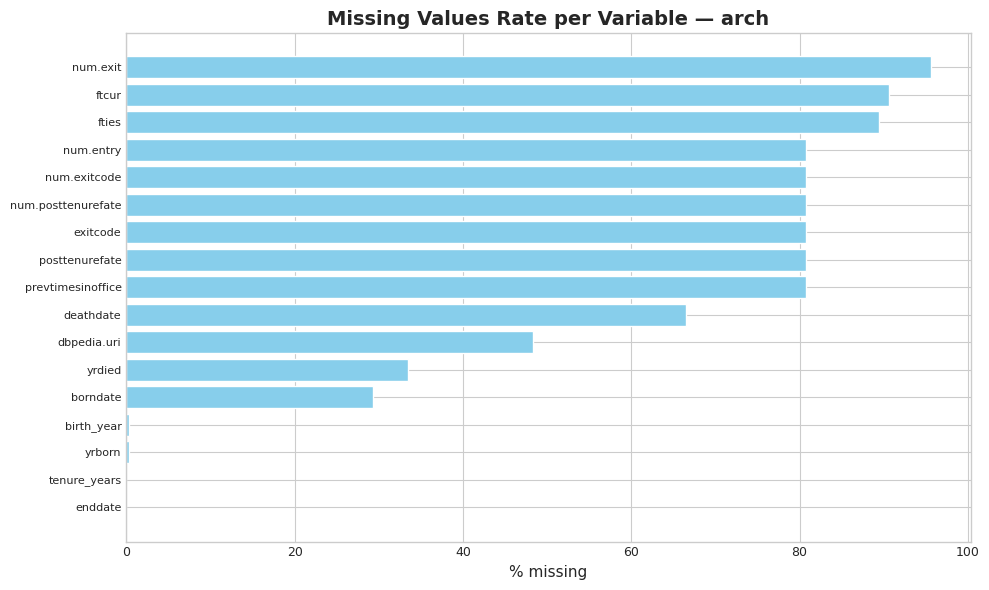

In [25]:
# ============================================================
# 3.2 Missing Values (Diagnostic)
# ============================================================
missing = df_arch.isnull().sum()
missing_pct = (missing / len(df_arch) * 100).round(2)
missing_df_arch = pd.DataFrame({"Missing": missing, "Percentage (%)": missing_pct})
missing_df_arch = missing_df_arch.sort_values("Percentage (%)", ascending=True)

display(missing_df_arch[missing_df_arch['Missing'] > 0])

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(missing_df_arch[missing_df_arch['Missing'] > 0].index, missing_df_arch[missing_df_arch['Missing'] > 0]["Percentage (%)"], color="skyblue")
ax.set_xlabel("% missing")
ax.set_title("Missing Values Rate per Variable — arch")
plt.tight_layout()
plt.show()

In [26]:
print("\n── Basic stats ─────────────────────────────────────────")
print(f"  Rows        : {len(df_arch):,}")
print(f"  Columns     : {df_arch.shape[1]}")
print(f"  Leaders     : {df_arch['leader'].nunique():,} unique")
print(f"  Countries   : {df_arch['idacr'].nunique():,}")
print(f"  Year range  : {df_arch['startdate'].dt.year.min():.0f}–"
      f"{df_arch['enddate'].dt.year.max():.0f}")
print(f"  Gender split: M={df_arch['gender'].eq('M').sum():,}  "
      f"F={df_arch['gender'].eq('F').sum():,}")


── Basic stats ─────────────────────────────────────────
  Rows        : 17,686
  Columns     : 26
  Leaders     : 2,757 unique
  Countries   : 189
  Year range  : 1840–2015
  Gender split: M=17,363  F=323


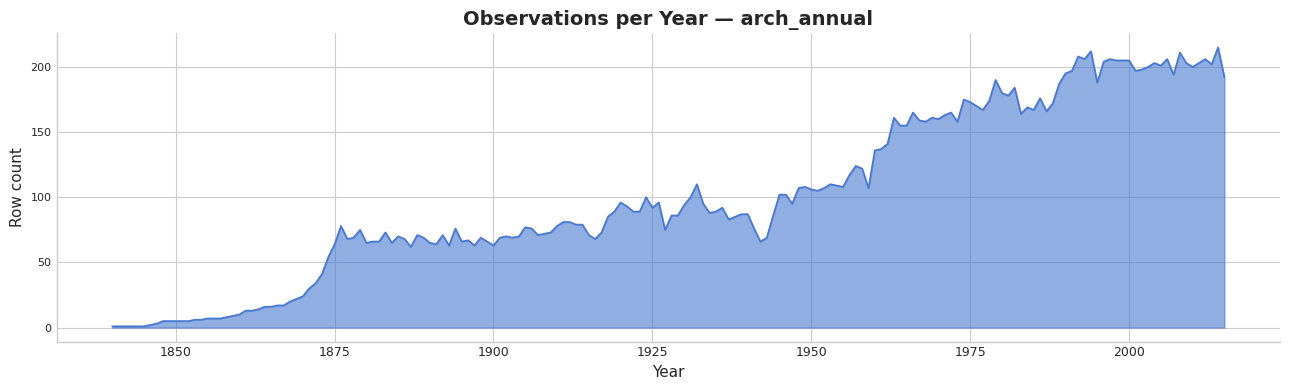

In [27]:
df_arch["obs_year"] = df_arch["startdate"].dt.year

fig, ax = plt.subplots(figsize=(13, 4))
obs_per_year = df_arch["obs_year"].value_counts().sort_index()

COLOR = sns.color_palette("muted")[0]  # RGB tuple, guaranteed safe
# OR just hardcode: COLOR = "#4878d0"

ax.fill_between(obs_per_year.index, obs_per_year.values,
                color=COLOR, alpha=0.6)
ax.plot(obs_per_year.index, obs_per_year.values, color=COLOR, lw=1.2)
ax.set_title("Observations per Year — arch_annual")
ax.set_xlabel("Year")
ax.set_ylabel("Row count")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

<class 'tuple'> (0.2823529411764706, 0.47058823529411764, 0.8156862745098039)


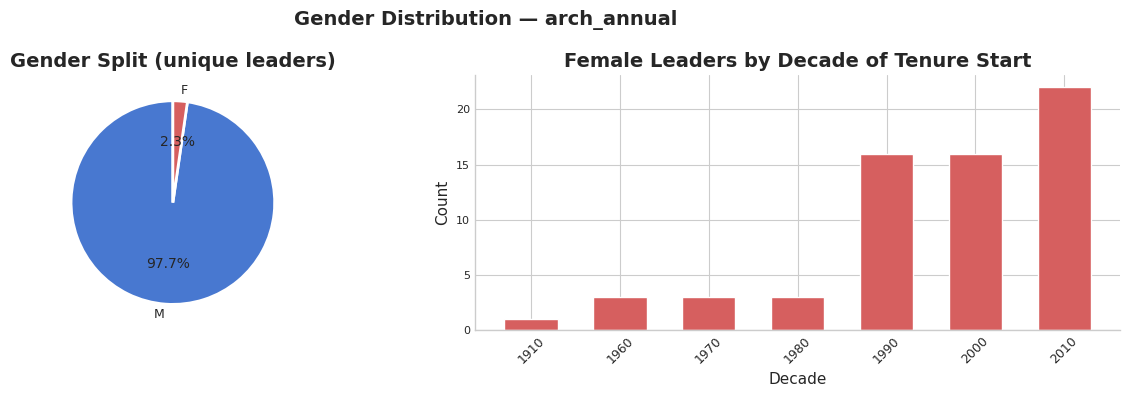

In [28]:
PALETTE = list(sns.color_palette("muted"))
print(type(PALETTE[0]), PALETTE[0])  # should be: <class 'tuple'>  (0.28, 0.47, 0.81)

C1 = sns.color_palette("muted")[0]   # blue  — male
C2 = sns.color_palette("muted")[3]   # red   — female

unique_leaders = df_arch.drop_duplicates("leadid")[["gender", "obs_year"]].copy()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# 4a — pie
gender_counts = unique_leaders["gender"].value_counts()
axes[0].pie(
    gender_counts,
    labels=gender_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=[C1, C2],
    wedgeprops=dict(edgecolor="white", linewidth=2)
)
axes[0].set_title("Gender Split (unique leaders)")

# 4b — female leaders per decade
unique_leaders["decade"] = (unique_leaders["obs_year"] // 10 * 10).astype("Int64")
female_by_decade = (
    unique_leaders[unique_leaders["gender"] == "F"]
    .groupby("decade", observed=True)
    .size()
)
axes[1].bar(female_by_decade.index.astype(str), female_by_decade.values,
            color=C2, width=0.6)
axes[1].set_title("Female Leaders by Decade of Tenure Start")
axes[1].set_xlabel("Decade")
axes[1].set_ylabel("Count")
axes[1].tick_params(axis="x", rotation=45)
axes[1].spines[["top", "right"]].set_visible(False)

fig.suptitle("Gender Distribution — arch_annual", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

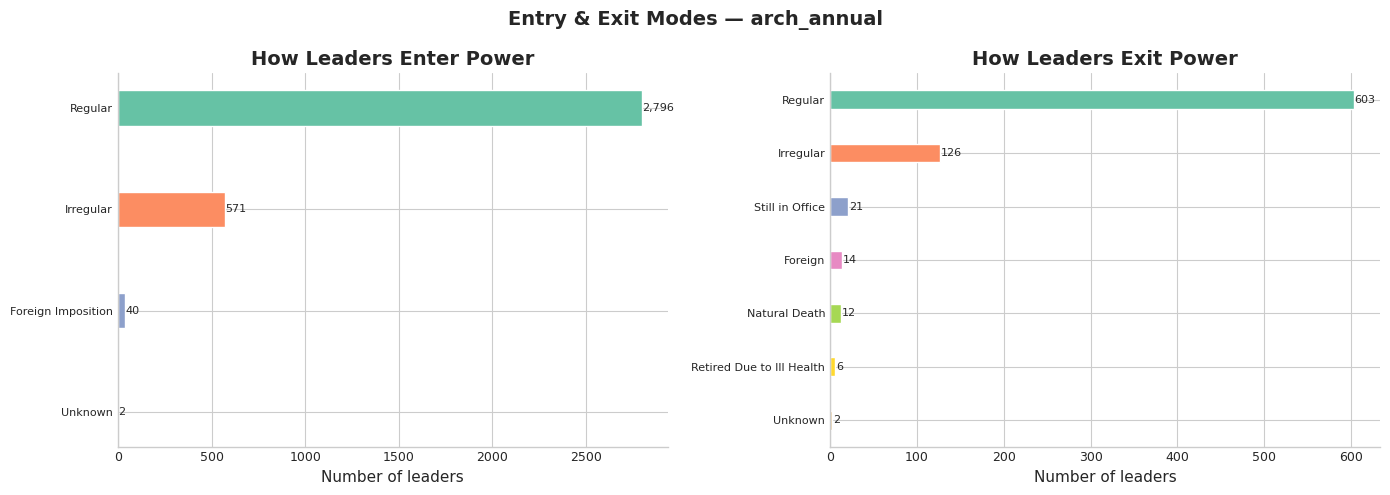

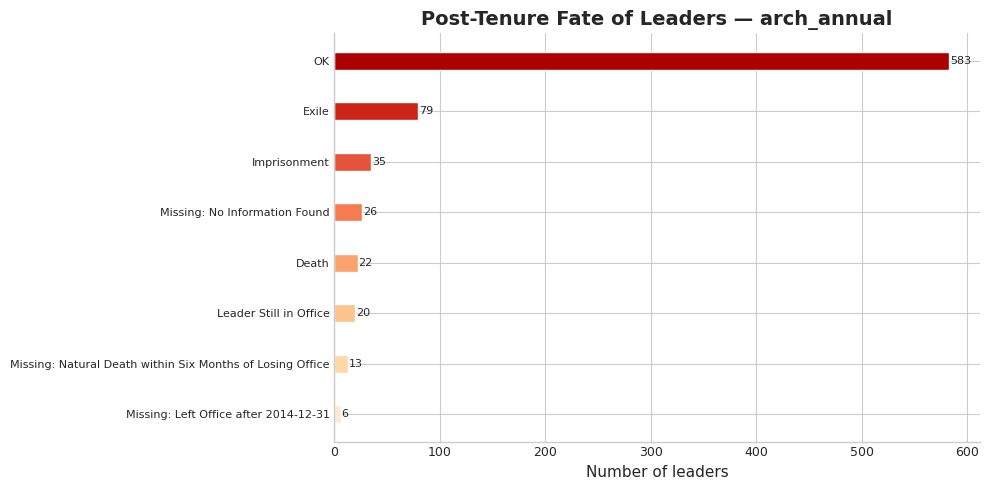

In [29]:
# 5. ENTRY & EXIT MODES
# ─────────────────────────────────────────────────────────────
# Use unique spells (one row per leader tenure, not per year)

spells = df_arch.drop_duplicates("obsid").copy()
 
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
 
for ax, col, title in zip(
    axes,
    ["entry", "exit"],
    ["How Leaders Enter Power", "How Leaders Exit Power"]
):
    counts = spells[col].value_counts(dropna=True)
    # exclude continuations "(p_year)" / "(n_year)"
    counts = counts[~counts.index.str.startswith("(", na=False)]
    colors_bar = sns.color_palette("Set2", len(counts))
    ax.barh(counts.index[::-1], counts.values[::-1],
            color=colors_bar[::-1], height=BAR_H)
    ax.set_title(title)
    ax.set_xlabel("Number of leaders")
    for bar in ax.patches:
        ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2,
                f"{int(bar.get_width()):,}", va="center", fontsize=8)
    ax.spines[["top", "right"]].set_visible(False)
 
fig.suptitle("Entry & Exit Modes — arch_annual", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()
 
# ─────────────────────────────────────────────────────────────
# 6. POST-TENURE FATE
# ─────────────────────────────────────────────────────────────
fate_counts = (spells["posttenurefate"]
               .value_counts(dropna=True)
               .head(10))
 
fig, ax = plt.subplots(figsize=(10, 5))
colors_fate = sns.color_palette("OrRd_r", len(fate_counts))
ax.barh(fate_counts.index[::-1], fate_counts.values[::-1],
        color=colors_fate[::-1], height=BAR_H)
ax.set_title("Post-Tenure Fate of Leaders — arch_annual",
             fontsize=14, fontweight="bold")
ax.set_xlabel("Number of leaders")
for bar in ax.patches:
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2,
            f"{int(bar.get_width()):,}", va="center", fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

C:\Users\MSI\AppData\Local\Temp\ipykernel_29224\524712151.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=tenure_by_entry, x="tenure_years", y="entry",


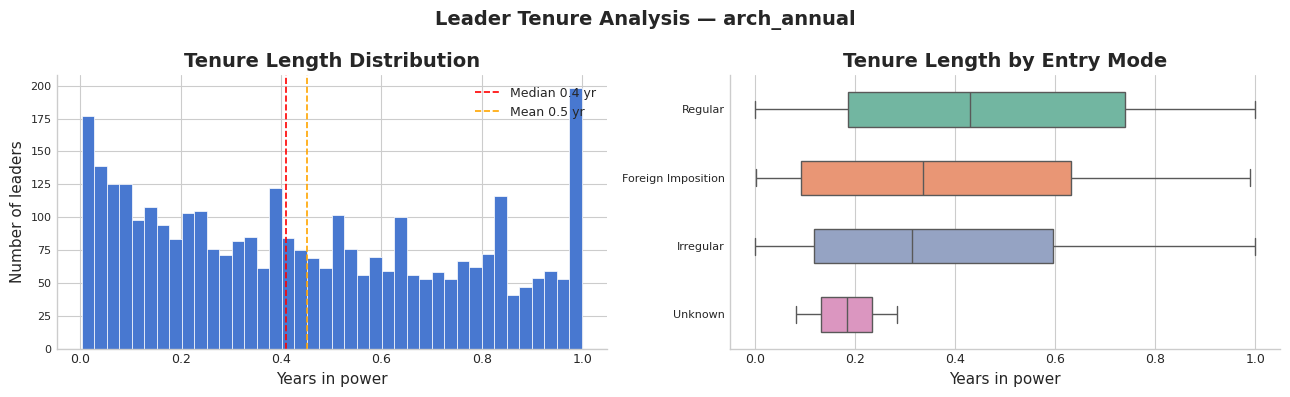


Tenure stats:
count    3395.00
mean        0.45
std         0.31
min         0.00
25%         0.17
50%         0.41
75%         0.71
max         1.00


In [30]:
tenure_data = spells["tenure_years"].dropna()
tenure_data = tenure_data[tenure_data > 0]
 
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
 
# 7a — histogram
axes[0].hist(tenure_data, bins=40, color=PALETTE[0], edgecolor="white", linewidth=0.5)
axes[0].axvline(tenure_data.median(), color="red", linestyle="--",
                linewidth=1.2, label=f"Median {tenure_data.median():.1f} yr")
axes[0].axvline(tenure_data.mean(), color="orange", linestyle="--",
                linewidth=1.2, label=f"Mean {tenure_data.mean():.1f} yr")
axes[0].set_title("Tenure Length Distribution")
axes[0].set_xlabel("Years in power")
axes[0].set_ylabel("Number of leaders")
axes[0].legend(fontsize=9)
axes[0].spines[["top", "right"]].set_visible(False)
 
# 7b — by entry mode (box)
tenure_by_entry = (spells[["entry", "tenure_years"]]
                   .dropna()
                   .query("entry not in ['(p_year)']"))
order = (tenure_by_entry.groupby("entry")["tenure_years"]
         .median()
         .sort_values(ascending=False)
         .index)
sns.boxplot(data=tenure_by_entry, x="tenure_years", y="entry",
            order=order, palette="Set2", ax=axes[1],
            width=0.5, flierprops=dict(marker=".", markersize=3, alpha=0.4))
axes[1].set_title("Tenure Length by Entry Mode")
axes[1].set_xlabel("Years in power")
axes[1].set_ylabel("")
axes[1].spines[["top", "right"]].set_visible(False)
 
fig.suptitle("Leader Tenure Analysis — arch_annual", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()
 
print(f"\nTenure stats:\n{tenure_data.describe().round(2).to_string()}")

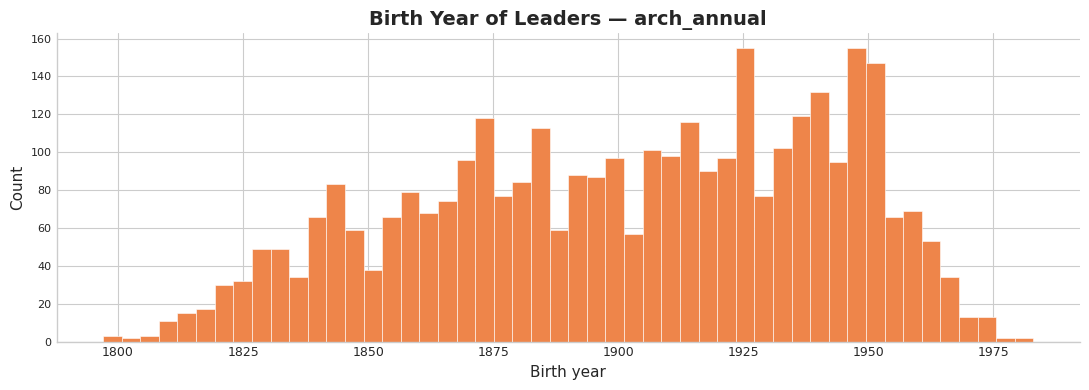

In [31]:
birth_data = spells["birth_year"].dropna()
birth_data = birth_data[birth_data > 1000]   # drop remaining sentinels
 
fig, ax = plt.subplots(figsize=(11, 4))
ax.hist(birth_data, bins=50, color=PALETTE[1], edgecolor="white", linewidth=0.4)
ax.set_title("Birth Year of Leaders — arch_annual",
             fontsize=14, fontweight="bold")
ax.set_xlabel("Birth year")
ax.set_ylabel("Count")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

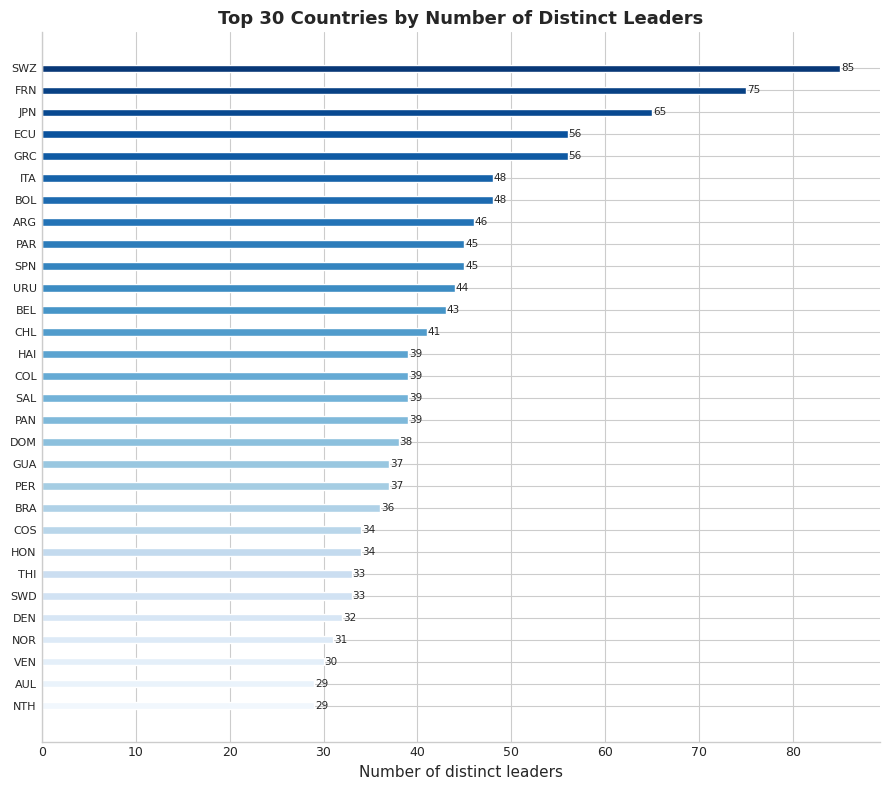

In [32]:
leaders_per_country = (spells.groupby("idacr")["leadid"]
                       .nunique()
                       .sort_values(ascending=False))
 
TOP = 30
top_countries = leaders_per_country.head(TOP)
 
fig, ax = plt.subplots(figsize=(9, 8))
colors_c = sns.color_palette("Blues_r", TOP)
ax.barh(top_countries.index[::-1], top_countries.values[::-1],
        color=colors_c[::-1], height=BAR_H)
ax.set_title(f"Top {TOP} Countries by Number of Distinct Leaders",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Number of distinct leaders")
for bar in ax.patches:
    ax.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height() / 2,
            str(int(bar.get_width())), va="center", fontsize=7.5)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

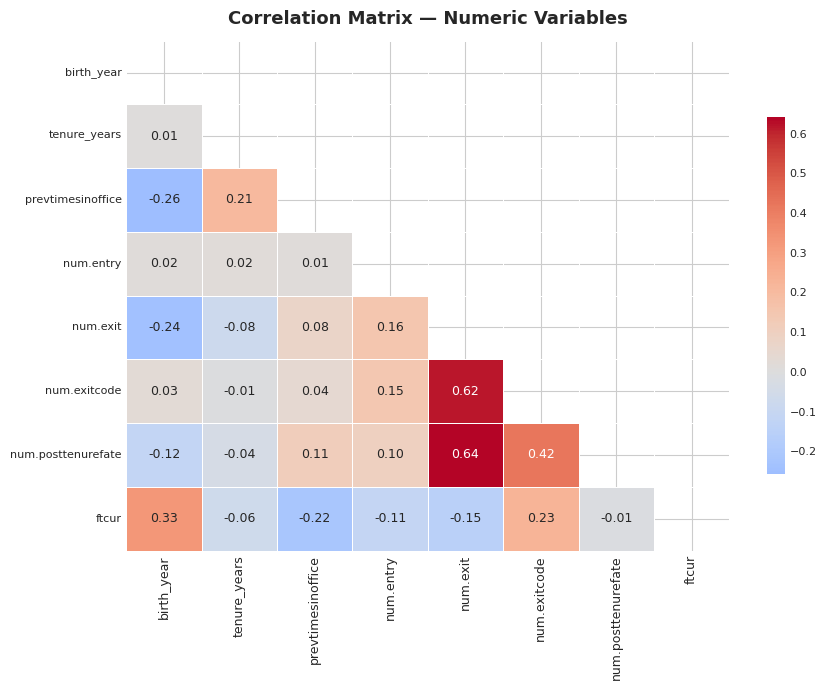

In [33]:
# Force-cast to numeric, strings become NaN automatically
num_cols_for_corr = ["birth_year", "tenure_years",
                     "prevtimesinoffice", "num.entry",
                     "num.exit", "num.exitcode", "num.posttenurefate",
                     "ftcur"]   # ← drop fties (it's text), keep ftcur (binary 0/1)

num_cols_for_corr = [c for c in num_cols_for_corr if c in spells.columns]

# Coerce any remaining non-numeric values to NaN before correlating
corr_data = spells[num_cols_for_corr].apply(pd.to_numeric, errors="coerce")

corr = corr_data.corr()

fig, ax = plt.subplots(figsize=(9, 7))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f",
            cmap="coolwarm", center=0, linewidths=0.5,
            ax=ax, cbar_kws={"shrink": 0.7},
            annot_kws={"size": 9})
ax.set_title("Correlation Matrix — Numeric Variables",
             fontsize=13, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()

## 6. EDA — Reign Dataset

In [34]:
df_re = pd.read_csv(PATHS['reign'])
print(f"Successfully loaded Reign dataset from: {PATHS['reign']}")
print(f"Shape: {df_re.shape[0]} rows x {df_re.shape[1]} columns")

print("\n--- First 5 rows ---")
display(df_re.head(5))

print("\n--- Column Data Types ---")
display(df_re.dtypes.to_frame('Type'))

print("\n--- Numeric Columns Summary ---")
display(df_re.describe(include=np.number))

Successfully loaded Reign dataset from: C:\Users\MSI\Desktop\projet stat\data\raw\reign_regime_list.csv
Shape: 629 rows x 6 columns

--- First 5 rows ---


,cowcode,gwf_country,gwf_casename,gwf_startdate,gwf_enddate,gwf_regimetype
0,2,USA,USA9/1/1787,3/4/1789,12/31/2020,presidential
1,20,Canada,Canada11668,12/11/1931,12/31/2020,parliamentary
2,31,Bahamas,Bahamas6/30/1973,6/30/1973,12/31/2020,parliamentary
3,40,Cuba,Cuba12298,10/10/1940,3/10/1952,presidential
4,40,Cuba,Cuba19063,3/10/1952,1/1/1959,personal



--- Column Data Types ---


,Type
cowcode,int64
gwf_country,object
gwf_casename,object
gwf_startdate,object
gwf_enddate,object
gwf_regimetype,object



--- Numeric Columns Summary ---


,cowcode
count,629.000000
mean,440.435612
std,253.487128
min,2.000000
25%,165.000000
50%,450.000000
75%,640.000000
max,990.000000


In [35]:
# Count NA values in each column
na_counts = df_re.isnull().sum()

# Display the result
print(na_counts)

cowcode           0
gwf_country       0
gwf_casename      0
gwf_startdate     0
gwf_enddate       0
gwf_regimetype    0
dtype: int64


## 7. EDA — Ucdp Dataset

In [36]:
df_ucdp = pd.read_csv(PATHS['ucdp'])
print(f"Successfully loaded UCDP dataset from: {PATHS['ucdp']}")
print(f"Shape: {df_ucdp.shape[0]} rows x {df_ucdp.shape[1]} columns")

print("\n--- First 5 rows ---")
display(df_ucdp.head(5))

print("\n--- Column Data Types ---")
display(df_ucdp.dtypes.to_frame('Type'))

print("\n--- Numeric Columns Summary ---")
display(df_ucdp.describe(include=np.number))


# ── Codec maps (from UCDP codebook) ───────────────────────────
INCOMPATIBILITY  = {1: "Territory", 2: "Government", 3: "Both"}
TYPE_OF_CONFLICT = {1: "Extra-systemic", 2: "Inter-state",
                    3: "Intra-state", 4: "Internationalised\nintra-state"}
INTENSITY        = {1: "Minor (25–999 deaths)", 2: "War (≥1 000 deaths)"}
REGION           = {1: "Europe", 2: "Middle East", 3: "Asia",
                    4: "Africa", 5: "Americas"}

df_ucdp["incompatibility_lbl"] = df_ucdp["incompatibility"].map(INCOMPATIBILITY)
df_ucdp["type_lbl"]            = df_ucdp["type_of_conflict"].map(TYPE_OF_CONFLICT)
df_ucdp["intensity_lbl"]       = df_ucdp["intensity_level"].map(INTENSITY)
df_ucdp["region_primary"]      = (df_ucdp["region"].astype(str)
                                    .str.split(",").str[0]
                                    .str.strip().astype(float)
                                    .map(REGION))

Successfully loaded UCDP dataset from: C:\Users\MSI\Desktop\projet stat\data\raw\UcdpPrioConflict_v26_1.csv
Shape: 2816 rows x 28 columns

--- First 5 rows ---


,conflict_id,location,side_a,side_a_id,side_a_2nd,side_b,side_b_id,side_b_2nd,incompatibility,territory_name,...,ep_end,ep_end_date,ep_end_prec,gwno_a,gwno_a_2nd,gwno_b,gwno_b_2nd,gwno_loc,region,version
0,200,Bolivia,Government of Bolivia,23,NaN,Popular Revolutionary Movement,719,NaN,2,NaN,...,1,1946-07-21,NaN,145,NaN,NaN,NaN,145,5,26.1
1,200,Bolivia,Government of Bolivia,23,NaN,MNR,720,NaN,2,NaN,...,1,1949-09-15,NaN,145,NaN,NaN,NaN,145,5,26.1
2,200,Bolivia,Government of Bolivia,23,NaN,MNR,720,NaN,2,NaN,...,1,1952-04-12,NaN,145,NaN,NaN,NaN,145,5,26.1
3,200,Bolivia,Government of Bolivia,23,NaN,ELN,721,NaN,2,NaN,...,1,1967-10-16,NaN,145,NaN,NaN,NaN,145,5,26.1
4,201,Cambodia (Kampuchea),Government of France,33,NaN,Khmer Issarak,160,NaN,1,Cambodia,...,0,NaN,NaN,220,NaN,NaN,NaN,811,3,26.1



--- Column Data Types ---


,Type
conflict_id,int64
location,object
side_a,object
side_a_id,object
side_a_2nd,object
side_b,object
side_b_id,object
side_b_2nd,object
incompatibility,int64
territory_name,object



--- Numeric Columns Summary ---


,conflict_id,incompatibility,year,intensity_level,cumulative_intensity,type_of_conflict,start_prec,start_prec2,ep_end,ep_end_prec,version
count,2816.000000,2816.000000,2816.000000,2816.000000,2816.000000,2816.000000,2816.000000,2816.000000,2816.000000,0.0,2816.0
mean,1650.283736,1.458807,1992.877841,1.248580,0.720526,3.041903,2.126065,2.245739,0.199929,NaN,26.1
std,4010.873991,0.520016,21.500448,0.432266,0.448821,0.632190,1.597983,1.611675,0.400018,NaN,0.0
min,200.000000,1.000000,1946.000000,1.000000,0.000000,1.000000,1.000000,1.000000,0.000000,NaN,26.1
25%,255.750000,1.000000,1977.000000,1.000000,0.000000,3.000000,1.000000,1.000000,0.000000,NaN,26.1
50%,309.000000,1.000000,1994.000000,1.000000,1.000000,3.000000,1.000000,1.000000,0.000000,NaN,26.1
75%,374.000000,2.000000,2013.000000,1.000000,1.000000,3.000000,3.000000,3.000000,0.000000,NaN,26.1
max,16470.000000,3.000000,2025.000000,2.000000,1.000000,4.000000,7.000000,7.000000,1.000000,NaN,26.1



── Missing Values ──────────────────────────────────────
                Missing  Percentage (%)
territory_name     1230           43.68
ep_end_date        2253           80.01
side_a_2nd         2337           82.99
gwno_a_2nd         2337           82.99
gwno_b             2661           94.50
side_b_2nd         2669           94.78
gwno_b_2nd         2669           94.78
ep_end_prec        2816          100.00


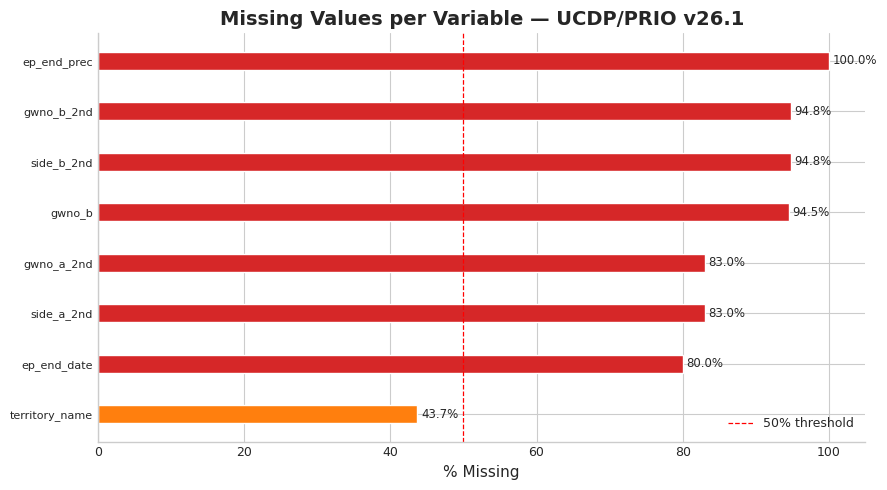

In [37]:
miss     = df_ucdp.isnull().sum()
miss_pct = (miss / len(df_ucdp) * 100).round(2)
miss_df  = (pd.DataFrame({"Missing": miss, "Percentage (%)": miss_pct})
              .query("`Missing` > 0")
              .sort_values("Percentage (%)", ascending=True))
 
print("\n── Missing Values ──────────────────────────────────────")
print(miss_df.to_string())
 
colors_miss = ["#d62728" if p > 50 else "#ff7f0e" if p > 20 else "#1f77b4"
               for p in miss_df["Percentage (%)"]]
 
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(miss_df.index, miss_df["Percentage (%)"],
               color=colors_miss, height=BAR_H)
ax.axvline(50, color="red", linestyle="--", lw=0.9, label="50% threshold")
for bar, pct in zip(bars, miss_df["Percentage (%)"]):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height() / 2,
            f"{pct:.1f}%", va="center", fontsize=8.5)
ax.set_xlabel("% Missing")
ax.set_title("Missing Values per Variable — UCDP/PRIO v26.1")
ax.legend(fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

    year  n_conflicts
77  2023           59
78  2024           59
79  2025           65
['Minor (25–999 deaths)' 'War (≥1 000 deaths)']


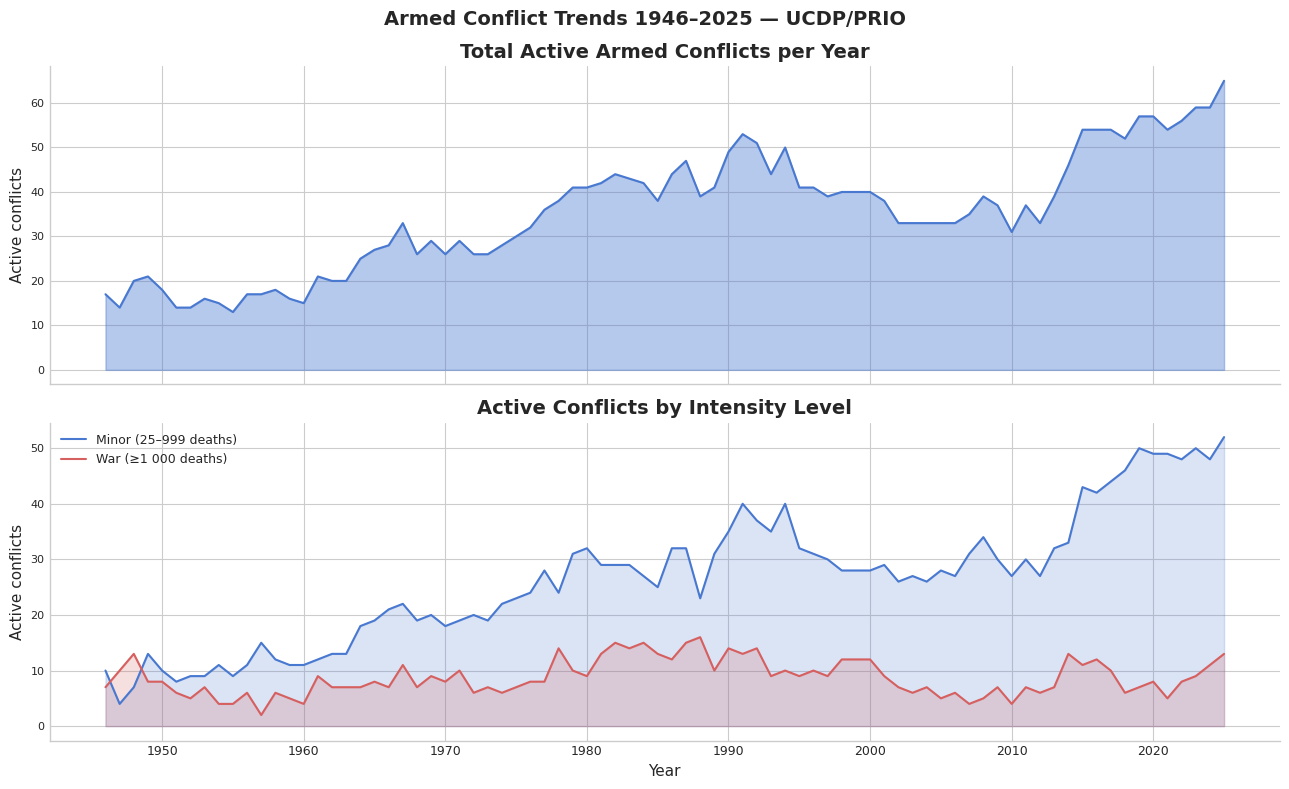

In [38]:
# ── Safety: ensure C is a proper list of RGB tuples ──────────
C = list(sns.color_palette("muted"))

# ── Ensure label column exists ────────────────────────────────
if "intensity_lbl" not in df_ucdp.columns:
    INTENSITY = {1: "Minor (25–999 deaths)", 2: "War (≥1 000 deaths)"}
    df_ucdp["intensity_lbl"] = df_ucdp["intensity_level"].map(INTENSITY)

# ── Aggregations ──────────────────────────────────────────────
yearly = (df_ucdp.groupby("year")["conflict_id"]
            .nunique()
            .reset_index(name="n_conflicts"))

yearly_intensity = (df_ucdp.groupby(["year", "intensity_lbl"], dropna=True)["conflict_id"]
                      .nunique()
                      .reset_index(name="n_conflicts"))

# ── Quick sanity check before plotting ───────────────────────
print(yearly.tail(3))
print(yearly_intensity["intensity_lbl"].unique())

# ── Plot ──────────────────────────────────────────────────────
COLOR_MINOR = C[0]
COLOR_WAR   = C[3]

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)

# 2a — total
ax = axes[0]
ax.fill_between(yearly["year"], yearly["n_conflicts"],
                color=COLOR_MINOR, alpha=0.4)
ax.plot(yearly["year"], yearly["n_conflicts"],
        color=COLOR_MINOR, lw=1.5)
ax.set_ylabel("Active conflicts")
ax.set_title("Total Active Armed Conflicts per Year")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax.spines[["top", "right"]].set_visible(False)

# 2b — by intensity
ax = axes[1]
for lbl, grp in yearly_intensity.groupby("intensity_lbl"):
    color = COLOR_MINOR if "Minor" in str(lbl) else COLOR_WAR
    grp_sorted = grp.sort_values("year")   # ensure x is monotonic
    ax.plot(grp_sorted["year"], grp_sorted["n_conflicts"],
            lw=1.5, label=lbl, color=color)
    ax.fill_between(grp_sorted["year"], grp_sorted["n_conflicts"],
                    alpha=0.2, color=color)

ax.set_xlabel("Year")
ax.set_ylabel("Active conflicts")
ax.set_title("Active Conflicts by Intensity Level")
ax.legend(fontsize=9)
ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Armed Conflict Trends 1946–2025 — UCDP/PRIO",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(GRAPH_DIR / "ucdp_trends.png", dpi=150, bbox_inches="tight")
plt.show()

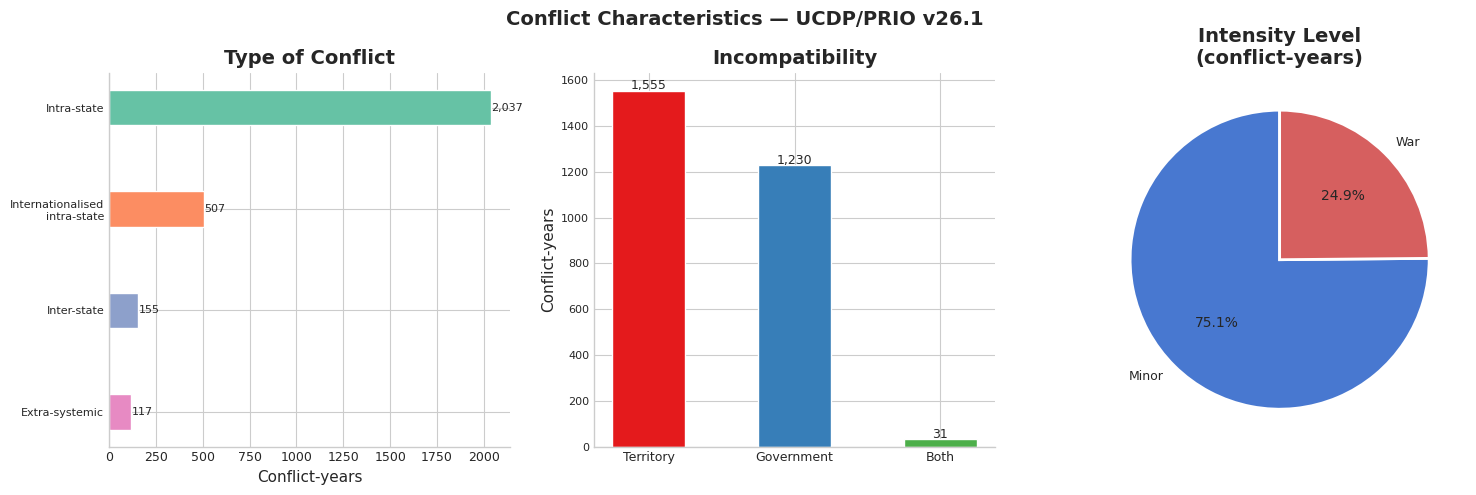

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
 
# 3a — type of conflict
type_counts = df_ucdp["type_lbl"].value_counts()
axes[0].barh(type_counts.index[::-1], type_counts.values[::-1],
             color=sns.color_palette("Set2", len(type_counts))[::-1], height=BAR_H)
axes[0].set_title("Type of Conflict")
axes[0].set_xlabel("Conflict-years")
for bar in axes[0].patches:
    axes[0].text(bar.get_width() + 2, bar.get_y() + bar.get_height() / 2,
                 f"{int(bar.get_width()):,}", va="center", fontsize=8)
axes[0].spines[["top", "right"]].set_visible(False)
 
# 3b — incompatibility
inc_counts = df_ucdp["incompatibility_lbl"].value_counts()
axes[1].bar(inc_counts.index, inc_counts.values,
            color=sns.color_palette("Set1", len(inc_counts)), width=0.5)
axes[1].set_title("Incompatibility")
axes[1].set_ylabel("Conflict-years")
for bar in axes[1].patches:
    axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 5,
                 f"{int(bar.get_height()):,}", ha="center", fontsize=9)
axes[1].spines[["top", "right"]].set_visible(False)
 
# 3c — intensity
int_counts = df_ucdp["intensity_lbl"].value_counts()
wedge_colors = [C[0], C[3]]
axes[2].pie(int_counts, labels=[l.split(" ")[0] for l in int_counts.index],
            autopct="%1.1f%%", startangle=90, colors=wedge_colors,
            wedgeprops=dict(edgecolor="white", linewidth=2))
axes[2].set_title("Intensity Level\n(conflict-years)")
 
fig.suptitle("Conflict Characteristics — UCDP/PRIO v26.1",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

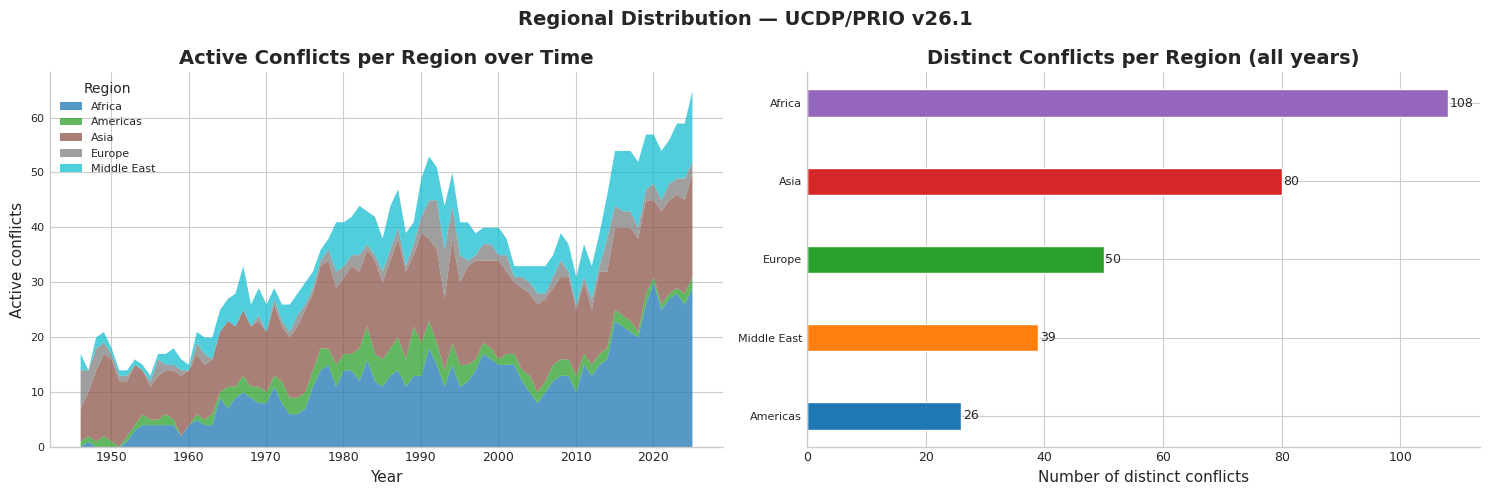

In [40]:
region_year = (df_ucdp.groupby(["year", "region_primary"])["conflict_id"]
                 .nunique()
                 .reset_index(name="n_conflicts"))
 
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
 
# stacked area
pivot = region_year.pivot(index="year", columns="region_primary",
                          values="n_conflicts").fillna(0)
pivot.plot.area(ax=axes[0], colormap="tab10", alpha=0.75, linewidth=0)
axes[0].set_title("Active Conflicts per Region over Time")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Active conflicts")
axes[0].legend(title="Region", fontsize=8, loc="upper left")
axes[0].spines[["top", "right"]].set_visible(False)
 
# total bar
region_total = (df_ucdp.groupby("region_primary")["conflict_id"]
                  .nunique()
                  .sort_values())
colors_r = sns.color_palette("tab10", len(region_total))
axes[1].barh(region_total.index, region_total.values,
             color=colors_r, height=BAR_H)
axes[1].set_title("Distinct Conflicts per Region (all years)")
axes[1].set_xlabel("Number of distinct conflicts")
for bar in axes[1].patches:
    axes[1].text(bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2,
                 str(int(bar.get_width())), va="center", fontsize=9)
axes[1].spines[["top", "right"]].set_visible(False)
 
fig.suptitle("Regional Distribution — UCDP/PRIO v26.1",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

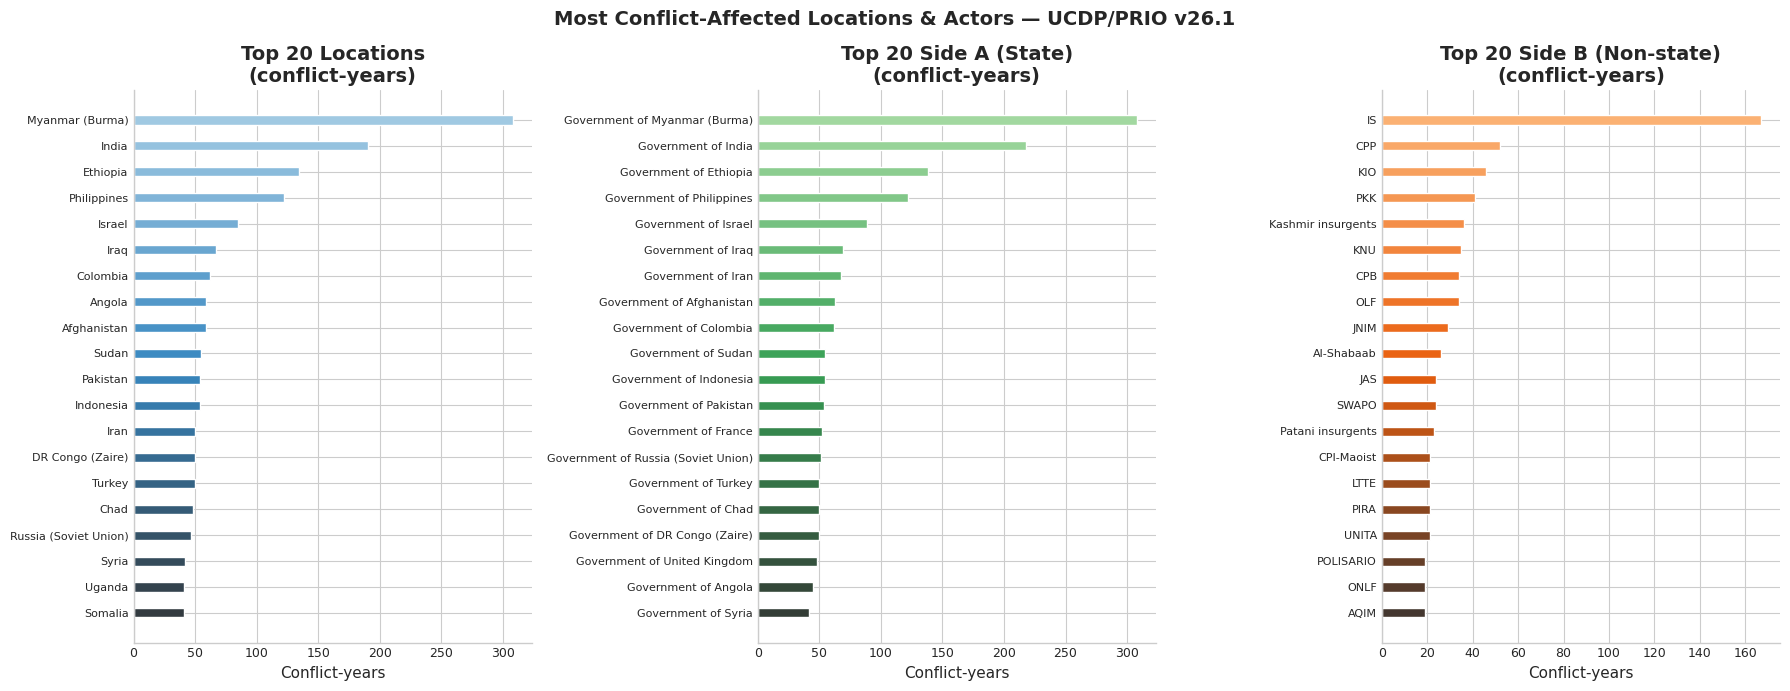

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(18, 7))
 
TOP = 20
 
# 5a — top locations by conflict-years
loc_counts = df_ucdp["location"].value_counts().head(TOP)
axes[0].barh(loc_counts.index[::-1], loc_counts.values[::-1],
             color=sns.color_palette("Blues_d", TOP)[::-1], height=BAR_H)
axes[0].set_title(f"Top {TOP} Locations\n(conflict-years)")
axes[0].set_xlabel("Conflict-years")
axes[0].spines[["top", "right"]].set_visible(False)
 
# 5b — top government actors (side_a)
side_a_counts = df_ucdp["side_a"].value_counts().head(TOP)
axes[1].barh(side_a_counts.index[::-1], side_a_counts.values[::-1],
             color=sns.color_palette("Greens_d", TOP)[::-1], height=BAR_H)
axes[1].set_title(f"Top {TOP} Side A (State)\n(conflict-years)")
axes[1].set_xlabel("Conflict-years")
axes[1].spines[["top", "right"]].set_visible(False)
 
# 5c — top non-state actors (side_b) — exclude government entries
mask_gov = ~df_ucdp["side_b"].str.startswith("Government", na=False)
side_b_counts = df_ucdp.loc[mask_gov, "side_b"].value_counts().head(TOP)
axes[2].barh(side_b_counts.index[::-1], side_b_counts.values[::-1],
             color=sns.color_palette("Oranges_d", TOP)[::-1], height=BAR_H)
axes[2].set_title(f"Top {TOP} Side B (Non-state)\n(conflict-years)")
axes[2].set_xlabel("Conflict-years")
axes[2].spines[["top", "right"]].set_visible(False)
 
fig.suptitle("Most Conflict-Affected Locations & Actors — UCDP/PRIO v26.1",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

count    549.00
mean      21.88
std       24.55
min        0.00
25%        0.43
50%       10.78
75%       39.00
max       79.75
Name: duration_years, dtype: float64


C:\Users\MSI\AppData\Local\Temp\ipykernel_29224\195280339.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=spells, x="duration_years", y="type_lbl",


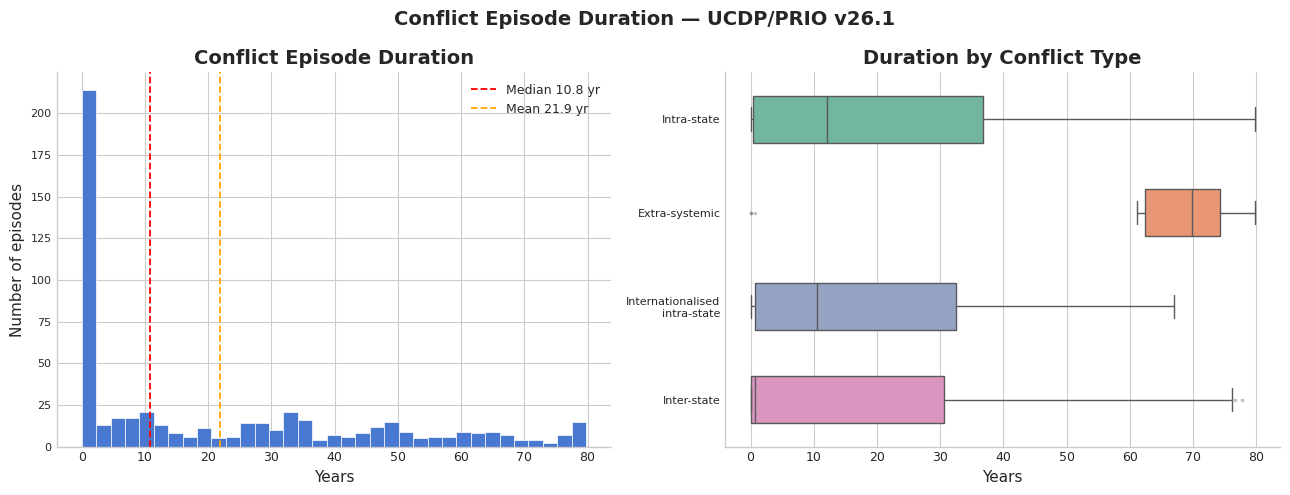

In [42]:
# ── Parse date columns if not already datetime ────────────────
for col in ["start_date", "start_date2", "ep_end_date"]:
    if df_ucdp[col].dtype == object:
        df_ucdp[col] = pd.to_datetime(df_ucdp[col], errors="coerce")

# ── Duration calculation ──────────────────────────────────────
spells = df_ucdp.drop_duplicates(subset=["conflict_id", "start_date2"]).copy()

spells["duration_years"] = (
    spells["ep_end_date"].fillna(pd.Timestamp("2025-12-31")) - spells["start_date2"]
).dt.days / 365.25

spells = spells[spells["duration_years"] > 0]

# ── Quick check ───────────────────────────────────────────────
print(spells["duration_years"].describe().round(2))

# ── Plot ──────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

med = spells["duration_years"].median()
mn  = spells["duration_years"].mean()

axes[0].hist(spells["duration_years"].dropna(), bins=35,
             color=C[0], edgecolor="white", linewidth=0.5)
axes[0].axvline(med, color="red",    linestyle="--", lw=1.3, label=f"Median {med:.1f} yr")
axes[0].axvline(mn,  color="orange", linestyle="--", lw=1.3, label=f"Mean {mn:.1f} yr")
axes[0].set_title("Conflict Episode Duration")
axes[0].set_xlabel("Years")
axes[0].set_ylabel("Number of episodes")
axes[0].legend(fontsize=9)
axes[0].spines[["top", "right"]].set_visible(False)

sns.boxplot(data=spells, x="duration_years", y="type_lbl",
            palette="Set2", ax=axes[1], width=0.5,
            flierprops=dict(marker=".", markersize=3, alpha=0.4))
axes[1].set_title("Duration by Conflict Type")
axes[1].set_xlabel("Years")
axes[1].set_ylabel("")
axes[1].spines[["top", "right"]].set_visible(False)

fig.suptitle("Conflict Episode Duration — UCDP/PRIO v26.1",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

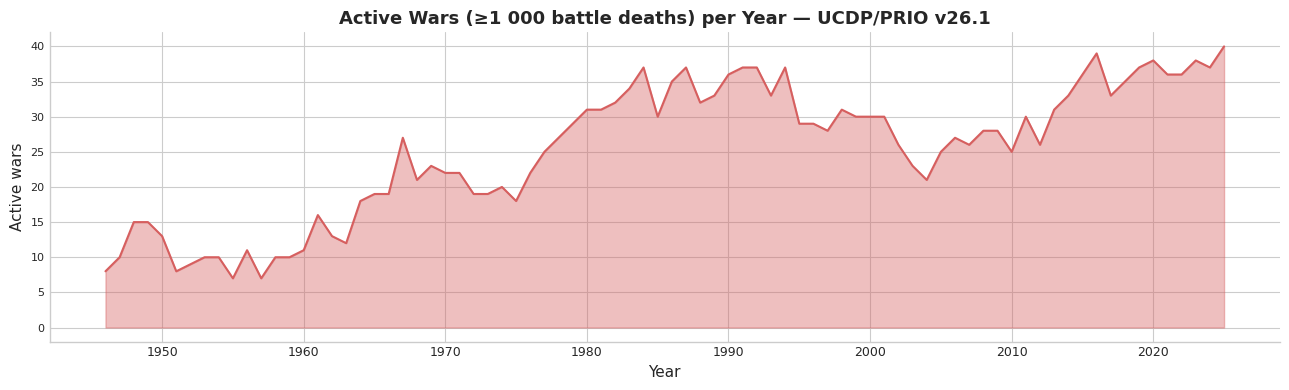

In [43]:
ever_war = set(df_ucdp[df_ucdp["intensity_level"] == 2]["conflict_id"])
df_ucdp["ever_war"] = df_ucdp["conflict_id"].isin(ever_war)
 
esc_year = (df_ucdp.groupby("year")["ever_war"]
              .sum()
              .reset_index(name="n_wars"))
 
fig, ax = plt.subplots(figsize=(13, 4))
ax.fill_between(esc_year["year"], esc_year["n_wars"],
                color=C[3], alpha=0.4)
ax.plot(esc_year["year"], esc_year["n_wars"], color=C[3], lw=1.5)
ax.set_title("Active Wars (≥1 000 battle deaths) per Year — UCDP/PRIO v26.1",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Year")
ax.set_ylabel("Active wars")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

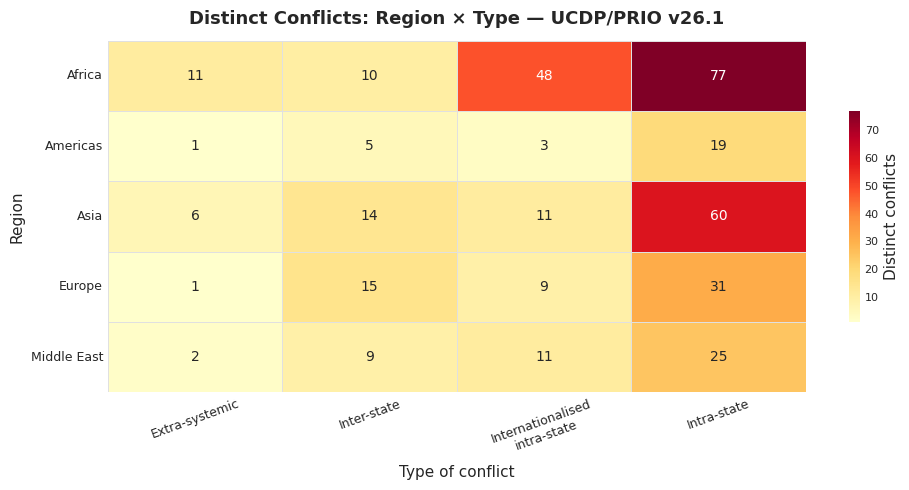

In [44]:
heat = (df_ucdp.groupby(["region_primary", "type_lbl"])["conflict_id"]
          .nunique()
          .unstack(fill_value=0))
 
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(heat, annot=True, fmt="d", cmap="YlOrRd",
            linewidths=0.5, linecolor="#e0e0e0",
            cbar_kws={"label": "Distinct conflicts", "shrink": 0.6},
            ax=ax, annot_kws={"size": 10})
ax.set_title("Distinct Conflicts: Region × Type — UCDP/PRIO v26.1",
             fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Type of conflict")
ax.set_ylabel("Region")
ax.tick_params(axis="x", rotation=20, labelsize=9)
ax.tick_params(axis="y", rotation=0, labelsize=9)
plt.tight_layout()
plt.savefig(GRAPH_DIR / "ucdp_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. EDA — Worldbank Dataset

In [45]:
df_bank_raw = pd.read_csv(PATHS['bank'])
print(f"Successfully loaded Worldbank dataset from: {PATHS['bank']}")
print(f"Shape: {df_bank_raw.shape[0]} rows x {df_bank_raw.shape[1]} columns")
print("\n--- First 5 rows ---")
display(df_bank_raw.head(5))

Successfully loaded Worldbank dataset from: C:\Users\MSI\Desktop\projet stat\data\raw\worldbank.csv
Shape: 1064 rows x 68 columns

--- First 5 rows ---


,economy,series,Country,Series,YR1960,YR1961,YR1962,YR1963,YR1964,YR1965,...,YR2014,YR2015,YR2016,YR2017,YR2018,YR2019,YR2020,YR2021,YR2022,YR2023
0,ZWE,NY.GDP.PCAP.KD,Zimbabwe,GDP per capita (constant 2015 US$),1142.548617,1177.314307,1157.234294,1191.335848,1141.577792,1160.443609,...,1381.254041,1387.126326,1378.342562,1422.919489,1472.146038,1357.530878,1230.819334,1312.200014,1369.197615,1418.471846
1,ZMB,NY.GDP.PCAP.KD,Zambia,GDP per capita (constant 2015 US$),1187.704601,1166.745964,1102.445822,1103.108132,1199.392190,1355.456810,...,1299.012418,1295.877887,1303.575139,1308.768292,1321.250457,1301.181330,1228.735001,1269.108218,1298.848050,1330.859982
2,YEM,NY.GDP.PCAP.KD,"Yemen, Rep.",GDP per capita (constant 2015 US$),NaN,NaN,NaN,NaN,NaN,NaN,...,1950.162545,1362.173812,1197.958660,1103.456348,1079.329384,NaN,NaN,NaN,NaN,NaN
3,PSE,NY.GDP.PCAP.KD,West Bank and Gaza,GDP per capita (constant 2015 US$),NaN,NaN,NaN,NaN,NaN,NaN,...,3227.849345,3272.154324,3483.099035,3462.979861,3417.794408,3378.434621,2922.468011,3051.486070,3099.960901,2888.763061
4,VIR,NY.GDP.PCAP.KD,Virgin Islands (U.S.),GDP per capita (constant 2015 US$),NaN,NaN,NaN,NaN,NaN,NaN,...,34098.710997,34007.352941,34614.748263,34435.494446,35174.101994,36309.743845,35850.743315,37313.048493,36983.431060,NaN


In [46]:
YEAR_COLS = [c for c in df_bank_raw.columns if c.startswith("YR")]
YEARS     = [int(c.replace("YR", "")) for c in YEAR_COLS]
 
# Melt to long format: one row per (country, indicator, year)
df_bank = df_bank_raw.melt(
    id_vars=["economy", "Country", "series", "Series"],
    value_vars=YEAR_COLS,
    var_name="year_str",
    value_name="value",
)
df_bank["year"] = df_bank["year_str"].str.replace("YR", "").astype(int)
df_bank.drop(columns="year_str", inplace=True)
 
# Short indicator names
INDICATOR_MAP = {
    "NY.GDP.PCAP.KD" : "GDP per capita",
    "NY.GDP.MKTP.KD.ZG": "GDP growth (%)",
    "SI.POV.GINI"    : "Gini index",
    "NY.GDP.PETR.RT.ZS": "Oil rents (% GDP)",
}
df_bank["indicator"] = df_bank["series"].map(INDICATOR_MAP)
 
print(f"Long format shape : {df_bank.shape}")
print(f"Countries         : {df_bank['Country'].nunique()}")
print(f"Year range        : {df_bank['year'].min()}–{df_bank['year'].max()}")
print(f"Indicators        : {df_bank['indicator'].unique().tolist()}")
 
# Pivot wide for cross-indicator analysis
df_wide = df_bank.pivot_table(
    index=["economy", "Country", "year"],
    columns="indicator",
    values="value",
).reset_index()

print("\n--- First 5 rows ---")
display(df_bank.head(5))
print("\n--- Column Data Types ---")
display(df_bank.dtypes.to_frame('Type'))

print("\n--- Numeric Columns Summary ---")
display(df_bank.describe(include=np.number))

Long format shape : (68096, 7)
Countries         : 266
Year range        : 1960–2023
Indicators        : ['GDP per capita', 'GDP growth (%)', 'Gini index', 'Oil rents (% GDP)']

--- First 5 rows ---


,economy,Country,series,Series,value,year,indicator
0,ZWE,Zimbabwe,NY.GDP.PCAP.KD,GDP per capita (constant 2015 US$),1142.548617,1960,GDP per capita
1,ZMB,Zambia,NY.GDP.PCAP.KD,GDP per capita (constant 2015 US$),1187.704601,1960,GDP per capita
2,YEM,"Yemen, Rep.",NY.GDP.PCAP.KD,GDP per capita (constant 2015 US$),NaN,1960,GDP per capita
3,PSE,West Bank and Gaza,NY.GDP.PCAP.KD,GDP per capita (constant 2015 US$),NaN,1960,GDP per capita
4,VIR,Virgin Islands (U.S.),NY.GDP.PCAP.KD,GDP per capita (constant 2015 US$),NaN,1960,GDP per capita



--- Column Data Types ---


,Type
economy,object
Country,object
series,object
Series,object
value,float64
year,int64
indicator,object



--- Numeric Columns Summary ---


,value,year
count,41182.000000,68096.000000
mean,3836.998633,1991.500000
std,11751.963957,18.473089
min,-64.047107,1960.000000
25%,1.172061,1975.750000
50%,7.053659,1991.500000
75%,1392.202178,2007.250000
max,225884.183304,2023.000000


economy          0
Country          0
series           0
Series           0
value        26914
year             0
indicator        0
dtype: int64


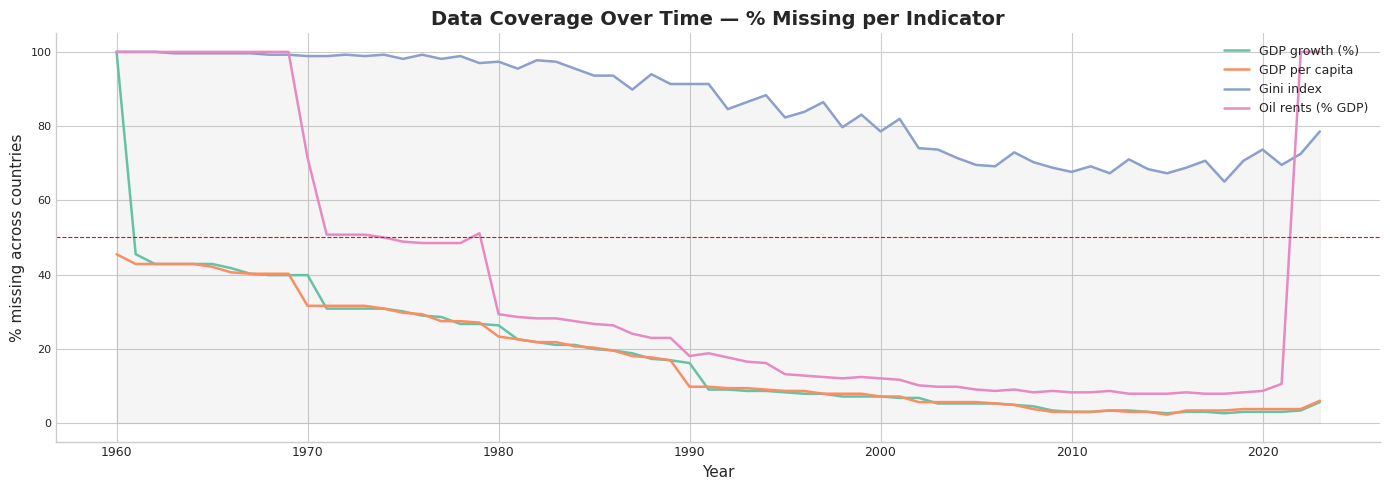

In [47]:
# Count NA values in each column
na_counts = df_bank.isnull().sum()

# Display the result
print(na_counts)


miss_by_year = (df_bank.groupby(["year", "indicator"])["value"]
                  .apply(lambda x: x.isnull().mean() * 100)
                  .reset_index(name="pct_missing"))
 
fig, ax = plt.subplots(figsize=(14, 5))
for ind, grp in miss_by_year.groupby("indicator"):
    ax.plot(grp["year"], grp["pct_missing"], lw=1.8, label=ind, marker="")
ax.fill_between(
    miss_by_year[miss_by_year["indicator"] == "Gini index"]["year"],
    miss_by_year[miss_by_year["indicator"] == "Gini index"]["pct_missing"],
    alpha=0.08, color="grey"
)
ax.set_title("Data Coverage Over Time — % Missing per Indicator")
ax.set_xlabel("Year")
ax.set_ylabel("% missing across countries")
ax.legend(fontsize=9, loc="upper right")
ax.axhline(50, color="red", linestyle="--", lw=0.8, label="50%")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

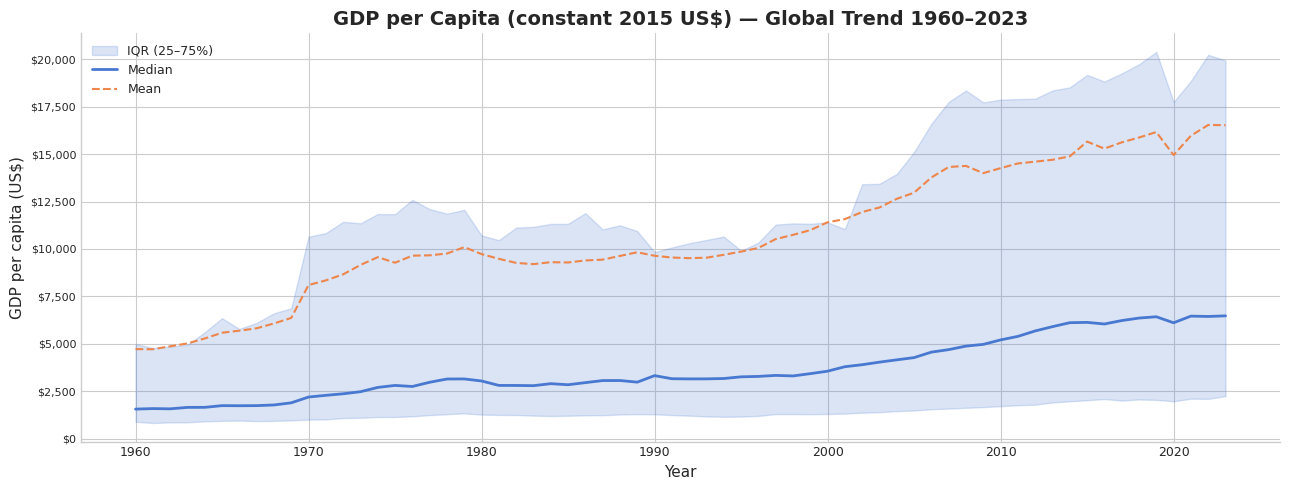

In [48]:
gdp = df_bank[df_bank["indicator"] == "GDP per capita"].dropna(subset=["value"])
 
gdp_year = (gdp.groupby("year")["value"]
               .agg(["median", "mean",
                     lambda x: x.quantile(0.25),
                     lambda x: x.quantile(0.75)])
               .reset_index())
gdp_year.columns = ["year", "median", "mean", "q25", "q75"]
 
fig, ax = plt.subplots(figsize=(13, 5))
ax.fill_between(gdp_year["year"], gdp_year["q25"], gdp_year["q75"],
                alpha=0.2, color=C[0], label="IQR (25–75%)")
ax.plot(gdp_year["year"], gdp_year["median"], color=C[0], lw=2, label="Median")
ax.plot(gdp_year["year"], gdp_year["mean"],   color=C[1], lw=1.5,
        linestyle="--", label="Mean")
ax.set_title("GDP per Capita (constant 2015 US$) — Global Trend 1960–2023")
ax.set_xlabel("Year")
ax.set_ylabel("GDP per capita (US$)")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x:,.0f}"))
ax.legend(fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

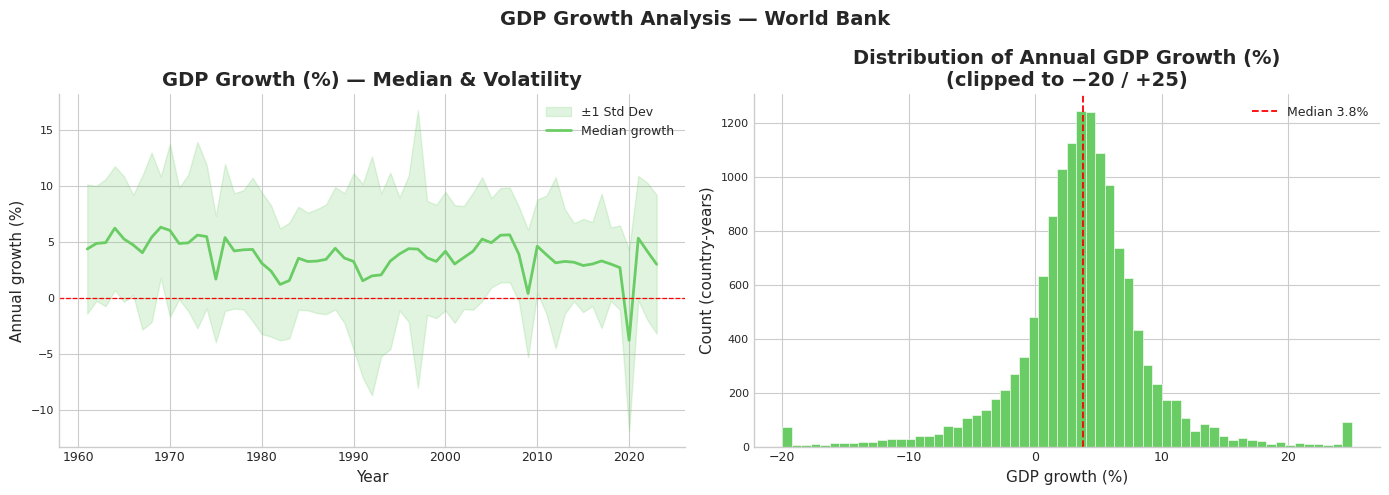

In [49]:
growth = df_bank[df_bank   ["indicator"] == "GDP growth (%)"].dropna(subset=["value"])
growth_year = growth.groupby("year")["value"].agg(["median", "std"]).reset_index()
 
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
 
# 3a — median growth over time with ±1 std band
axes[0].fill_between(growth_year["year"],
                     growth_year["median"] - growth_year["std"],
                     growth_year["median"] + growth_year["std"],
                     alpha=0.2, color=C[2], label="±1 Std Dev")
axes[0].plot(growth_year["year"], growth_year["median"],
             color=C[2], lw=2, label="Median growth")
axes[0].axhline(0, color="red", linestyle="--", lw=0.9)
axes[0].set_title("GDP Growth (%) — Median & Volatility")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Annual growth (%)")
axes[0].legend(fontsize=9)
axes[0].spines[["top", "right"]].set_visible(False)
 
# 3b — distribution (histogram, all years/countries)
axes[1].hist(growth["value"].clip(-20, 25), bins=60,
             color=C[2], edgecolor="white", linewidth=0.4)
axes[1].axvline(growth["value"].median(), color="red", linestyle="--",
                lw=1.3, label=f"Median {growth['value'].median():.1f}%")
axes[1].set_title("Distribution of Annual GDP Growth (%)\n(clipped to −20 / +25)")
axes[1].set_xlabel("GDP growth (%)")
axes[1].set_ylabel("Count (country-years)")
axes[1].legend(fontsize=9)
axes[1].spines[["top", "right"]].set_visible(False)
 
fig.suptitle("GDP Growth Analysis — World Bank", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

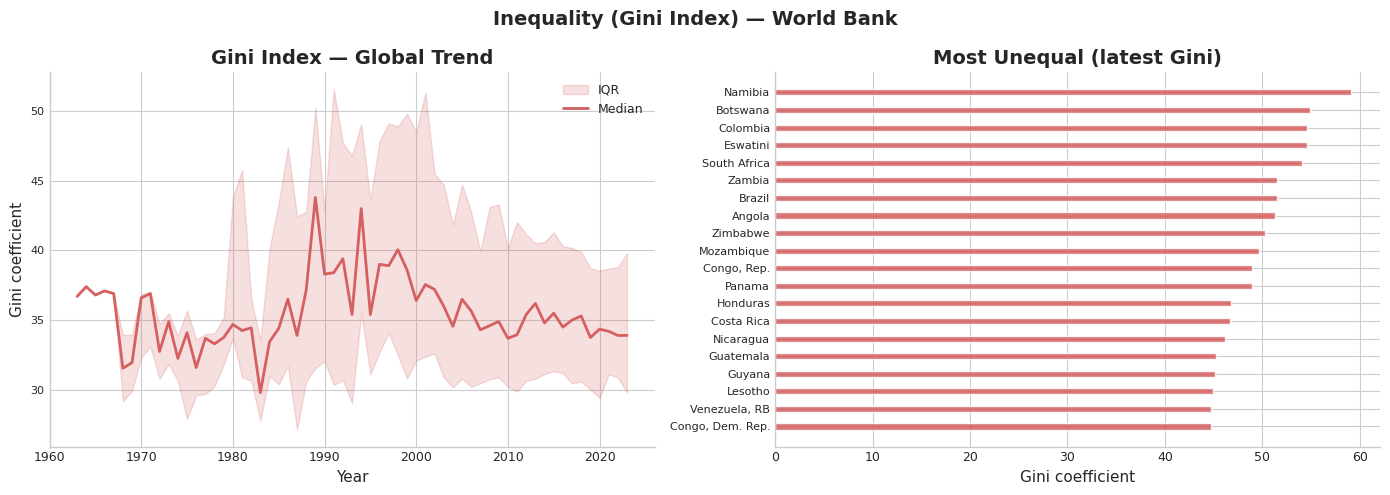

In [50]:
gini = df_bank[df_bank["indicator"] == "Gini index"].dropna(subset=["value"])
gini_year = gini.groupby("year")["value"].agg(["median", "mean",
    lambda x: x.quantile(0.25),
    lambda x: x.quantile(0.75)]).reset_index()
gini_year.columns = ["year", "median", "mean", "q25", "q75"]
 
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
 
# 4a — trend
axes[0].fill_between(gini_year["year"], gini_year["q25"], gini_year["q75"],
                     alpha=0.2, color=C[3], label="IQR")
axes[0].plot(gini_year["year"], gini_year["median"],
             color=C[3], lw=2, label="Median")
axes[0].set_title("Gini Index — Global Trend")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Gini coefficient")
axes[0].legend(fontsize=9)
axes[0].spines[["top", "right"]].set_visible(False)
 
# 4b — most recent Gini by country (top & bottom 20)
latest_gini = (gini.sort_values("year")
                   .groupby("Country")
                   .last()
                   .reset_index()
                   .sort_values("value", ascending=False))
 
top20    = latest_gini.head(20)
bottom20 = latest_gini.tail(20)
 
for ax_sub, title, subset, color in [
    (axes[1], "Most Unequal (latest Gini)", top20, C[3]),
]:
    ax_sub.barh(subset["Country"][::-1], subset["value"][::-1],
                color=color, height=BAR_H, alpha=0.85)
    ax_sub.set_title(title)
    ax_sub.set_xlabel("Gini coefficient")
    ax_sub.spines[["top", "right"]].set_visible(False)
 
fig.suptitle("Inequality (Gini Index) — World Bank", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(GRAPH_DIR / "wb_gini.png", dpi=150, bbox_inches="tight")
plt.show()

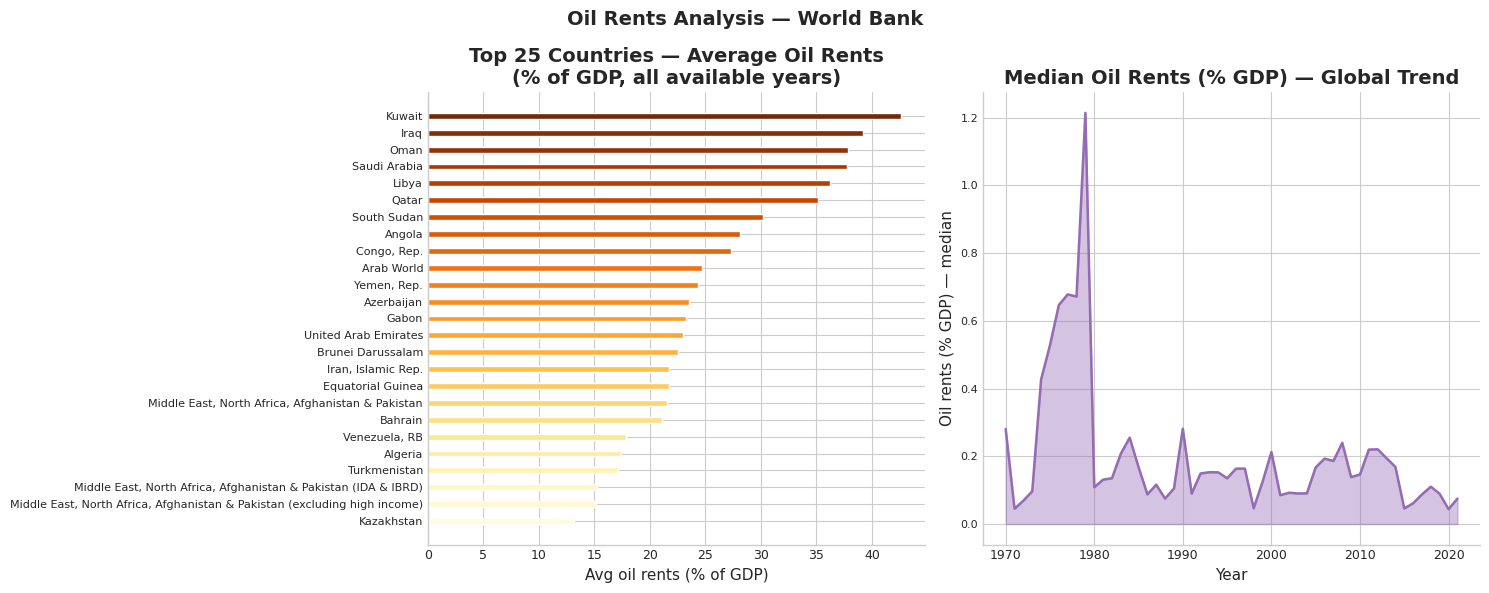

In [51]:
oil = df_bank[df_bank["indicator"] == "Oil rents (% GDP)"].dropna(subset=["value"])
 
# 5a — top countries by average oil rents
top_oil = (oil.groupby("Country")["value"]
              .mean()
              .sort_values(ascending=False)
              .head(25))
 
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
 
axes[0].barh(top_oil.index[::-1], top_oil.values[::-1],
             color=sns.color_palette("YlOrBr_r", 25)[::-1], height=BAR_H)
axes[0].set_title("Top 25 Countries — Average Oil Rents\n(% of GDP, all available years)")
axes[0].set_xlabel("Avg oil rents (% of GDP)")
axes[0].spines[["top", "right"]].set_visible(False)
 
# 5b — global median oil rents over time
oil_year = oil.groupby("year")["value"].median().reset_index()
axes[1].fill_between(oil_year["year"], oil_year["value"],
                     color=C[4], alpha=0.4)
axes[1].plot(oil_year["year"], oil_year["value"], color=C[4], lw=1.8)
axes[1].set_title("Median Oil Rents (% GDP) — Global Trend")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Oil rents (% GDP) — median")
axes[1].spines[["top", "right"]].set_visible(False)
 
fig.suptitle("Oil Rents Analysis — World Bank", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(GRAPH_DIR / "wb_oil.png", dpi=150, bbox_inches="tight")
plt.show()

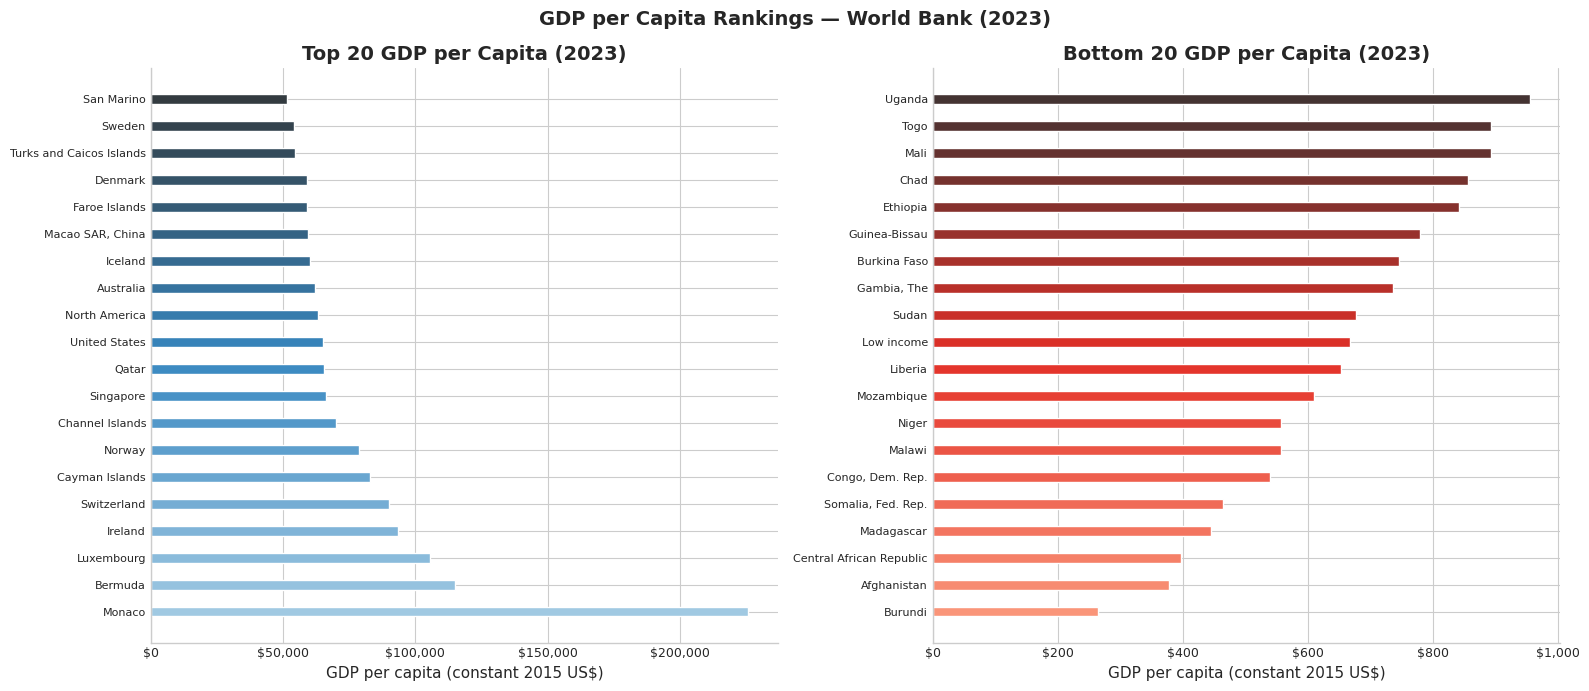

In [52]:
latest_year = df_wide["year"].max()
latest = df_wide[df_wide["year"] == latest_year].dropna(subset=["GDP per capita"])
latest_sorted = latest.sort_values("GDP per capita", ascending=False)
 
TOP = 20
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
 
for ax, subset, title, palette in [
    (axes[0], latest_sorted.head(TOP),
     f"Top {TOP} GDP per Capita ({latest_year})", "Blues_d"),
    (axes[1], latest_sorted.tail(TOP).sort_values("GDP per capita"),
     f"Bottom {TOP} GDP per Capita ({latest_year})", "Reds_d"),
]:
    colors = sns.color_palette(palette, TOP)
    ax.barh(subset["Country"], subset["GDP per capita"],
            color=colors, height=BAR_H)
    ax.set_title(title)
    ax.set_xlabel("GDP per capita (constant 2015 US$)")
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x:,.0f}"))
    ax.spines[["top", "right"]].set_visible(False)
 
fig.suptitle(f"GDP per Capita Rankings — World Bank ({latest_year})",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


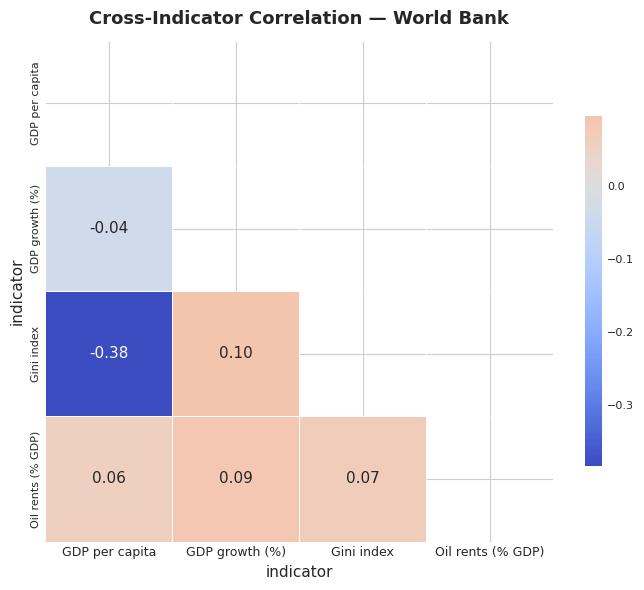

In [53]:
corr_df = (df_wide[["GDP per capita", "GDP growth (%)",
                     "Gini index", "Oil rents (% GDP)"]]
           .apply(pd.to_numeric, errors="coerce"))
corr = corr_df.corr()

# ✅ Rebuild mask from the current corr shape — not a stale one
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f",
            cmap="coolwarm", center=0, linewidths=0.5,
            ax=ax, cbar_kws={"shrink": 0.7},
            annot_kws={"size": 11})
ax.set_title("Cross-Indicator Correlation — World Bank",
             fontsize=13, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()

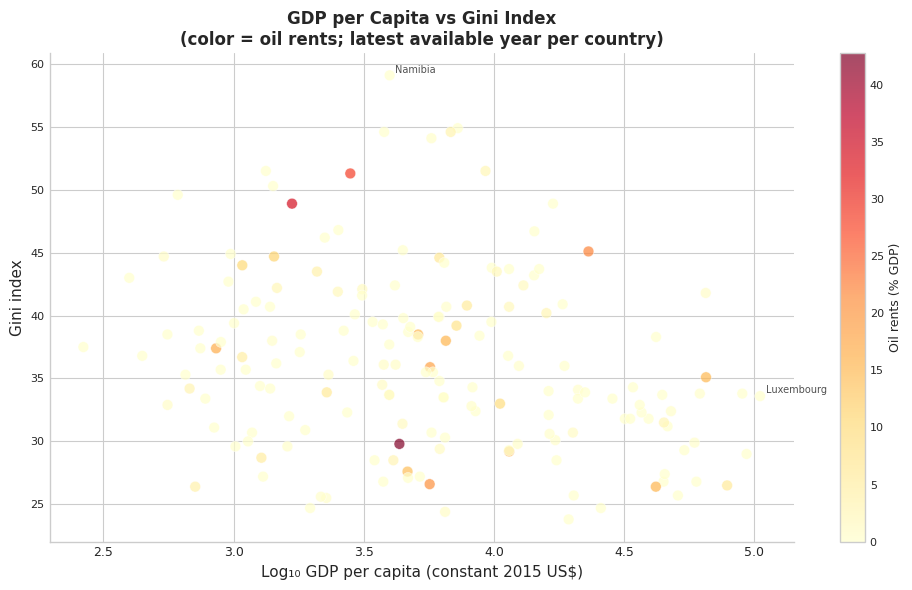

In [54]:
scatter_df = (df_wide.sort_values("year")
                     .groupby("Country")
                     .last()
                     .reset_index()
                     .dropna(subset=["GDP per capita", "Gini index"]))
 
fig, ax = plt.subplots(figsize=(10, 6))
sc = ax.scatter(
    np.log10(scatter_df["GDP per capita"].clip(lower=1)),
    scatter_df["Gini index"],
    c=scatter_df["Oil rents (% GDP)"].fillna(0),
    cmap="YlOrRd", alpha=0.7, edgecolors="white", linewidth=0.4, s=60,
)
cbar = plt.colorbar(sc, ax=ax)
cbar.set_label("Oil rents (% GDP)", fontsize=9)
 
ax.set_title("GDP per Capita vs Gini Index\n(color = oil rents; latest available year per country)",
             fontsize=12, fontweight="bold")
ax.set_xlabel("Log₁₀ GDP per capita (constant 2015 US$)")
ax.set_ylabel("Gini index")
ax.spines[["top", "right"]].set_visible(False)
 
# Label notable outliers
for _, row in scatter_df.iterrows():
    if row["Gini index"] > 58 or row["GDP per capita"] > 100000:
        ax.annotate(row["Country"],
                    (np.log10(row["GDP per capita"]), row["Gini index"]),
                    fontsize=7, alpha=0.8,
                    xytext=(4, 2), textcoords="offset points")
 
plt.tight_layout()
plt.savefig(GRAPH_DIR / "wb_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

## 9.Data cleaning , ARP Dataset

In [55]:
# ============================================================
# EXTENSION TEMPORELLE : Post-2015
# Renseigner Last Year of Power pour les partis tombés entre 2016 et 2024.
# Les partis toujours au pouvoir restent dans l'échantillon comme observations censurées.
#
# Périmètre : partis nommés (Party != 'N') uniquement.
# Les entrées Party='N' sont exclues de l'analyse en Section 2.
#
# Sources vérifiées par cas : Wikipedia (encyclopédie politique),
# Encyclopaedia Britannica, Freedom House country reports,
# CIA World Factbook, Al Jazeera, Human Rights Watch, BBC.
#
# Convention ARPD respectée :
#   - Last Year of Power = dernière année calendaire de détention du pouvoir
#   - Censored → 0 une fois la chute confirmée
#   - NB : 'Russia ' et 'Vietnam ' ont un espace final dans le CSV source
# ============================================================

# ── PARTIE 1 : Chutes post-2015 ──────────────────────────────────────────────
# Clé  : (Country — chaîne exacte du CSV, Year in Power)
# Valeur : (Last Year of Power, note de source)

post_2015_falls = {

    # ── Afrique subsaharienne ─────────────────────────────────────────────────
    ('Burkina Faso', 2015): (
        2022,
        "Coup militaire du 24 jan. 2022 : Lt.-Col. Damiba renverse le président Kaboré (MPP). "
        "Source : Wikipedia 'January 2022 Burkinabé coup d'état'."
    ),
    ('Ethiopia', 1993): (
        2019,
        "EPRDF formellement dissous le 1er déc. 2019 ; remplacé par le Prosperity Party d'Abiy Ahmed. "
        "Source : Wikipedia 'Ethiopian People's Revolutionary Democratic Front' ; WaPo déc. 2019."
    ),
    ('Gabon', 1960): (
        2023,
        "Coup militaire du 30 août 2023 : Ali Bongo (PDG) renversé minutes après l'annonce de sa réélection. "
        "Source : Wikipedia '2023 Gabonese coup d'état' ; CNN 31 août 2023."
    ),
    ('Gambia', 1996): (
        2017,
        "Jammeh (APRC) perd l'élection du 1er déc. 2016 face à Barrow ; "
        "part en exil le 21 jan. 2017 après intervention CEDEAO. "
        "Source : Wikipedia '2016–2017 Gambian constitutional crisis'."
    ),
    ('Guinea', 2010): (
        2021,
        "Coup militaire du 5 sept. 2021 : Alpha Condé (RPG) renversé par le CNRD. "
        "Source : Wikipedia '2021 Guinean coup d'état'."
    ),
    ('Guinea-Bissau', 2004): (
        2020,
        "Embaló (Madem P16) investi président le 27 fév. 2020 après élection contestée déc. 2019 ; "
        "le PAIGC perd la présidence. "
        "Source : Wikipedia 'Umaro Sissoco Embaló'."
    ),
    ('Seychelles', 1977): (
        2020,
        "Le People's Party (SPPF) perd l'élection présidentielle d'oct. 2020 face à Wavel Ramkalawan (LDS). "
        "Source : Wikipedia '2020 Seychellois presidential election'."
    ),
    ('Mali', 2013): (
        2020,
        "Coup militaire du 18 août 2020 : IBK (RPM) renversé par le CNSP du Col. Goïta. "
        "Source : Wikipedia '2020 Malian coup d'état' ; UK Parliament Library."
    ),
    ('Togo', 1969): (
        # Note: Gnassingbé Eyadéma founded RPT in 1969; Faure Gnassingbé continues as UNIR.
        # En 2012, le RPT a été renommé UNIR (Union pour la République).
        # L'ARPD code la continuité partisane ; le parti est toujours au pouvoir.
        # → Voir liste "toujours au pouvoir" ci-dessous ; ne pas mettre ici.
        # (ligne commentée — voir partie 2)
        None, None  # placeholder, skipped below
    ),

    # ── Asie / Pacifique ──────────────────────────────────────────────────────
    ('Armenia', 1999): (
        2018,
        "Révolution de velours : Sargsyan (RPA/HHK) démissionne le 23 avril 2018 ; "
        "Pashinyan élu PM le 8 mai 2018. Élections snap déc. 2018 : HHK < 5%, zéro siège. "
        "Source : Wikipedia '2018 Armenian Revolution' ; Freedom House 2019."
    ),
    ('Azerbaijan', 1993): (
        # Aliyev et le New Azerbaijan Party toujours au pouvoir → Partie 2
        None, None
    ),
    ('Bangladesh', 2014): (
        2024,
        "Sheikh Hasina (Awami League) démissionne le 5 août 2024 et s'exile en Inde "
        "sous la pression du mouvement étudiant. Parti banni en mai 2025. "
        "Source : Britannica 'Awami League' ; Wikipedia 'Resignation of Sheikh Hasina'."
    ),
    ('Cambodia', 1981): (
        # PPC toujours au pouvoir sous Hun Manet → Partie 2
        None, None
    ),
    ('Kazakhstan', 2006): (
        # Décision de codage (identique à final.ipynb) : PAS une chute. Nur Otan est rebaptisé
        # 'Amanat' le 1er mars 2022 et reste au pouvoir sous Tokayev. Dans l'ARPD, un simple
        # changement de nom ne termine pas un spell : les renommages sont documentés dans la
        # colonne 'Renaming?'. → Le parti reste censuré (toujours au pouvoir).
        # Source : Wikipedia 'Amanat (political party)'.
        None, None
    ),
    ('Kyrgyzstan', 2010): (
        2020,
        "Révolution d'octobre 2020 : Jeenbekov (SDPK) démissionne le 15 oct. 2020 ; "
        "Sadyr Japarov (Ata-Jurt) prend le pouvoir. "
        "Source : Wikipedia '2020 Kyrgyz Revolution'."
    ),
    ('Malaysia', 1957): (
        2018,
        "UMNO-BN perd les élections GE14 du 9 mai 2018 après 61 ans de pouvoir ininterrompu ; "
        "Pakatan Harapan sous Mahathir remporte la majorité. "
        "Source : Wikipedia '2018 Malaysian general election' ; Journal of Democracy 2018."
    ),
    ('Maldives', 2013): (
        2018,
        "PPM (Yameen) perd l'élection présidentielle du 23 sept. 2018 (58,4% pour Solih/MDP). "
        "Résultats officiels le 30 sept. 2018 ; Solih investi le 17 nov. 2018. "
        "Source : Freedom House 2019 ; Wikipedia '2018 Maldivian presidential election'."
    ),
    ('Samoa', 1982): (
        2021,
        "HRPP perd les élections générales du 9 avril 2021 face au parti FAST "
        "de Fiamē Naomi Mataʻafa. "
        "Source : Wikipedia '2021 Samoan general election'."
    ),
    ('Uzbekistan', 1991): (
        2016,
        "Après la mort de Karimov (sept. 2016), Mirziyoyev s'aligne sur le Parti "
        "libéral-démocrate (UzLiDeP) ; le PDPU perd sa position dominante. "
        "Source : Wikipedia 'Shavkat Mirziyoyev'."
    ),

    # ── Moyen-Orient / Afrique du Nord ────────────────────────────────────────
    ('Syria', 1966): (
        2024,
        "Assad fuit Damas dans la nuit du 7 au 8 déc. 2024 ; le régime Ba'ath s'effondre. "
        "Le Ba'ath gèle ses activités le 11 déc. 2024, dissous officiellement le 29 jan. 2025. "
        "Source : Wikipedia 'Fall of the Assad regime' ; HRW déc. 2025."
    ),

    # ── Afrique du Nord / Corne de l'Afrique ─────────────────────────────────
    ('Sudan-North', 2011): (
        2019,
        "Bashir (NCP) renversé par l'armée le 11 avril 2019 après 30 ans de règne. "
        "NCP dissous par le Conseil souverain le 29 nov. 2019. "
        "Source : Wikipedia 'National Congress Party (Sudan)' ; Counter Extremism Project."
    ),

    # ── Amériques ─────────────────────────────────────────────────────────────
    ('Democratic Republic of Congo', 2003): (
        2018,
        "Tshisekedi (UDPS) déclaré vainqueur le 10 jan. 2019 ; Kabila (PPRD) quitte "
        "la présidence le 24 jan. 2019. Élection tenue le 30 déc. 2018. "
        "Source : Wikipedia 'Felix Tshisekedi' ; Chatham House jan. 2020."
    ),

    # ── Afrique de l'Ouest (Côte d'Ivoire) ───────────────────────────────────
    ('Ivory Coast', 2011): (
        # Décision de codage (identique à final.ipynb) : chute conservée. 'Merger' est une modalité
        # de 'How Power Ended' dans l'ARPD : la fusion du RDR dans le RHDP termine le spell du RDR.
        2018,
        "Le RDR fusionne avec le PDCI et d'autres partis pour former le RHDP en 2018. "
        "Le RDR en tant qu'entité distincte cesse d'exister ; Ouattara continue sous bannière RHDP. "
        "Source : Wikipedia 'Rassemblement des houphouëtistes pour la démocratie et la paix'."
    ),
}

# Appliquer les mises à jour
n_updated = 0
for (country, year_in_power), payload in post_2015_falls.items():
    last_year, note = payload
    if last_year is None:          # placeholder (pas une chute : reste censuré)
        continue
    mask = (df_arpd['Country'] == country) & (df_arpd['Year in Power'] == year_in_power)
    n_match = int(mask.sum())
    if n_match == 0:
        print(f"⚠  INTROUVABLE : ({repr(country)}, {year_in_power})")
        continue
    df_arpd.loc[mask, 'Last Year of Power'] = last_year
    df_arpd.loc[mask, 'Censored'] = 0
    n_updated += n_match
    print(f"✓  {country} ({year_in_power}) → Last Year = {last_year}")

print(f"\n{n_updated} ligne(s) mise(s) à jour ")

✓  Burkina Faso (2015) → Last Year = 2022
✓  Ethiopia (1993) → Last Year = 2019
✓  Gabon (1960) → Last Year = 2023
✓  Gambia (1996) → Last Year = 2017
✓  Guinea (2010) → Last Year = 2021
✓  Guinea-Bissau (2004) → Last Year = 2020
✓  Seychelles (1977) → Last Year = 2020
✓  Mali (2013) → Last Year = 2020
✓  Armenia (1999) → Last Year = 2018
✓  Bangladesh (2014) → Last Year = 2024
✓  Kyrgyzstan (2010) → Last Year = 2020
✓  Malaysia (1957) → Last Year = 2018
✓  Maldives (2013) → Last Year = 2018
✓  Samoa (1982) → Last Year = 2021
✓  Uzbekistan (1991) → Last Year = 2016
✓  Syria (1966) → Last Year = 2024
✓  Sudan-North (2011) → Last Year = 2019
✓  Democratic Republic of Congo (2003) → Last Year = 2018
✓  Ivory Coast (2011) → Last Year = 2018

19 ligne(s) mise(s) à jour 


In [56]:
REGIME_TYPE_MAP = {
    # Format: (Country, Year_in_Power): regime_type_detail

    # Occupations
    ('Albania',       1940): 'occupation',
    ('Austria',       1939): 'occupation',
    ('Ethiopia',      1936): 'occupation',
    ('France',        1940): 'occupation',
    ('Germany (East)',1945): 'occupation',
    ('Italy',         1944): 'occupation',
    ('Philippines',   1942): 'occupation',
    ('Poland',        1940): 'occupation',
    ('San Marino',    1943): 'occupation',
    ('Yugoslavia',    1940): 'occupation',
    ('Iraq',          2003): 'occupation',

    # Fix missing Monarchy flag
    ('Iran',          1925): 'monarchy',
    ('Bulgaria',      1935): 'monarchy',

    # Personal authoritarian
    ('Belarus',       1994): 'personal',
    ('Estonia',       1934): 'personal',
    ('Iran',          1988): 'theocracy',
    ('Kyrgyzstan',    1991): 'personal',
    ('Latvia',        1934): 'personal',
    ('Maldives',      1966): 'personal',
    ('Philippines',   1972): 'personal',
    ('Sri Lanka',     2010): 'personal',

    # Transitional/failed state
    ('Afghanistan',   1992): 'failed_state',
    ('Afghanistan',   2001): 'transitional',
    ('Somalia',       1991): 'failed_state',
    ('Liberia',       1990): 'civil_war',
    ('Liberia',       2003): 'transitional',

    # Fix missing Military flag
    ('Comoros',       1999): 'military',
    ('Sierra Leone',  1992): 'military',
    ('Vietnam (South)',1963):'military',
    ('Costa Rica',    1948): 'military',
}

def get_regime_type(row):
    if row['Party'] != 'N':
        return 'party'
    key = (row['Country'], row['Year in Power'])
    if key in REGIME_TYPE_MAP:
        return REGIME_TYPE_MAP[key]
    if row['Military'] == 1 and row['Monarchy'] == 1:
        return 'military_monarchy'
    if row['Military'] == 1:
        return 'military'
    if row['Monarchy'] == 1:
        return 'monarchy'
    return 'unclassified'

df_arpd['regime_type_detail'] = df_arpd.apply(get_regime_type, axis=1)

print(df_arpd['regime_type_detail'].value_counts())

regime_type_detail
party                277
military             116
unclassified          31
monarchy              22
occupation            11
military_monarchy      7
personal               7
failed_state           2
transitional           2
theocracy              1
civil_war              1
Name: count, dtype: int64


In [57]:
# Based on How Power Gained
df_arpd['Military'] = df_arpd['Military'].fillna(0)
coup_mask = df_arpd['How Power Gained'] == 'Coup'
df_arpd.loc[coup_mask, 'Military'] = df_arpd.loc[coup_mask, 'Military'].fillna(1.0)

# Manual override for known military regimes by country-year
military_countries = {
    'Myanmar': 1.0,
    'Pakistan': 1.0,
}

for country, value in military_countries.items():
    df_arpd.loc[df_arpd['Country'] == country, 'Military'] = df_arpd.loc[df_arpd['Country'] == country, 'Military'].fillna(value)

# Fill remaining with 0
df_arpd['Military'] = df_arpd['Military'].fillna(0)

In [58]:
# Authoritarian monarchies verified against:
# Miller (2020) ARPD codebook; Encyclopaedia Britannica country histories;
# Freedom House historical ratings; Geddes et al. (2014) regime typology.
# Criterion: absolute or semi-absolute monarchy during the ARPD coverage period,
# AND the country appears in the ARPD with an authoritarian party or junta entry.
#
# REMOVED from original list (constitutional democracies, not authoritarian regimes):
#   United Kingdom, Netherlands, Belgium, Sweden, Norway, Denmark, Spain
#   (Spain's ARPD entry = Franco's Falange dictatorship, not a monarchy)
# REMOVED: Malaysia (constitutional, rotating elective monarchy; competitive elections held)

monarchy_countries = {
    # Arabian Peninsula — verified absolute/semi-absolute monarchies
    'Saudi Arabia',          # Absolute monarchy, Al Saud dynasty throughout ARPD
    'Jordan',                # Hashemite Kingdom; limited constitutional constraints
    'Morocco',               # Alaoui dynasty; king retains executive supremacy
    'Kuwait',                # Al-Sabah dynasty absolute monarchy until 1962, then constrained
    'Bahrain',               # Al Khalifa dynasty
    'Qatar',                 # Al Thani dynasty
    'United Arab Emirates',  # Federal monarchy of seven emirates
    'Oman',                  # Al Said dynasty; absolute sultanate
    # Africa
    'Swaziland',             # Kingdom of Eswatini; absolute monarchy (Sobhuza II, Mswati III)
    'Morocco',               # (already above)
    'Lesotho',               # Kingdom of Lesotho; constitutional but monarchy is structural
    'Ethiopia',              # Empire under Haile Selassie until 1974 revolution
    'Burundi',               # Kingdom until military coup 1966 (Mwambutsa IV → Ntare V)
    'Libya',                 # Kingdom of Libya under King Idris 1951–1969
    # Asia / Pacific
    'Brunei',                # Sultanate of Brunei; absolute monarchy
    'Bhutan',                # Absolute monarchy until 2008 constitution
    'Nepal',                 # Direct royal rule (Mahendra 1960–1972; Gyanendra 2002–2006)
    'Cambodia',              # Kingdom under Sihanouk pre-1970; monarchy restored 1993
    'Laos',                  # Kingdom of Laos until Pathet Lao takeover 1975
    'Tonga',                 # Constitutional monarchy with strong royal powers until 2010 reforms
    # Middle East / North Africa
    'Iran',                  # Imperial Iran under Shah Pahlavi until 1979
    'Iraq',                  # Hashemite Kingdom 1921–1958
    'Jordan',                # (already above)
    'Yemen (North)',         # Mutawakkilite Kingdom until 1962; then YAR (republic)
    # Europe (historical, WWII-era entries only)
    'Romania ',              # Kingdom of Romania until communist takeover 1947
                             # NOTE: trailing space matches exact ARPD country string
}

df_arpd['Monarchy'] = df_arpd['Monarchy'].fillna(0)
df_arpd.loc[df_arpd['Country'].isin(monarchy_countries), 'Monarchy'] = 1.0

In [59]:
# Occupation periods verified against:
# Encyclopaedia Britannica; Wikipedia (WWII occupation articles);
# U.S. Holocaust Memorial Museum country histories;
# Miller (2020) ARPD codebook (Year in Power = regime start, not occupation start).
# Keys: (Country, Year in Power) matching EXACT strings in the ARPD CSV.
occupation_mapping = {
    # ── WWII Axis occupations ────────────────────────────────────────────────
    ('Albania', 1940): 1.0,
    # Italian occupation 1939–1943, German 1943–1944; ARPD entry starts 1940

    ('Austria', 1939): 1.0,
    # German Anschluss March 1938; ARPD regime entry coded from 1939

    ('Ethiopia', 1936): 1.0,
    # Italian East Africa (Africa Orientale Italiana) 1936–1941

    ('France', 1940): 1.0,
    # German occupation / Vichy regime 1940–1944

    ('Germany (East)', 1945): 1.0,
    # Soviet Occupation Zone 1945–1949 (precedes formal GDR)
    # NOTE: country name is 'Germany (East)', NOT 'Germany'

    ('Greece', 1936): 1.0,
    # Metaxas dictatorship 1936–1941 + Axis occupation 1941–1944;
    # ARPD codes as single entry starting 1936

    ('Hungary', 1940): 1.0,
    # Hungarian alignment with Axis 1940; German full occupation March 1944

    ('Italy', 1944): 1.0,
    # German occupation of northern Italy (RSI) 1943–1945; ARPD entry from 1944

    ('Japan', 1940): 1.0,
    # Imperial Taisei Yokusankai regime 1940–1945; then US occupation 1945–1952
    # NOTE: ARPD Year in Power = 1940, NOT 1945

    ('Philippines', 1942): 1.0,
    # Japanese occupation 1942–1945; Philippine Executive Commission / Second Republic

    ('Poland', 1940): 1.0,
    # German General Government 1939–1945; ARPD entry starts 1940

    ('Romania ', 1940): 1.0,
    # Romanian alliance with Axis 1940–1944; German troops present from 1940
    # NOTE: trailing space in country name — must match ARPD string exactly

    ('San Marino', 1943): 1.0,
    # German occupation of San Marino September–October 1944 (brief)

    ('Yugoslavia', 1940): 1.0,
    # Axis invasion April 1941; partition among Germany, Italy, Hungary, Bulgaria
    # ARPD entry starts 1940

    # ── Soviet / Communist-imposed postwar regimes ───────────────────────────
    ('Cambodia', 1979): 1.0,
    # Vietnamese invasion December 1978; People's Republic of Kampuchea 1979–1989
    # Vietnamese troops remained until 1989

    # ── Post-Cold War coalition occupations ──────────────────────────────────
    ('Afghanistan', 2001): 1.0,
    # US-led coalition invasion October 2001; interim authority under occupation

    ('Iraq', 2003): 1.0,
    # US-led coalition invasion March 2003; Coalition Provisional Authority 2003–2004
}

df_arpd['Occupation'] = df_arpd['Occupation'].fillna(0)

for (country, year), value in occupation_mapping.items():
    df_arpd.loc[
        (df_arpd['Country'] == country) & (df_arpd['Year in Power'] == year),
        'Occupation'
    ] = value

In [60]:
# Keywords matched against actual How Power Gained values in the ARPD:
# 'Revolution', 'Coup', 'Civil War', 'Foreign-Imposed', 'Communist-Imposed',
# 'Dictator-Supported/Revolution', 'Revolution/Election'
# And How Power Ended values: 'Coup', 'Revolution', 'Occupation', 'Civil War',
# 'Protests/Coup', 'Revolution/Election', 'Protests/Election'
# Sources: Miller (2020) codebook definitions for Violence variable.
violence_keywords = [
    'Revolution',       # Armed revolution / popular uprising with armed component
    'Civil War',        # Intra-state armed conflict
    'Coup',             # Military coup d'état
    'War',              # Inter-state war (catches 'Civil War' too; keep both for clarity)
    'Occupation',       # Foreign military occupation (How Power Ended)
    'Invasion',         # Foreign armed invasion
    'Imposed',          # Foreign-Imposed / Communist-Imposed regimes (installed by force)
]

df_arpd['Violence'] = df_arpd['Violence'].fillna(0)

for keyword in violence_keywords:
    mask = df_arpd['How Power Gained'].str.contains(keyword, case=False, na=False)
    df_arpd.loc[mask, 'Violence'] = 1.0

df_arpd['Violence'] = df_arpd['Violence'].fillna(0)

In [61]:
# Check for name similarity using string matching
def similar(a, b):
    return SequenceMatcher(None, a, b).ratio()

df_arpd['Evolution from Preceding Party?'] = df_arpd['Evolution from Preceding Party?'].fillna(0)

# For each party, check if it has similar name to previous parties in same country
for country in df_arpd['Country'].unique():
    country_df = df_arpd[df_arpd['Country'] == country].sort_values('Year in Power').reset_index(drop=True)

    for i in range(1, len(country_df)):
        if country_df.loc[i, 'Evolution from Preceding Party?'] == 0:
            prev_party = country_df.loc[i-1, 'Party']
            curr_party = country_df.loc[i, 'Party']

            if similar(prev_party, curr_party) > 0.6:  # 60% similarity threshold
                df_arpd.loc[country_df.index[i], 'Evolution from Preceding Party?'] = 1.0

In [62]:
def infer_power_ended(row):
    if pd.notna(row['How Power Ended']):
        return row['How Power Ended']

    # Democratization occurred → most likely electoral transition
    # Source: ARPD Democracy Year After? variable definition
    if pd.notna(row.get('Democracy Year After?')) and row['Democracy Year After?'] == 1:
        return 'Election'

    # ── Medium confidence rules ──────────────────────────────────────────────

    # Regimes that came to power via coup frequently end by counter-coup
    # Source: Geddes, Wright & Frantz (2014) — coup regimes most likely to end by coup
    how_gained = str(row.get('How Power Gained', ''))
    if 'Coup' in how_gained:
        return 'Coup'

    # Soviet/Communist-imposed Eastern Bloc regimes ended via occupation/merger or
    # internal revolution (1989–1991 wave); default to Revolution for this context
    # Source: Bunce (1999); Geddes et al. (2014) single-party exit patterns
    if 'Communist-Imposed' in how_gained or 'Foreign-Imposed' in how_gained:
        return 'Revolution'

    # Military-origin regimes without democratization typically end by coup or
    # negotiated transition; 'Coup' is the modal ending for military regimes
    # Source: Geddes (2004) — military regimes most common exit = negotiated transition or coup
    if row.get('Military', 0) == 1.0:
        return 'Coup'

    return np.nan

In [63]:
# If Renaming? has values like "1990, 2005", parse them
def parse_renaming_year(renaming_str):
    if pd.isna(renaming_str):
        return np.nan
    if isinstance(renaming_str, str):
        years = [int(y.strip()) for y in renaming_str.split(',')]
        return years[0]  # Return first renaming year
    return np.nan

df_arpd['First_Renaming_Year'] = df_arpd['Renaming?'].apply(parse_renaming_year)

In [64]:
# Reconstruction Military Ally? (règle déterministe)
# Sémantique : Military Ally? = 1 si le parti civil a le soutien de l'armée,
#            = 0 si pas d'alliance militaire documentée,
#            = NaN si le parti EST l'armée (concept non applicable).
# Source : Miller (2020) codebook distinction civil/military backing.

df_arpd['Military Ally?'] = df_arpd['Military Ally?'].fillna(0)

mask_is_military = df_arpd['Military'] == 1.0

# Coup d'État → présomption forte d'allié militaire (pour partis non-militaires seulement)
# Source : Geddes et al. (2014) — coup-installed civilian parties rely on military backing
coup_mask = (df_arpd['How Power Gained'] == 'Coup') & ~mask_is_military
df_arpd.loc[coup_mask, 'Military Ally?'] = 1.0

# How Power Gained == 'Military' (distinct from Coup) → allié militaire
# Source : Miller (2020) — 'Military' How Power Gained indicates armed-force sponsorship
mil_gain_mask = (
    df_arpd['How Power Gained'].str.contains('Military', case=False, na=False)
    & ~mask_is_military
)
df_arpd.loc[mil_gain_mask, 'Military Ally?'] = 1.0

# Partis militaires eux-mêmes : NaN (non applicable — ils SONT le bras armé, pas ses alliés)
# Ne pas faire fillna(0) après cette ligne : cela écraserait le NaN intentionnel.
df_arpd.loc[mask_is_military, 'Military Ally?'] = np.nan

In [65]:
# Only fill for parties where democratization occurred
democ_parties = df_arpd[df_arpd['Democracy Year After?'] == 1].copy()

# For these parties, fill democracy indicators as 1.0 if party survived transition
for idx in democ_parties.index:
    if df_arpd.loc[idx, 'Party Remains in Democracy?'] != 0:
        df_arpd.loc[idx, 'Party Remains in Democracy?'] = 1.0
    if df_arpd.loc[idx, 'Party Competitive in Democracy?'] != 0:
        df_arpd.loc[idx, 'Party Competitive in Democracy?'] = 1.0

# Leave all others as NaN (not applicable - no democratization)

In [66]:
# Parse year ranges like "1992-1995, 1997-2015"
def calculate_years_in_democracy(year_range_str):
    if pd.isna(year_range_str) or year_range_str == '':
        return np.nan

    total_years = 0
    ranges = year_range_str.split(',')

    for r in ranges:
        try:
            start, end = r.strip().split('-')
            total_years += int(end) - int(start) + 1
        except:
            return np.nan

    return total_years

df_arpd['Years_in_Democracy_Calculated'] = df_arpd['Years Existing in Democracy'].apply(calculate_years_in_democracy)

In [67]:
# Governance Strategy: no imputation.
# Miller (2020) codes this variable for about a third of the named parties only.
# A previous version filled the gaps with the most frequent strategy of each Origin,
# which copied Origin into Governance Strategy for two thirds of the parties and made the
# two variables collinear. Missing values are now kept; the analysis notebooks treat them
# as an explicit "not coded" category.
named = df_arpd['Party'] != 'N'
gov_coded = df_arpd.loc[named, 'Governance Strategy'].notna()
print(f"Governance Strategy coded for {int(gov_coded.sum())} named parties out of {int(named.sum())} "
      f"({gov_coded.mean() * 100:.0f} %)")
print(df_arpd.loc[named, 'Governance Strategy'].value_counts(dropna=False))


Governance Strategy coded for 88 named parties out of 277 (32 %)
Governance Strategy
NaN                         189
Policy-Based                 33
Policy-Based/Repressive      25
Repressive                   17
Clientelist/Policy-Based      7
Clientelist                   5
Clientelist/Repressive        1
Name: count, dtype: int64


In [68]:
# Count remaining missing values
print("\n=== BEFORE FILLING ===")
print(df_arpd.isnull().sum())

# Show which columns still have significant missing
still_missing = df_arpd.isnull().sum()
still_missing = still_missing[still_missing > 0].sort_values(ascending=False)
print(f"\nStill missing {len(still_missing)} columns:")
print(still_missing)

# Decision: Keep NaN for very sparse columns (e.g., Competitive Parties at 100%)
# These likely aren't fillable without additional data sources


=== BEFORE FILLING ===
Country                                    0
ccode                                      0
Party                                      0
Year Founded                             200
Year in Power                              0
Last Year of Power                         0
Allowed Competition?                     144
Origin                                   200
How Power Gained                         200
How Power Ended                          250
Democracy Year After?                      0
Accession to Democracy?                    0
In Power from Independence?              200
Renaming?                                440
Marxist?                                 200
Military                                   0
Monarchy                                   0
Violence                                   0
Occupation                                 0
Competitive Oligarchy or Auth?           461
Competitive Parties                      461
Evolution from Preceding Party?

## 10.Data merging

In [69]:
# ============================================================
# Build ARPD Reference Keys  →  Filter All Other Datasets
# ============================================================

CUTOFF_YEAR = 2026   # ceiling for censored ("N") spells

# ── Country codes ──────────────────────────────────────────
# The ARPD uses Polity country codes. They differ from the standard COW codes
# (used by V-Dem, Archigos, REIGN, UCDP, World Bank, Maddison) for 5 states:
ARPD_TO_COW = {
    364: 365,   # USSR            (Polity 364)      -> COW 365 (Russia / USSR)
    818: 816,   # Vietnam 1976+   (Polity 818)      -> COW 816
    529: 530,   # Ethiopia 1993+  (Polity 529)      -> COW 530
    347: 345,   # Serbia 1991-99  (Polity 347)      -> COW 345 (Yugoslavia / Serbia)
    624: 625,   # Sudan-North 2011+ (ARPD 624)      -> COW 625
}
# Polity itself matches the ARPD codes, except Sudan-North (Polity 626)
ARPD_TO_POLITY = {624: 626}

# ── 0. Expand ARPD spells → (ccode, year) reference set ────
df_arpd_ref = df_arpd[
    df_arpd['Country'].notna() &
    (df_arpd['Country'].str.strip() != '')
].copy()

df_arpd_ref['end_year'] = (
    df_arpd_ref['Last Year of Power']
    .replace('N', str(CUTOFF_YEAR))
    .astype(int)
)
df_arpd_ref['start_year'] = df_arpd_ref['Year in Power'].astype(int)

# Expand every spell into one row per year
arpd_panel = (
    df_arpd_ref
    .apply(
        lambda r: pd.DataFrame({
            'ccode': r['ccode'],
            'year':  range(r['start_year'], r['end_year'] + 1)
        }), axis=1
    )
    .pipe(lambda s: pd.concat(s.tolist(), ignore_index=True))
)

# The reference: unique (ccode, year) pairs, with the ARPD codes and their
# COW / Polity equivalents, so that external rows are not filtered out
arpd_keys = pd.concat([
    arpd_panel[['ccode', 'year']],
    arpd_panel[['ccode', 'year']].assign(ccode=lambda d: d['ccode'].replace(ARPD_TO_COW)),
    arpd_panel[['ccode', 'year']].assign(ccode=lambda d: d['ccode'].replace(ARPD_TO_POLITY)),
]).drop_duplicates()

print(f"ARPD reference keys: {len(arpd_keys):,} unique (ccode, year) pairs")
print(f"Countries: {arpd_keys['ccode'].nunique()} | "
      f"Years: {arpd_keys['year'].min()} – {arpd_keys['year'].max()}")


# ── helper: semi-join filter ────────────────────────────────
def filter_to_arpd(df, left_ccode='ccode', left_year='year'):
    """Keep only rows whose (ccode, year) exists in arpd_keys."""
    before = len(df)
    df_f = df.merge(arpd_keys,
                    left_on=[left_ccode, left_year],
                    right_on=['ccode', 'year'],
                    how='inner')
    # drop the extra key columns added by merge if names differed
    for c in ['ccode_y', 'year_y']:
        if c in df_f.columns:
            df_f.drop(columns=c, inplace=True)
    df_f.rename(columns={'ccode_x': left_ccode, 'year_x': left_year},
                errors='ignore', inplace=True)
    print(f"  {before:>7,} → {len(df_f):>7,} rows kept  "
          f"({before - len(df_f):,} dropped)")
    return df_f


# ── 1. Polity5  (has ccode + year directly) ─────────────────
print("\n[Polity5]")
df_pol_filtered = filter_to_arpd(df_pol, left_ccode='ccode', left_year='year')


# ── 2. Arch / ARCHIGOS  (has ccode, extract year from startdate)
print("\n[Arch / ARCHIGOS]")
df_arch = df_arch.copy()
df_arch['year'] = pd.to_datetime(
    df_arch['startdate'], errors='coerce'
).dt.year

df_arch_filtered = filter_to_arpd(df_arch, left_ccode='ccode', left_year='year')


# ── 3. UCDP  (gwno_a ≈ COW ccode, has year directly) ────────
print("\n[UCDP]")
df_ucdp = df_ucdp.copy()
# gwno_a can be multi-valued e.g. "700, 365" → take the first code
df_ucdp['ccode'] = (
    df_ucdp['gwno_a']
    .astype(str)
    .str.split(',').str[0]
    .str.strip()
    .pipe(pd.to_numeric, errors='coerce')
    .astype('Int64')
)

df_ucdp_filtered = filter_to_arpd(df_ucdp, left_ccode='ccode', left_year='year')
# ── Build ARPD name → ccode lookup (used by V-Dem join) ────
arpd_name_ccode = (
    df_arpd[['Country', 'ccode']]
    .dropna(subset=['Country', 'ccode'])
    .assign(Country=lambda d: d['Country'].str.strip())
    .drop_duplicates(subset=['Country'])          # one ccode per name
    .rename(columns={'Country': 'Country_arpd'})
)

print(f"Name→ccode lookup: {len(arpd_name_ccode)} unique country names")

# ── 4. REIGN  (spell-level → expand to country-year first) ──
print("\n[REIGN]")
df_re = df_re.copy()

# Parse start and end years from date columns
df_re['start_year'] = pd.to_datetime(
    df_re['gwf_startdate'], errors='coerce'
).dt.year

df_re['end_year'] = pd.to_datetime(
    df_re['gwf_enddate'], errors='coerce'
).dt.year.fillna(CUTOFF_YEAR).astype(int)

# Expand spells → one row per country-year
reign_rows = []
for _, row in df_re.iterrows():
    try:
        start = int(row['start_year'])
        end   = int(row['end_year'])
        if end < start:
            continue
        for yr in range(start, end + 1):
            reign_rows.append({
                'ccode':          int(row['cowcode']),
                'year':           yr,
                'gwf_regimetype': row['gwf_regimetype'],
                'gwf_casename':   row['gwf_casename'],
            })
    except (ValueError, TypeError):
        continue

df_re_panel = pd.DataFrame(reign_rows).drop_duplicates(
    subset=['ccode', 'year']
)

print(f"  Spells expanded: {len(df_re)} → {len(df_re_panel)} country-year rows")

# Now filter to ARPD keys
df_re_filtered = filter_to_arpd(df_re_panel, left_ccode='ccode', left_year='year')


# ── 5. V-Dem  (country_name → match via ARPD Country column) ─
print("\n[V-Dem]")
vdem_name_map = df_vdem.merge(
    arpd_name_ccode,
    left_on='country_name', right_on='Country_arpd',
    how='left'
)
vdem_name_map.drop(columns='Country_arpd', inplace=True)

df_vdem_coded = vdem_name_map[vdem_name_map['ccode'].notna()].copy()
df_vdem_coded['ccode'] = df_vdem_coded['ccode'].astype(int)

df_vdem_filtered = filter_to_arpd(df_vdem_coded, left_ccode='ccode', left_year='year')


# ── Summary ─────────────────────────────────────────────────
print("\n" + "="*55)
print("FILTERING SUMMARY")
print("="*55)
results = {
    'Polity5':    df_pol_filtered,
    'Arch':       df_arch_filtered,
    'UCDP':       df_ucdp_filtered,
    'V-Dem':      df_vdem_filtered,
    'REIGN':      df_re_filtered,      # ← add this line
}
for name, df in results.items():
    print(f"  {name:<12}: {len(df):>7,} rows | "
          f"{df['ccode'].nunique():>3} countries")

ARPD reference keys: 7,381 unique (ccode, year) pairs
Countries: 156 | Years: 1878 – 2026

[Polity5]
   17,574 →   6,345 rows kept  (11,229 dropped)

[Arch / ARCHIGOS]
   17,686 →   7,029 rows kept  (10,657 dropped)

[UCDP]
    2,816 →   1,683 rows kept  (1,133 dropped)
Name→ccode lookup: 154 unique country names

[REIGN]
  Spells expanded: 629 → 13086 country-year rows
   13,086 →   6,281 rows kept  (6,805 dropped)

[V-Dem]
   19,494 →   6,167 rows kept  (13,327 dropped)

FILTERING SUMMARY
  Polity5     :   6,345 rows | 146 countries
  Arch        :   7,029 rows | 142 countries
  UCDP        :   1,683 rows |  95 countries
  V-Dem       :   6,167 rows | 131 countries
  REIGN       :   6,281 rows | 144 countries


In [70]:
# ── Diagnose actual column names first ──────────────────────
print("Actual columns in df_arpd:")
print(df_arpd.columns.tolist())

# ── Detect year columns flexibly ────────────────────────────
year_start_col = next(
    (c for c in df_arpd.columns if 'year in power' in c.lower()), None
)
year_end_col = next(
    (c for c in df_arpd.columns if 'last year' in c.lower()), None
)
ccode_col = next(
    (c for c in df_arpd.columns if c.lower() == 'ccode'), None
)

print(f"\nDetected: start='{year_start_col}' | end='{year_end_col}' | ccode='{ccode_col}'")
assert year_start_col and year_end_col and ccode_col, \
    "Column detection failed — check df_arpd.columns above and fix names manually"

# ── Expand to country-year panel ─────────────────────────────
CURRENT_YEAR = 2024   # cap for parties still in power ('N')

rows   = []
skipped = 0

for _, row in df_arpd.iterrows():
    # Parse start year
    try:
        start = int(pd.to_numeric(row[year_start_col], errors='raise'))
    except (ValueError, TypeError):
        skipped += 1
        continue

    # Parse end year — handle 'N' (still in power)
    raw_end = row[year_end_col]
    if str(raw_end).strip().upper() == 'N':
        end = CURRENT_YEAR
    else:
        try:
            end = int(pd.to_numeric(raw_end, errors='raise'))
        except (ValueError, TypeError):
            skipped += 1
            continue

    if end < start:
        skipped += 1
        continue

    for yr in range(start, end + 1):
        r = row.to_dict()
        r['panel_year'] = yr
        rows.append(r)

df_panel = pd.DataFrame(rows)
original_panel_size = len(df_panel)

print(f"\n✅ Panel built successfully")
print(f"   Parties expanded : {len(df_arpd)} (skipped {skipped})")
print(f"   Panel rows       : {len(df_panel)}")
print(f"   Year range       : {df_panel['panel_year'].min()} – {df_panel['panel_year'].max()}")
print(f"   Unique ccodes    : {df_panel[ccode_col].nunique()}")
df_panel.head(3)

Actual columns in df_arpd:
['Country', 'ccode', 'Party', 'Year Founded', 'Year in Power', 'Last Year of Power', 'Allowed Competition?', 'Origin', 'How Power Gained', 'How Power Ended', 'Democracy Year After?', 'Accession to Democracy?', 'In Power from Independence?', 'Renaming?', 'Marxist?', 'Military', 'Monarchy', 'Violence', 'Occupation', 'Competitive Oligarchy or Auth?', 'Competitive Parties', 'Evolution from Preceding Party?', 'Last in Spell Before Democratization?', 'Next Year of Democratization', 'Party Remains in Democracy?', 'Party Competitive in Democracy?', 'Party in Power in Democracy?', 'Party Remains in Democracy (Any)?', 'Party Competitive in Democracy (Any)?', 'Party in Power in Democracy (Any)?', 'Years Existing in Democracy', 'Years Competitive in Democracy', 'Years in Power in Democracy', 'Military Ally?', 'Governance Strategy', 'Favors Specific Ethnicity/Group?', 'Classification_Note', 'Censored', 'duration_raw', 'regime_type_detail', 'First_Renaming_Year', 'Years_in


✅ Panel built successfully
   Parties expanded : 477 (skipped 0)
   Panel rows       : 7109
   Year range       : 1878 – 2024
   Unique ccodes    : 156


,Country,ccode,Party,Year Founded,Year in Power,Last Year of Power,Allowed Competition?,Origin,How Power Gained,How Power Ended,...,Military Ally?,Governance Strategy,Favors Specific Ethnicity/Group?,Classification_Note,Censored,duration_raw,regime_type_detail,First_Renaming_Year,Years_in_Democracy_Calculated,panel_year
0,Afghanistan,700,N,NaN,1930,1973,0,NaN,NaN,NaN,...,0.0,NaN,NaN,NaN,0,43.0,monarchy,NaN,NaN,1930
1,Afghanistan,700,N,NaN,1930,1973,0,NaN,NaN,NaN,...,0.0,NaN,NaN,NaN,0,43.0,monarchy,NaN,NaN,1931
2,Afghanistan,700,N,NaN,1930,1973,0,NaN,NaN,NaN,...,0.0,NaN,NaN,NaN,0,43.0,monarchy,NaN,NaN,1932


In [71]:
# ============================================================
# CROSS-FILL: Use merged data to fill ARPD NA columns
# ============================================================
# Track every fill with a provenance column so you know
# which values were original vs. inferred

df_panel['_fill_log'] = ''   # audit trail

# ── FILL 1: Military from REIGN ──────────────────────────────
# REIGN gwf_regimetype = "military" → Military = 1
if 'gwf_regimetype' in df_panel.columns:
    mask = (
        df_panel['Military'].isna() &
        df_panel['gwf_regimetype'].str.lower().str.contains('military',
                                                             na=False)
    )
    df_panel.loc[mask, 'Military'] = 1
    df_panel.loc[mask, '_fill_log'] += '[Military←REIGN]'

    # Rows REIGN says are NOT military → fill 0 where ARPD is NA
    mask_not_mil = (
        df_panel['Military'].isna() &
        df_panel['gwf_regimetype'].notna() &
        ~df_panel['gwf_regimetype'].str.lower().str.contains('military',
                                                              na=False)
    )
    df_panel.loc[mask_not_mil, 'Military'] = 0
    df_panel.loc[mask_not_mil, '_fill_log'] += '[Military=0←REIGN]'

    filled = mask.sum() + mask_not_mil.sum()
    print(f"Military  : {filled} NAs filled from REIGN")

# ── FILL 2: Monarchy from REIGN ──────────────────────────────
if 'gwf_regimetype' in df_panel.columns:
    mask = (
        df_panel['Monarchy'].isna() &
        df_panel['gwf_regimetype'].str.lower().str.contains('monarchy',
                                                             na=False)
    )
    df_panel.loc[mask, 'Monarchy'] = 1
    df_panel.loc[mask, '_fill_log'] += '[Monarchy←REIGN]'

    mask_not_mon = (
        df_panel['Monarchy'].isna() &
        df_panel['gwf_regimetype'].notna() &
        ~df_panel['gwf_regimetype'].str.lower().str.contains('monarchy',
                                                              na=False)
    )
    df_panel.loc[mask_not_mon, 'Monarchy'] = 0
    df_panel.loc[mask_not_mon, '_fill_log'] += '[Monarchy=0←REIGN]'

    filled = mask.sum() + mask_not_mon.sum()
    print(f"Monarchy  : {filled} NAs filled from REIGN")

# ── FILL 3: How Power Gained from Archigos ───────────────────
# Archigos entry codes → map to ARPD How Power Gained categories
if 'entry' in df_panel.columns:
    ENTRY_MAP = {
        'Regular':           'Election',
        'Irregular':         'Coup',
        'Foreign Imposition':'Foreign-Imposed',
        'Still in office':   np.nan,    # not informative
    }
    mask = (
        df_panel['How Power Gained'].isna() &
        df_panel['entry'].notna()
    )
    df_panel.loc[mask, 'How Power Gained'] = (
        df_panel.loc[mask, 'entry'].map(ENTRY_MAP)
    )
    df_panel.loc[mask, '_fill_log'] += '[HowPowerGained←Archigos]'
    filled = mask.sum()
    print(f"How Power Gained: {filled} NAs filled from Archigos")

# ── FILL 4: How Power Ended from Archigos ────────────────────
# Archigos exitcode → map to ARPD How Power Ended categories
if 'exitcode' in df_panel.columns:
    EXITCODE_MAP = {
        'Regular':                  'Election',
        'Irregular':                'Coup',
        'Natural Death':            'Death',
        'Ill Health':               'Death',
        'Suicide':                  'Death',
        'Still in office':          np.nan,
        'Constitutional Coup':      'Coup',
        'Foreign Imposition':       'Foreign-Imposed',
        'Voluntary Retirement':     'Voluntary Departure',
    }
    mask = (
        df_panel['How Power Ended'].isna() &
        df_panel['exitcode'].notna()
    )
    df_panel.loc[mask, 'How Power Ended'] = (
        df_panel.loc[mask, 'exitcode'].map(EXITCODE_MAP)
    )
    df_panel.loc[mask, '_fill_log'] += '[HowPowerEnded←Archigos]'
    filled = mask.sum()
    print(f"How Power Ended : {filled} NAs filled from Archigos")

# ── FILL 5: Violence proxy from UCDP ─────────────────────────
# If conflict was active in the FIRST year of the spell → Violence=1
# (proxy: regime came to power during active conflict)
if 'conflict_active' in df_panel.columns:
    # Get first year of each party spell
    first_years = (df_panel.groupby(['ccode', 'Party'])['panel_year']
                   .transform('min'))
    mask = (
        df_panel['Violence'].isna() &
        (df_panel['panel_year'] == first_years) &
        (df_panel['conflict_active'] == 1)
    )
    df_panel.loc[mask, 'Violence'] = 1
    df_panel.loc[mask, '_fill_log'] += '[Violence←UCDP]'
    print(f"Violence  : {mask.sum()} NAs filled from UCDP")

# ── FILL 6: Ethnic favoritism from V-Dem ─────────────────────
# v2xpe_exlecon = political exclusion by ethnicity (0-1)
# If score > 0.5 → ethnic favoritism likely → flag = 1
if 'v2xpe_exlecon' in df_panel.columns:
    mask = (
        df_panel['Favors Specific Ethnicity/Group?'].isna() &
        df_panel['v2xpe_exlecon'].notna()
    )
    df_panel.loc[mask, 'Favors Specific Ethnicity/Group?'] = (
        (df_panel.loc[mask, 'v2xpe_exlecon'] > 0.5).astype(float)
    )
    df_panel.loc[mask, '_fill_log'] += '[Ethnicity←VDem]'
    print(f"Ethnicity : {mask.sum()} NAs filled from V-Dem")

# ── FILL REPORT ───────────────────────────────────────────────
print("\n" + "="*55)
print("CROSS-FILL SUMMARY")
print("="*55)
fill_cols = ['Military', 'Monarchy', 'How Power Gained',
             'How Power Ended', 'Violence',
             'Favors Specific Ethnicity/Group?']

for col in fill_cols:
    if col in df_panel.columns:
        remaining_na = df_panel[col].isna().sum()
        pct = remaining_na / len(df_panel) * 100
        print(f"  {col:<40} {remaining_na:>5} NAs remaining ({pct:.1f}%)")

# How many rows had at least one fill applied
filled_rows = (df_panel['_fill_log'] != '').sum()
print(f"\n  Total rows enriched: {filled_rows:,} / {len(df_panel):,}")
print(f"  Fill log sample:")
print(df_panel[df_panel['_fill_log'] != ''][['ccode','panel_year',
                                              '_fill_log']].head(10))


CROSS-FILL SUMMARY
  Military                                     0 NAs remaining (0.0%)
  Monarchy                                     0 NAs remaining (0.0%)
  How Power Gained                          2343 NAs remaining (33.0%)
  How Power Ended                           4034 NAs remaining (56.7%)
  Violence                                     0 NAs remaining (0.0%)
  Favors Specific Ethnicity/Group?          5179 NAs remaining (72.9%)

  Total rows enriched: 0 / 7,109
  Fill log sample:
Empty DataFrame
Columns: [ccode, panel_year, _fill_log]
Index: []


In [72]:
# ============================================================
# FINAL VALIDATION — runs after every merge + fill
# ============================================================
print("COLUMN AUDIT")
print("="*65)
print(f"{'Column':<45} {'NA%':>6}  {'Source'}")
print("-"*65)

SOURCE_MAP = {
    # ARPD original
    'ccode':'ARPD', 'Party':'ARPD', 'Year in Power':'ARPD',
    'Last Year of Power':'ARPD', 'Origin':'ARPD',
    'How Power Gained':'ARPD+Archigos', 'How Power Ended':'ARPD+Archigos',
    'Marxist?':'ARPD', 'Military':'ARPD+REIGN',
    'Monarchy':'ARPD+REIGN', 'Violence':'ARPD+UCDP',
    'Favors Specific Ethnicity/Group?':'ARPD+VDem',
    # V-Dem
    'v2x_polyarchy':'VDem', 'v2x_libdem':'VDem',
    'v2xcs_ccsi':'VDem', 'v2x_clphy':'VDem',
    'v2x_clpol':'VDem', 'v2xnp_regcorr':'VDem',
    # Polity5
    'polity2':'Polity5', 'democ':'Polity5',
    'autoc':'Polity5', 'durable':'Polity5',
    # Archigos
    'entry':'Archigos', 'exit':'Archigos', 'exitcode':'Archigos',
    # REIGN
    'gwf_regimetype':'REIGN',
    # UCDP
    'conflict_active':'UCDP', 'conflict_intensity':'UCDP',
    # World Bank
    'gdp_per_capita':'WorldBank', 'gdp_growth':'WorldBank',
    'gini':'WorldBank', 'oil_rents_pct_gdp':'WorldBank',
}

for col in df_panel.columns:
    if col.startswith('_'):
        continue
    na_pct = df_panel[col].isna().mean() * 100
    source  = SOURCE_MAP.get(col, '?')
    flag    = ' ⚠' if na_pct > 80 and source != 'ARPD' else ''
    print(f"  {col:<45} {na_pct:>5.1f}%  {source}{flag}")

# Warn on any external variable with >80% NA
# (means the merge probably failed for that source)
print("\n⚠ External variables with >80% NA (likely merge failure):")
for col, src in SOURCE_MAP.items():
    if src == 'ARPD' or col not in df_panel.columns:
        continue
    na_pct = df_panel[col].isna().mean() * 100
    if na_pct > 80:
        print(f"  {col} ({src}): {na_pct:.1f}% missing — CHECK MERGE")

COLUMN AUDIT
Column                                           NA%  Source
-----------------------------------------------------------------
  Country                                         0.0%  ?
  ccode                                           0.0%  ARPD
  Party                                           0.0%  ARPD
  Year Founded                                   33.0%  ?
  Year in Power                                   0.0%  ARPD
  Last Year of Power                              0.0%  ARPD
  Allowed Competition?                           17.9%  ?
  Origin                                         33.0%  ARPD
  How Power Gained                               33.0%  ARPD+Archigos
  How Power Ended                                56.7%  ARPD+Archigos
  Democracy Year After?                           0.0%  ?
  Accession to Democracy?                         0.0%  ?
  In Power from Independence?                    33.0%  ?
  Renaming?                                      81.1%  ? ⚠
  Marxi

In [73]:
# ============================================================
# CELL 1 — Diagnose V-Dem name-matching gap
# ============================================================
arpd_countries = set(df_arpd['Country'].dropna().str.strip().unique())
vdem_countries = set(df_vdem['country_name'].dropna().unique())

matched   = arpd_countries & vdem_countries
unmatched = arpd_countries - vdem_countries
vdem_only = vdem_countries - arpd_countries

print(f"ARPD unique countries    : {len(arpd_countries)}")
print(f"V-Dem unique countries   : {len(vdem_countries)}")
print(f"Matched (exact)          : {len(matched)}")
print(f"Unmatched ARPD → no V-Dem: {len(unmatched)}")

print("\n── ARPD countries with NO V-Dem match ──────────────────")
for c in sorted(unmatched):
    print(f"  '{c}'")

print("\n── V-Dem countries with NO ARPD match (sample 40) ──────")
for c in sorted(vdem_only)[:40]:
    print(f"  '{c}'")

ARPD unique countries    : 154
V-Dem unique countries   : 202
Matched (exact)          : 131
Unmatched ARPD → no V-Dem: 23

── ARPD countries with NO V-Dem match ──────────────────
  'Antigua and Barbuda'
  'Brunei'
  'Czechoslovakia'
  'Democratic Republic of Congo'
  'Gambia'
  'Germany (East)'
  'Grenada'
  'Korea (North)'
  'Korea (South)'
  'Myanmar'
  'Republic of Congo'
  'Samoa'
  'San Marino'
  'Sudan-North'
  'Swaziland'
  'Tonga'
  'Turkey'
  'USSR'
  'Vietnam (North)'
  'Vietnam (South)'
  'Yemen (North)'
  'Yemen (South)'
  'Yugoslavia'

── V-Dem countries with NO ARPD match (sample 40) ──────
  'Australia'
  'Baden'
  'Barbados'
  'Bavaria'
  'Belgium'
  'Bosnia and Herzegovina'
  'Botswana'
  'Brunswick'
  'Burma/Myanmar'
  'Canada'
  'Czechia'
  'Democratic Republic of the Congo'
  'Denmark'
  'Eswatini'
  'Finland'
  'German Democratic Republic'
  'Hamburg'
  'Hanover'
  'Hesse-Darmstadt'
  'Hesse-Kassel'
  'Hong Kong'
  'Iceland'
  'India'
  'Ireland'
  'Israel'
  'Ja

In [74]:
# ============================================================
# CELL 2 — V-Dem: merge on COW country codes (not on names)
# ============================================================
# The previous hand-written name crosswalk mapped modern V-Dem names to historical
# names that do not exist in the ARPD (e.g. 'Burkina Faso' -> 'Upper Volta',
# 'Azerbaijan' -> 'Soviet Union'), so these countries got no V-Dem data at all.
# V-Dem provides COW codes (`COWcode`), the coding system used by the ARPD
# (after the ARPD_TO_COW translation defined above): we merge on codes instead.

vdem_codes = pd.read_csv(PATHS['vdem'], usecols=['country_name', 'year', 'COWcode'], low_memory=False)
df_vdem_cow = (
    df_vdem.merge(vdem_codes, on=['country_name', 'year'], how='left')
           .dropna(subset=['COWcode'])
           .assign(ccode=lambda d: d['COWcode'].astype(int))
           .drop(columns='COWcode')
)
assert not df_vdem_cow.duplicated(['ccode', 'year']).any(), "Duplicate (COWcode, year) in V-Dem"
print(f"V-Dem rows with a COW code: {len(df_vdem_cow):,} / {len(df_vdem):,}")

df_vdem_filtered = filter_to_arpd(df_vdem_cow, left_ccode='ccode', left_year='year')
print(f"\n✅ df_vdem_filtered rebuilt on COW codes")
print(f"   Rows: {len(df_vdem_filtered):,} | Countries: {df_vdem_filtered['ccode'].nunique()}")


V-Dem rows with a COW code: 27,242 / 28,092
   27,242 →   6,847 rows kept  (20,395 dropped)

✅ df_vdem_filtered rebuilt on COW codes
   Rows: 6,847 | Countries: 145


In [75]:
# ============================================================
# CELL 3 — Aggregate UCDP to country-year conflict summary
# ============================================================
# ccode already derived from gwno_a (first token) in the EDA section

df_ucdp_cy = (
    df_ucdp
    .dropna(subset=['ccode', 'year'])
    .astype({'ccode': int, 'year': int})
    .groupby(['ccode', 'year'], as_index=False)
    .agg(
        conflict_active   = ('conflict_id',      lambda x: 1),            # any row = active
        conflict_intensity= ('intensity_level',   'max'),                  # 1=minor, 2=war
        n_conflicts       = ('conflict_id',       'nunique'),              # distinct conflicts
        any_intrastate    = ('type_of_conflict',  lambda x: int(x.isin([3, 4]).any())),
    )
)

# conflict_active is trivially 1 for every row already (filter removes 0-conflict rows)
# Make it explicit
df_ucdp_cy['conflict_active'] = 1

print(f"df_ucdp_cy shape : {df_ucdp_cy.shape}")
print(f"Countries        : {df_ucdp_cy['ccode'].nunique()}")
print(f"Year range       : {df_ucdp_cy['year'].min()} – {df_ucdp_cy['year'].max()}")
print("\nSample:")
display(df_ucdp_cy.head(5))
print("\nMissing values:")
print(df_ucdp_cy.isnull().sum())

df_ucdp_cy shape : (1946, 6)
Countries        : 119
Year range       : 1946 – 2025

Sample:


,ccode,year,conflict_active,conflict_intensity,n_conflicts,any_intrastate
0,2,1950,1,1,1,0
1,2,2001,1,2,1,1
2,2,2002,1,1,1,1
3,2,2003,1,1,1,1
4,2,2004,1,1,1,1



Missing values:
ccode                 0
year                  0
conflict_active       0
conflict_intensity    0
n_conflicts           0
any_intrastate        0
dtype: int64


In [76]:
# ============================================================
# CELL 4 — World Bank: ISO3 → COW ccode bridge
# ============================================================

# Manual ISO3 → COW ccode dictionary
# Covers countries likely to appear in ARPD (authoritarian regimes)
ISO3_TO_CCODE = {
    'AFG': 700, 'ALB': 339, 'DZA': 615, 'AGO': 540, 'ARG': 160,
    'ARM': 371, 'AZE': 373, 'BHS': 31,  'BHR': 692, 'BGD': 771,
    'BLR': 370, 'BLZ': 80,  'BEN': 434, 'BTN': 760, 'BOL': 145,
    'BWA': 571, 'BRA': 140, 'BRN': 835, 'BGR': 355, 'BFA': 439,
    'BDI': 516, 'KHM': 811, 'CMR': 471, 'CAF': 482, 'TCD': 483,
    'CHL': 155, 'CHN': 710, 'COL': 100, 'COM': 581, 'COD': 490,
    'COG': 484, 'CRI': 94,  'CIV': 437, 'CUB': 40,  'CYP': 352,
    'CZE': 316, 'DNK': 390, 'DJI': 522, 'DOM': 42,  'ECU': 130,
    'EGY': 651, 'SLV': 92,  'GNQ': 411, 'ERI': 531, 'EST': 366,
    'ETH': 530, 'FJI': 950, 'GAB': 481, 'GMB': 420, 'GEO': 372,
    'GHA': 452, 'GTM': 90,  'GIN': 438, 'GNB': 404, 'GUY': 110,
    'HTI': 41,  'HND': 91,  'HUN': 310, 'IND': 750, 'IDN': 850,
    'IRN': 630, 'IRQ': 645, 'ISR': 666, 'JAM': 51,  'JOR': 663,
    'KAZ': 705, 'KEN': 501, 'PRK': 731, 'KOR': 732, 'KWT': 690,
    'KGZ': 703, 'LAO': 812, 'LVA': 367, 'LBN': 660, 'LSO': 570,
    'LBR': 450, 'LBY': 620, 'LTU': 368, 'MDG': 580, 'MWI': 553,
    'MYS': 820, 'MDV': 781, 'MLI': 432, 'MRT': 435, 'MEX': 70,
    'MDA': 359, 'MNG': 712, 'MAR': 600, 'MOZ': 541, 'MMR': 775,
    'NAM': 565, 'NPL': 790, 'NIC': 93,  'NER': 436, 'NGA': 475,
    'MKD': 343, 'OMN': 698, 'PAK': 770, 'PAN': 95,  'PNG': 910,
    'PRY': 150, 'PER': 135, 'PHL': 840, 'POL': 290, 'PRT': 235,
    'QAT': 694, 'ROU': 360, 'RUS': 365, 'RWA': 517, 'SAU': 670,
    'SEN': 433, 'SLE': 451, 'SOM': 520, 'ZAF': 560, 'SSD': 626,
    'ESP': 230, 'LKA': 780, 'SDN': 625, 'SWZ': 572, 'SYR': 652,
    'TWN': 713, 'TJK': 702, 'TZA': 510, 'THA': 800, 'TLS': 860,
    'TGO': 461, 'TTO': 52,  'TUN': 616, 'TUR': 640, 'TKM': 701,
    'UGA': 500, 'UKR': 369, 'ARE': 696, 'URY': 165, 'UZB': 704,
    'VEN': 101, 'VNM': 816, 'YEM': 679, 'ZMB': 551, 'ZWE': 552,
    # Historical / less common
    'CSK': 315, 'DDR': 265, 'YUG': 345, 'VDR': 817, 'YMD': 680,
}

# ── Step 1: pivot df_bank wide ───────────────────────────────
INDICATOR_RENAME = {
    'GDP per capita':    'gdp_per_capita',
    'GDP growth (%)':   'gdp_growth',
    'Gini index':       'gini',
    'Oil rents (% GDP)':'oil_rents_pct_gdp',
}

df_bank_wide = (
    df_bank
    .dropna(subset=['indicator', 'value'])
    .assign(indicator=lambda d: d['indicator'].map(INDICATOR_RENAME).fillna(d['indicator']))
    .query("indicator in @INDICATOR_RENAME.values()")
    .pivot_table(
        index=['economy', 'year'],
        columns='indicator',
        values='value',
        aggfunc='mean',   # handles rare duplicates
    )
    .reset_index()
)
df_bank_wide.columns.name = None
print(f"Bank wide shape (pre-bridge): {df_bank_wide.shape}")

# ── Step 2: map economy (ISO3) → ccode ───────────────────────
df_bank_wide['ccode'] = df_bank_wide['economy'].map(ISO3_TO_CCODE)

unmatched_iso3 = df_bank_wide[df_bank_wide['ccode'].isna()]['economy'].unique()
print(f"Unmatched ISO3 codes: {len(unmatched_iso3)}")
if len(unmatched_iso3) > 0:
    print("  ", sorted(unmatched_iso3))

df_bank_wide = df_bank_wide[df_bank_wide['ccode'].notna()].copy()
df_bank_wide['ccode'] = df_bank_wide['ccode'].astype(int)

# ── Step 3: filter to ARPD (ccode, year) keys ────────────────
df_bank_ccode = df_bank_wide.merge(
    arpd_keys,
    on=['ccode', 'year'],
    how='inner'
)

print(f"\ndf_bank_ccode shape : {df_bank_ccode.shape}")
print(f"Countries           : {df_bank_ccode['ccode'].nunique()}")
print(f"Year range          : {df_bank_ccode['year'].min()} – {df_bank_ccode['year'].max()}")
print("\nMissing values:")
print(df_bank_ccode[['gdp_per_capita','gdp_growth','gini','oil_rents_pct_gdp']].isnull().mean().round(3))
display(df_bank_ccode.head(3))

Bank wide shape (pre-bridge): (14299, 6)
Unmatched ISO3 codes: 124
   ['ABW', 'AFE', 'AFW', 'AND', 'ARB', 'ASM', 'ATG', 'AUS', 'AUT', 'BEL', 'BIH', 'BMU', 'BRB', 'CAN', 'CEB', 'CHE', 'CHI', 'CPV', 'CSS', 'CUW', 'CYM', 'DEU', 'DMA', 'EAP', 'EAR', 'EAS', 'ECA', 'ECS', 'EMU', 'EUU', 'FCS', 'FIN', 'FRA', 'FRO', 'FSM', 'GBR', 'GRC', 'GRD', 'GRL', 'GUM', 'HIC', 'HKG', 'HPC', 'HRV', 'IBD', 'IBT', 'IDA', 'IDB', 'IDX', 'IMN', 'IRL', 'ISL', 'ITA', 'JPN', 'KIR', 'KNA', 'LAC', 'LCA', 'LCN', 'LDC', 'LIC', 'LIE', 'LMC', 'LMY', 'LTE', 'LUX', 'MAC', 'MAF', 'MCO', 'MEA', 'MHL', 'MIC', 'MLT', 'MNA', 'MNE', 'MNP', 'MUS', 'NAC', 'NCL', 'NLD', 'NOR', 'NRU', 'NZL', 'OED', 'OSS', 'PLW', 'PRE', 'PRI', 'PSE', 'PSS', 'PST', 'PYF', 'SAS', 'SGP', 'SLB', 'SMR', 'SRB', 'SSA', 'SSF', 'SST', 'STP', 'SUR', 'SVK', 'SVN', 'SWE', 'SXM', 'SYC', 'TCA', 'TEA', 'TEC', 'TLA', 'TMN', 'TON', 'TSA', 'TSS', 'TUV', 'UMC', 'USA', 'VCT', 'VIR', 'VUT', 'WLD', 'WSM', 'XKX']

df_bank_ccode shape : (4565, 7)
Countries           : 121
Ye

,economy,year,gdp_growth,gdp_per_capita,gini,oil_rents_pct_gdp,ccode
0,AFG,1970,NaN,NaN,NaN,0.026566,700
1,AFG,1971,NaN,NaN,NaN,0.045311,700
2,AFG,1972,NaN,NaN,NaN,0.055766,700


In [77]:
# ============================================================
# CELL 4b — Maddison Project Database 2023: GDP per capita
# ============================================================
# The World Bank series start in 1960. The Maddison Project Database (Bolt & van Zanden, 2024)
# provides GDP per capita in 2011 international dollars from the 19th century to 2022.
# It is a different unit from the World Bank series (constant 2015 USD): the two are kept
# as separate columns and must not be spliced together.

df_mpd = pd.read_excel(PATHS['maddison'], sheet_name='Full data')
df_mpd = df_mpd.dropna(subset=['gdppc'])[['countrycode', 'country', 'year', 'gdppc']]

# ISO3 -> COW: the World Bank dictionary above, completed with V-Dem's own ISO3 / COW pairs
vdem_iso = (
    pd.read_csv(PATHS['vdem'], usecols=['country_text_id', 'year', 'COWcode'], low_memory=False)
      .dropna(subset=['COWcode'])
      .sort_values('year')
      .drop_duplicates('country_text_id', keep='last')
      .set_index('country_text_id')['COWcode'].astype(int)
      .to_dict()
)
ISO3_TO_COW_ALL = {**vdem_iso, **ISO3_TO_CCODE}
df_mpd['ccode'] = df_mpd['countrycode'].map(ISO3_TO_COW_ALL)

# Historical states: Maddison has a series for the historical territory (Former USSR, Former
# Yugoslavia). It is used up to the dissolution (1991); the successor's series afterwards.
HISTORICAL = {'SUN': ('RUS', 365, 1991), 'YUG': ('SRB', 345, 1991)}
for hist_iso, (succ_iso, code, last_year) in HISTORICAL.items():
    df_mpd.loc[df_mpd['countrycode'] == hist_iso, 'ccode'] = code
    df_mpd = df_mpd[~((df_mpd['countrycode'] == hist_iso) & (df_mpd['year'] > last_year))]
    df_mpd = df_mpd[~((df_mpd['countrycode'] == succ_iso) & (df_mpd['year'] <= last_year))]

unmatched = sorted(df_mpd.loc[df_mpd['ccode'].isna(), 'countrycode'].unique())
print(f"Maddison codes without COW code (not used): {unmatched}")
df_mpd = df_mpd.dropna(subset=['ccode']).astype({'ccode': int})
assert not df_mpd.duplicated(['ccode', 'year']).any(), "Duplicate (ccode, year) in Maddison"

df_mpd_filtered = (
    filter_to_arpd(df_mpd, left_ccode='ccode', left_year='year')
    .rename(columns={'gdppc': 'gdppc_maddison'})
)
print(f"Maddison rows kept: {len(df_mpd_filtered):,} | countries: {df_mpd_filtered['ccode'].nunique()} | "
      f"years: {df_mpd_filtered['year'].min()}-{df_mpd_filtered['year'].max()}")


Maddison codes without COW code (not used): ['DMA', 'HKG', 'LCA', 'PRI', 'PSE']
   20,762 →   5,898 rows kept  (14,864 dropped)
Maddison rows kept: 5,898 | countries: 130 | years: 1878-2022


In [78]:
# ============================================================
# CELL 5 — Main merge: attach all external datasets to df_panel
# ============================================================

ORIGINAL_ROWS = len(df_panel)
print(f"df_panel starting shape: {df_panel.shape}")
print(f"Canonical keys: ccode + panel_year\n")


def safe_left_join(base, right, right_year_col, cols_to_add, label,
                   dedup_keys=None, dedup_sort_col=None, dedup_keep_last=True,
                   code_map=None):
    """
    Left-join `right` onto `base` on (ccode, panel_year).
    - `code_map` translates the ARPD country codes into the source's coding system
      (ARPD_TO_COW or ARPD_TO_POLITY) for the join only; base['ccode'] is unchanged.
    - Deduplicates right on dedup_keys *before* renaming the year column.
    - Renames right_year_col → panel_year after dedup.
    - Selects only cols_to_add + keys from right.
    - Asserts row count unchanged after join.
    - Returns enriched base.
    """
    right = right.copy()

    # Keep original year column name for dedup; select needed columns now
    keep = ['ccode', right_year_col] + [c for c in cols_to_add if c in right.columns]
    right = right[keep].copy()

    # Deduplicate (still using original column names)
    if dedup_keys:
        if dedup_sort_col and dedup_sort_col in right.columns:
            right = right.sort_values(dedup_sort_col)
        right = right.drop_duplicates(subset=dedup_keys, keep='last' if dedup_keep_last else 'first')

    # Now rename year column to 'panel_year' for the merge
    if right_year_col != 'panel_year':
        right = right.rename(columns={right_year_col: 'panel_year'})

    n_before = len(base)
    right = right.rename(columns={'ccode': '_join_ccode'})
    base_keyed = base.assign(_join_ccode=base['ccode'].replace(code_map or {}))
    merged = (base_keyed.merge(right, on=['_join_ccode', 'panel_year'], how='left', suffixes=('', f'_{label}'))
                        .drop(columns='_join_ccode'))

    # Drop duplicate columns (prefer base / ARPD original)
    drop_cols = [c for c in merged.columns if c.endswith(f'_{label}')]
    merged = merged.drop(columns=drop_cols)

    assert len(merged) == n_before, \
        f"❌ Row count changed after {label} merge: {n_before} → {len(merged)}"

    new_cols = [c for c in merged.columns if c not in base.columns]
    base = base_keyed.drop(columns='_join_ccode')
    print(f"  ✅ {label:<12} | rows: {n_before} → {len(merged)} | new cols: {new_cols}")
    return merged


# ── 1. Polity5 ───────────────────────────────────────────────
# Deduplicate: keep row with highest |polity2| per (ccode, year)
pol_dedup = (
    df_pol_filtered.copy()
    .assign(_abs_p2=lambda d: d['polity2'].abs())
    .sort_values('_abs_p2')
    .drop(columns='_abs_p2')
)
df_panel = safe_left_join(
    df_panel, pol_dedup,
    right_year_col='year',
    cols_to_add=['polity2', 'democ', 'autoc', 'durable'],
    label='Polity5',
    dedup_keys=['ccode', 'year'],
    dedup_keep_last=True,
    code_map=ARPD_TO_POLITY,
)

# ── 2. V-Dem ─────────────────────────────────────────────────
VDEM_COLS = ['v2x_polyarchy', 'v2x_libdem', 'v2xcs_ccsi',
             'v2x_clphy', 'v2x_clpol', 'v2xnp_regcorr']
df_panel = safe_left_join(
    df_panel, df_vdem_filtered,
    right_year_col='year',
    cols_to_add=VDEM_COLS,
    label='VDem',
    dedup_keys=['ccode', 'year'],
    dedup_keep_last=True,
    code_map=ARPD_TO_COW,
)

# ── 3. Archigos ───────────────────────────────────────────────
# Deduplicate: keep leader with longest tenure per (ccode, year)
arch_dedup = (
    df_arch_filtered.copy()
    .sort_values('tenure_years', na_position='first')   # longest last → keep='last'
)
ARCH_COLS = ['entry', 'exit', 'exitcode', 'posttenurefate', 'leader', 'gender', 'tenure_years']
df_panel = safe_left_join(
    df_panel, arch_dedup,
    right_year_col='year',
    cols_to_add=ARCH_COLS,
    label='Archigos',
    dedup_keys=['ccode', 'year'],
    dedup_keep_last=True,
    code_map=ARPD_TO_COW,
)

# ── 4. REIGN ─────────────────────────────────────────────────
REIGN_COLS = ['gwf_regimetype', 'gwf_casename']
df_panel = safe_left_join(
    df_panel, df_re_filtered,
    right_year_col='year',
    cols_to_add=REIGN_COLS,
    label='REIGN',
    dedup_keys=['ccode', 'year'],
    dedup_keep_last=True,
    code_map=ARPD_TO_COW,
)

# ── 5. UCDP (country-year aggregate) ─────────────────────────
UCDP_COLS = ['conflict_active', 'conflict_intensity', 'n_conflicts', 'any_intrastate']
df_panel = safe_left_join(
    df_panel, df_ucdp_cy,
    right_year_col='year',
    cols_to_add=UCDP_COLS,
    label='UCDP',
    dedup_keys=['ccode', 'year'],
    dedup_keep_last=True,
    code_map=ARPD_TO_COW,
)

# From 1946 on, a country-year absent from UCDP had no recorded conflict -> 0.
# Before 1946 UCDP does not exist: the conflict status is unknown -> NaN (not 0).
UCDP_START_YEAR = int(df_ucdp['year'].min())
for col in UCDP_COLS:
    df_panel[col] = df_panel[col].fillna(0)
df_panel.loc[df_panel['panel_year'] < UCDP_START_YEAR, UCDP_COLS] = np.nan
print(f"  UCDP starts in {UCDP_START_YEAR}: {int((df_panel['panel_year'] < UCDP_START_YEAR).sum())} "
      f"earlier panel rows set to NaN")

# ── 6. World Bank ─────────────────────────────────────────────
WB_COLS = ['gdp_per_capita', 'gdp_growth', 'gini', 'oil_rents_pct_gdp']
df_panel = safe_left_join(
    df_panel, df_bank_ccode,
    right_year_col='year',
    cols_to_add=WB_COLS,
    label='WorldBank',
    dedup_keys=['ccode', 'year'],
    dedup_keep_last=True,
    code_map=ARPD_TO_COW,
)

# ── 7. Maddison Project Database (GDP per capita, 2011 int. $) ──
MPD_COLS = ['gdppc_maddison']
df_panel = safe_left_join(
    df_panel, df_mpd_filtered,
    right_year_col='year',
    cols_to_add=MPD_COLS,
    label='Maddison',
    dedup_keys=['ccode', 'year'],
    dedup_keep_last=True,
    code_map=ARPD_TO_COW,
)

# ── Final summary ─────────────────────────────────────────────
print(f"\n{'='*55}")
print(f"MERGE COMPLETE")
print(f"{'='*55}")
print(f"  Rows    : {ORIGINAL_ROWS} → {len(df_panel)}  (delta: {len(df_panel)-ORIGINAL_ROWS})")
print(f"  Columns : {df_panel.shape[1]}")
print(f"\n  External columns added:")
ext_cols = (
    VDEM_COLS + ['polity2', 'democ', 'autoc', 'durable'] +
    ARCH_COLS + REIGN_COLS + UCDP_COLS + WB_COLS + MPD_COLS
)
for col in ext_cols:
    if col in df_panel.columns:
        na_pct = df_panel[col].isna().mean() * 100
        print(f"    {col:<35} {na_pct:>5.1f}% NA")
    else:
        print(f"    {col:<35} ⚠ NOT FOUND")

df_panel starting shape: (7109, 44)
Canonical keys: ccode + panel_year

  ✅ Polity5      | rows: 7109 → 7109 | new cols: ['polity2', 'democ', 'autoc', 'durable']
  ✅ VDem         | rows: 7109 → 7109 | new cols: ['v2x_polyarchy', 'v2x_libdem', 'v2xcs_ccsi', 'v2x_clphy', 'v2x_clpol', 'v2xnp_regcorr']
  ✅ Archigos     | rows: 7109 → 7109 | new cols: ['entry', 'exit', 'exitcode', 'posttenurefate', 'leader', 'gender', 'tenure_years']
  ✅ REIGN        | rows: 7109 → 7109 | new cols: ['gwf_regimetype', 'gwf_casename']
  ✅ UCDP         | rows: 7109 → 7109 | new cols: ['conflict_active', 'conflict_intensity', 'n_conflicts', 'any_intrastate']
  UCDP starts in 1946: 725 earlier panel rows set to NaN
  ✅ WorldBank    | rows: 7109 → 7109 | new cols: ['gdp_per_capita', 'gdp_growth', 'gini', 'oil_rents_pct_gdp']
  ✅ Maddison     | rows: 7109 → 7109 | new cols: ['gdppc_maddison']

MERGE COMPLETE
  Rows    : 7109 → 7109  (delta: 0)
  Columns : 72

  External columns added:
    v2x_polyarchy            

In [79]:
# ============================================================
# CELL 6 — Cross-fill ARPD NAs using merged external columns
# ============================================================

df_panel['_fill_log'] = ''

def report_fill(col, mask, label):
    n = int(mask.sum())
    remaining = int(df_panel[col].isna().sum())
    print(f"  {col:<40} filled: {n:>4}  |  remaining NA: {remaining}")

# ── Recode Polity5 sentinels in panel ────────────────────────
for col in ['polity2', 'democ', 'autoc']:
    if col in df_panel.columns:
        df_panel[col] = df_panel[col].replace([-66, -77, -88], np.nan)
print("Polity5 sentinels (-66, -77, -88) → NaN ✅\n")

print("CROSS-FILL RESULTS")
print("="*60)

# ── FILL 1: Military from REIGN ──────────────────────────────
if 'gwf_regimetype' in df_panel.columns:
    mask = (df_panel['Military'].isna() &
            df_panel['gwf_regimetype'].str.lower().str.contains('military', na=False))
    df_panel.loc[mask, 'Military'] = 1.0
    df_panel.loc[mask, '_fill_log'] += '[Military←REIGN]'
    report_fill('Military', mask, 'REIGN')

    mask0 = (df_panel['Military'].isna() &
             df_panel['gwf_regimetype'].notna() &
             ~df_panel['gwf_regimetype'].str.lower().str.contains('military', na=False))
    df_panel.loc[mask0, 'Military'] = 0.0
    df_panel.loc[mask0, '_fill_log'] += '[Military=0←REIGN]'

# ── FILL 2: Monarchy from REIGN ──────────────────────────────
if 'gwf_regimetype' in df_panel.columns:
    mask = (df_panel['Monarchy'].isna() &
            df_panel['gwf_regimetype'].str.lower().str.contains('monarchy', na=False))
    df_panel.loc[mask, 'Monarchy'] = 1.0
    df_panel.loc[mask, '_fill_log'] += '[Monarchy←REIGN]'
    report_fill('Monarchy', mask, 'REIGN')

    mask0 = (df_panel['Monarchy'].isna() &
             df_panel['gwf_regimetype'].notna() &
             ~df_panel['gwf_regimetype'].str.lower().str.contains('monarchy', na=False))
    df_panel.loc[mask0, 'Monarchy'] = 0.0
    df_panel.loc[mask0, '_fill_log'] += '[Monarchy=0←REIGN]'

# ── FILL 3: How Power Gained from Archigos entry ─────────────
if 'entry' in df_panel.columns:
    ENTRY_MAP = {
        'Regular':            'Election',
        'Irregular':          'Coup',
        'Foreign Imposition': 'Foreign-Imposed',
        'Still in office':    np.nan,
    }
    mask = (df_panel['How Power Gained'].isna() & df_panel['entry'].notna())
    df_panel.loc[mask, 'How Power Gained'] = df_panel.loc[mask, 'entry'].map(ENTRY_MAP)
    df_panel.loc[mask, '_fill_log'] += '[HowPowerGained←Archigos]'
    report_fill('How Power Gained', mask, 'Archigos')

# ── FILL 4: How Power Ended from Archigos exitcode ───────────
if 'exitcode' in df_panel.columns:
    EXITCODE_MAP = {
        'Regular':             'Election',
        'Irregular':           'Coup',
        'Natural Death':       'Death',
        'Ill Health':          'Death',
        'Suicide':             'Death',
        'Still in office':     np.nan,
        'Constitutional Coup': 'Coup',
        'Foreign Imposition':  'Foreign-Imposed',
        'Voluntary Retirement':'Voluntary Departure',
    }
    mask = (df_panel['How Power Ended'].isna() & df_panel['exitcode'].notna())
    df_panel.loc[mask, 'How Power Ended'] = df_panel.loc[mask, 'exitcode'].map(EXITCODE_MAP)
    df_panel.loc[mask, '_fill_log'] += '[HowPowerEnded←Archigos]'
    report_fill('How Power Ended', mask, 'Archigos')

# ── FILL 5: Violence from UCDP ───────────────────────────────
if 'conflict_active' in df_panel.columns:
    first_years = df_panel.groupby(['ccode', 'Party'])['panel_year'].transform('min')
    mask = (df_panel['Violence'].isna() &
            (df_panel['panel_year'] == first_years) &
            (df_panel['conflict_active'] == 1))
    df_panel.loc[mask, 'Violence'] = 1.0
    df_panel.loc[mask, '_fill_log'] += '[Violence←UCDP]'
    report_fill('Violence', mask, 'UCDP')

# ── FILL 6: Favors Ethnicity from V-Dem v2xpe_exlecon ────────
# v2xpe_exlecon may not have been loaded; check and handle gracefully
if 'v2xpe_exlecon' not in df_panel.columns and 'v2xpe_exlecon' in df_vdem_filtered.columns:
    exlecon = (df_vdem_filtered[['ccode', 'year', 'v2xpe_exlecon']]
               .rename(columns={'year': 'panel_year'})
               .drop_duplicates(subset=['ccode', 'panel_year']))
    df_panel = df_panel.merge(exlecon, on=['ccode', 'panel_year'], how='left')
    print("  v2xpe_exlecon attached from df_vdem_filtered")

if 'v2xpe_exlecon' in df_panel.columns:
    mask = (df_panel['Favors Specific Ethnicity/Group?'].isna() &
            df_panel['v2xpe_exlecon'].notna())
    df_panel.loc[mask, 'Favors Specific Ethnicity/Group?'] = (
        (df_panel.loc[mask, 'v2xpe_exlecon'] > 0.5).astype(float)
    )
    df_panel.loc[mask, '_fill_log'] += '[Ethnicity←VDem]'
    report_fill('Favors Specific Ethnicity/Group?', mask, 'VDem')

# ── Summary ──────────────────────────────────────────────────
print(f"\n{'='*60}")
print(f"CROSS-FILL SUMMARY")
print(f"{'='*60}")
fill_cols = ['Military', 'Monarchy', 'How Power Gained',
             'How Power Ended', 'Violence', 'Favors Specific Ethnicity/Group?']
for col in fill_cols:
    if col in df_panel.columns:
        rem = df_panel[col].isna().sum()
        pct = rem / len(df_panel) * 100
        print(f"  {col:<40} {rem:>5} NAs remaining ({pct:.1f}%)")

enriched = (df_panel['_fill_log'] != '').sum()
print(f"\n  Total rows enriched : {enriched:,} / {len(df_panel):,} ({enriched/len(df_panel)*100:.1f}%)")

Polity5 sentinels (-66, -77, -88) → NaN ✅

CROSS-FILL RESULTS
  Military                                 filled:    0  |  remaining NA: 0


  Monarchy                                 filled:    0  |  remaining NA: 0
  How Power Gained                         filled: 1986  |  remaining NA: 2159
  How Power Ended                          filled:  307  |  remaining NA: 3917
  Violence                                 filled:    0  |  remaining NA: 0

CROSS-FILL SUMMARY
  Military                                     0 NAs remaining (0.0%)
  Monarchy                                     0 NAs remaining (0.0%)
  How Power Gained                          2159 NAs remaining (30.4%)
  How Power Ended                           3917 NAs remaining (55.1%)
  Violence                                     0 NAs remaining (0.0%)
  Favors Specific Ethnicity/Group?          5179 NAs remaining (72.9%)

  Total rows enriched : 2,071 / 7,109 (29.1%)


In [80]:
# ============================================================
# CELL 8 — Final column audit and coverage report
# ============================================================

SOURCE_MAP = {
    # ARPD original
    'ccode':'ARPD', 'Party':'ARPD', 'Year in Power':'ARPD',
    'Last Year of Power':'ARPD', 'Origin':'ARPD',
    'How Power Gained':'ARPD+Archigos', 'How Power Ended':'ARPD+Archigos',
    'Marxist?':'ARPD', 'Military':'ARPD+REIGN',
    'Monarchy':'ARPD+REIGN', 'Violence':'ARPD+UCDP',
    'Favors Specific Ethnicity/Group?':'ARPD+VDem',
    # V-Dem
    'v2x_polyarchy':'VDem', 'v2x_libdem':'VDem', 'v2xcs_ccsi':'VDem',
    'v2x_clphy':'VDem', 'v2x_clpol':'VDem', 'v2xnp_regcorr':'VDem',
    # Polity5
    'polity2':'Polity5', 'polity2_clean':'Polity5',
    'democ':'Polity5', 'autoc':'Polity5', 'durable':'Polity5',
    'polity_regime_type':'Polity5',
    # Archigos
    'entry':'Archigos', 'exit':'Archigos', 'exitcode':'Archigos',
    'leader':'Archigos', 'gender':'Archigos', 'tenure_years':'Archigos',
    'posttenurefate':'Archigos',
    # REIGN
    'gwf_regimetype':'REIGN', 'gwf_casename':'REIGN',
    # UCDP
    'conflict_active':'UCDP', 'conflict_intensity':'UCDP',
    'n_conflicts':'UCDP', 'any_intrastate':'UCDP',
    # World Bank
    'gdp_per_capita':'WorldBank', 'gdp_growth':'WorldBank',
    'gini':'WorldBank', 'oil_rents_pct_gdp':'WorldBank',
    # Maddison
    'gdppc_maddison':'Maddison',
}

print("COLUMN AUDIT")
print("="*70)
print(f"{'Column':<45} {'NA%':>6}  {'Source'}")
print("-"*70)

for col in df_panel.columns:
    if col.startswith('_'):
        continue
    na_pct  = df_panel[col].isna().mean() * 100
    source  = SOURCE_MAP.get(col, '?')
    flag    = ' ⚠' if na_pct > 80 and source not in ('ARPD', '?') else ''
    print(f"  {col:<45} {na_pct:>5.1f}%  {source}{flag}")

# ── Rows enriched ────────────────────────────────────────────
enriched = (df_panel['_fill_log'] != '').sum()
print(f"\n  Total rows with at least one cross-fill: {enriched:,} / {len(df_panel):,}")

# ── Coverage per source ───────────────────────────────────────
print("\n  COVERAGE PER SOURCE (% panel rows with ≥1 non-null column)")
print("  " + "-"*45)
source_cols = {}
for col, src in SOURCE_MAP.items():
    if src == 'ARPD' or col not in df_panel.columns:
        continue
    source_cols.setdefault(src, []).append(col)

for src, cols in sorted(source_cols.items()):
    present_cols = [c for c in cols if c in df_panel.columns]
    if not present_cols:
        continue
    covered = df_panel[present_cols].notna().any(axis=1).mean() * 100
    print(f"  {src:<20} {covered:>5.1f}%  (cols: {', '.join(present_cols[:4])}{'...' if len(present_cols)>4 else ''})")

# ── Warn on merge failures ────────────────────────────────────
print("\n  ⚠ External variables with >80% NA (check merge):")
found_any = False
for col, src in SOURCE_MAP.items():
    if src == 'ARPD' or col not in df_panel.columns:
        continue
    na_pct = df_panel[col].isna().mean() * 100
    if na_pct > 80:
        print(f"    {col} ({src}): {na_pct:.1f}%")
        found_any = True
if not found_any:
    print("    None — all external variables within acceptable range ✅")

COLUMN AUDIT
Column                                           NA%  Source
----------------------------------------------------------------------
  Country                                         0.0%  ?
  ccode                                           0.0%  ARPD
  Party                                           0.0%  ARPD
  Year Founded                                   33.0%  ?
  Year in Power                                   0.0%  ARPD
  Last Year of Power                              0.0%  ARPD
  Allowed Competition?                           17.9%  ?
  Origin                                         33.0%  ARPD
  How Power Gained                               30.4%  ARPD+Archigos
  How Power Ended                                55.1%  ARPD+Archigos
  Democracy Year After?                           0.0%  ?
  Accession to Democracy?                         0.0%  ?
  In Power from Independence?                    33.0%  ?
  Renaming?                                      81.1%  ?
  Ma

In [81]:
# ============================================================
# CELL 9 — Save merged panel and data dictionary
# ============================================================
import os

PANEL_PATH  = os.path.join(OUTPUT_DIR, "arpd_panel_merged.csv")
DICT_PATH   = os.path.join(OUTPUT_DIR, "arpd_panel_data_dictionary.csv")

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ── Save panel (drop internal audit columns) ─────────────────
cols_to_save = [c for c in df_panel.columns if not c.startswith('_')]
df_panel[cols_to_save].to_csv(PANEL_PATH, index=False)

print(f"✅ Panel saved : {PANEL_PATH}")
print(f"   Shape       : {df_panel[cols_to_save].shape}")
print(f"   Size        : {os.path.getsize(PANEL_PATH) / 1024:.1f} KB")

# ── Build and save data dictionary ───────────────────────────
COL_DESCRIPTIONS = {
    'ccode':              'COW country code',
    'Country':            'Country name (ARPD original)',
    'Party':              'Party name or N for junta',
    'Year in Power':      'Year regime took power',
    'Last Year of Power': 'Year regime ended (N = still in power)',
    'panel_year':         'Observation year (expanded from spell)',
    'Origin':             'How the party originated',
    'How Power Gained':   'Mode of accession to power',
    'How Power Ended':    'Mode of departure from power',
    'Military':           '1 = military regime',
    'Monarchy':           '1 = monarchical regime',
    'Violence':           '1 = violent transition into power',
    'Marxist?':           '1 = Marxist-Leninist ideology',
    'Occupation':         '1 = foreign occupation regime',
    'Governance Strategy':'Primary governance mechanism',
    'polity2':            'Polity2 score (-10 autocracy to +10 democracy)',
    'polity2_clean':      'Polity2 with sentinels recoded to NaN',
    'polity_regime_type': 'Regime type from polity2 (Autocracy/Anocracy/Democracy)',
    'democ':              'Polity5 democracy sub-score (0-10)',
    'autoc':              'Polity5 autocracy sub-score (0-10)',
    'durable':            'Years since last regime change (Polity5)',
    'v2x_polyarchy':      'V-Dem electoral democracy index (0-1)',
    'v2x_libdem':         'V-Dem liberal democracy index (0-1)',
    'v2xcs_ccsi':         'V-Dem civil society core index (0-1)',
    'v2x_clphy':          'V-Dem physical violence index (0-1)',
    'v2x_clpol':          'V-Dem political liberties index (0-1)',
    'v2xnp_regcorr':      'V-Dem regime corruption index (0-1)',
    'entry':              'Archigos leader entry mode',
    'exit':               'Archigos leader exit mode',
    'exitcode':           'Archigos exit code category',
    'leader':             'Archigos leader name',
    'gender':             'Leader gender (M/F)',
    'tenure_years':       'Leader tenure in years (Archigos)',
    'posttenurefate':     'Post-tenure fate of leader (Archigos)',
    'gwf_regimetype':     'REIGN regime type classification',
    'gwf_casename':       'REIGN regime case name',
    'conflict_active':    '1 = any armed conflict active this country-year (UCDP)',
    'conflict_intensity': 'Max conflict intensity: 1=minor, 2=war (UCDP)',
    'n_conflicts':        'Count of distinct active conflicts (UCDP)',
    'any_intrastate':     '1 = any intrastate conflict active (UCDP type 3 or 4)',
    'gdp_per_capita':     'GDP per capita constant 2015 USD (World Bank)',
    'gdp_growth':         'Annual GDP growth % (World Bank)',
    'gini':               'Gini inequality coefficient (World Bank)',
    'oil_rents_pct_gdp':  'Oil rents as % of GDP (World Bank)',
    'gdppc_maddison':     'GDP per capita, 2011 international dollars (Maddison Project Database 2023)',
    'Favors Specific Ethnicity/Group?': 'Ethnic favoritism indicator (ARPD+VDem)',
}

dict_rows = []
for col in cols_to_save:
    dict_rows.append({
        'column_name': col,
        'source':      SOURCE_MAP.get(col, 'ARPD'),
        'dtype':       str(df_panel[col].dtype),
        'na_pct':      round(df_panel[col].isna().mean() * 100, 1),
        'description': COL_DESCRIPTIONS.get(col, ''),
    })

df_dict = pd.DataFrame(dict_rows)
df_dict.to_csv(DICT_PATH, index=False)

print(f"\n✅ Data dictionary saved: {DICT_PATH}")
print(f"   {len(df_dict)} columns documented")
print("\nData dictionary preview:")
display(df_dict[['column_name','source','na_pct','dtype']].head(20))

✅ Panel saved : C:\Users\MSI\Desktop\projet stat\data\processed\arpd_panel_merged.csv
   Shape       : (7109, 71)
   Size        : 2562.9 KB

✅ Data dictionary saved: C:\Users\MSI\Desktop\projet stat\data\processed\arpd_panel_data_dictionary.csv
   71 columns documented

Data dictionary preview:


,column_name,source,na_pct,dtype
0,Country,ARPD,0.0,object
1,ccode,ARPD,0.0,int64
2,Party,ARPD,0.0,object
3,Year Founded,ARPD,33.0,float64
4,Year in Power,ARPD,0.0,int64
5,Last Year of Power,ARPD,0.0,object
6,Allowed Competition?,ARPD,17.9,object
7,Origin,ARPD,33.0,object
8,How Power Gained,ARPD+Archigos,30.4,object
9,How Power Ended,ARPD+Archigos,55.1,object


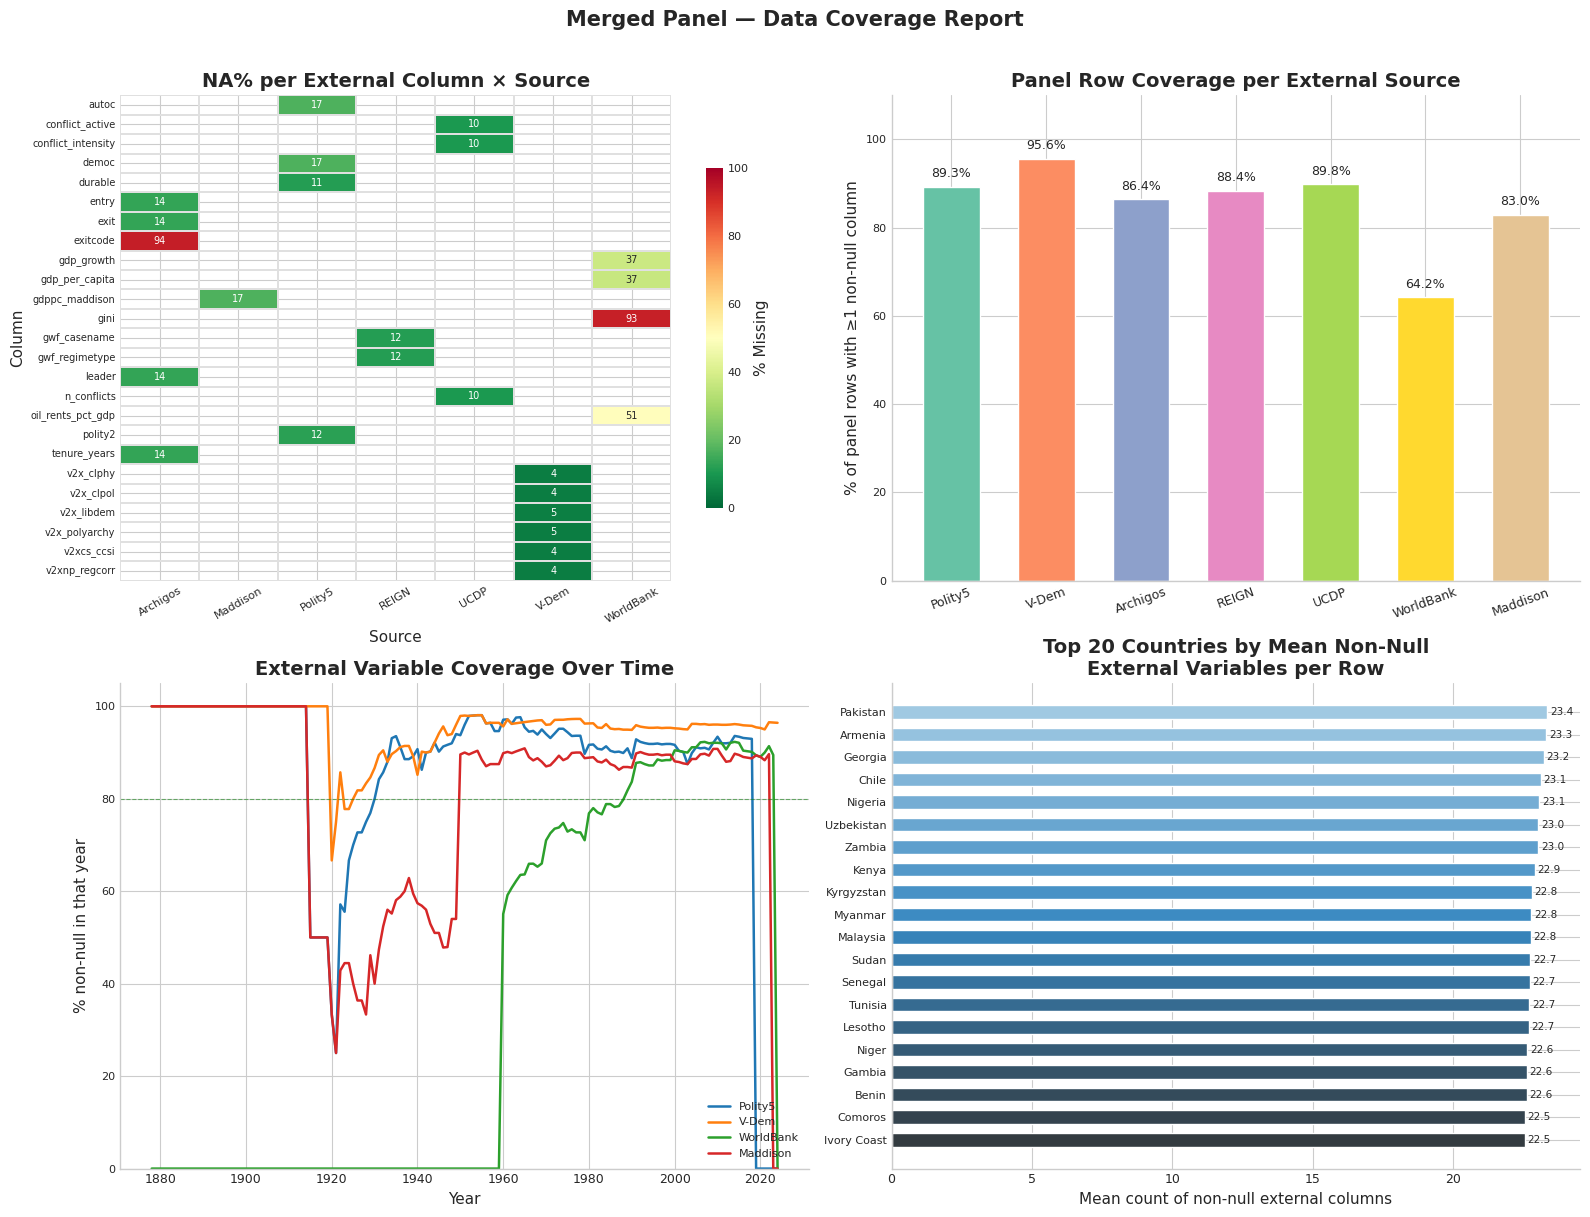

✅ Coverage figure saved to C:\Users\MSI\Desktop\projet stat\graph\coverage_report.png


In [82]:
# ============================================================
# CELL 10 — Coverage visualization (2×2 figure)
# ============================================================

EXT_SOURCE_COLS = {
    'Polity5':   ['polity2', 'democ', 'autoc', 'durable'],
    'V-Dem':     ['v2x_polyarchy', 'v2x_libdem', 'v2xcs_ccsi', 'v2x_clphy',
                  'v2x_clpol', 'v2xnp_regcorr'],
    'Archigos':  ['entry', 'exit', 'exitcode', 'leader', 'tenure_years'],
    'REIGN':     ['gwf_regimetype', 'gwf_casename'],
    'UCDP':      ['conflict_active', 'conflict_intensity', 'n_conflicts'],
    'WorldBank': ['gdp_per_capita', 'gdp_growth', 'gini', 'oil_rents_pct_gdp'],
    'Maddison':  ['gdppc_maddison'],
}

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Merged Panel — Data Coverage Report', fontsize=15, fontweight='bold', y=1.01)

# ── Plot 1: Heatmap — NA% per external column ────────────────
ax1 = axes[0, 0]
heatmap_rows = []
for src, cols in EXT_SOURCE_COLS.items():
    for col in cols:
        if col in df_panel.columns:
            heatmap_rows.append({
                'Column': col,
                'Source': src,
                'NA%':    df_panel[col].isna().mean() * 100
            })

hm_df = (pd.DataFrame(heatmap_rows)
           .pivot(index='Column', columns='Source', values='NA%'))
sns.heatmap(hm_df, ax=ax1, cmap='RdYlGn_r', vmin=0, vmax=100,
            annot=True, fmt='.0f', annot_kws={'size': 7},
            linewidths=0.3, linecolor='#e0e0e0',
            cbar_kws={'label': '% Missing', 'shrink': 0.7})
ax1.set_title('NA% per External Column × Source', fontweight='bold')
ax1.tick_params(axis='x', rotation=30, labelsize=8)
ax1.tick_params(axis='y', labelsize=7)

# ── Plot 2: Bar chart — % rows with coverage per source ──────
ax2 = axes[0, 1]
coverage = {}
for src, cols in EXT_SOURCE_COLS.items():
    present = [c for c in cols if c in df_panel.columns]
    if present:
        coverage[src] = df_panel[present].notna().any(axis=1).mean() * 100

src_names = list(coverage.keys())
src_vals  = list(coverage.values())
colors_bar = sns.color_palette('Set2', len(src_names))
bars = ax2.bar(src_names, src_vals, color=colors_bar, edgecolor='white', width=0.6)
ax2.set_ylim(0, 110)
ax2.set_ylabel('% of panel rows with ≥1 non-null column')
ax2.set_title('Panel Row Coverage per External Source', fontweight='bold')
ax2.tick_params(axis='x', rotation=20)
for bar, val in zip(bars, src_vals):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.5,
             f'{val:.1f}%', ha='center', va='bottom', fontsize=9)
ax2.spines[['top', 'right']].set_visible(False)

# ── Plot 3: Line plot — coverage over time ────────────────────
ax3 = axes[1, 0]
time_cols = {
    'polity2':       'Polity5',
    'v2x_polyarchy': 'V-Dem',
    'gdp_per_capita':'WorldBank',
    'gdppc_maddison':'Maddison',
    'conflict_active':'UCDP (binary, see note)',
}
colors_time = sns.color_palette('tab10', len(time_cols))

for (col, label), color in zip(time_cols.items(), colors_time):
    if col not in df_panel.columns:
        continue
    if col == 'conflict_active':
        # UCDP conflict_active=0 is valid, not missing → skip coverage line
        continue
    yearly_cov = (df_panel.groupby('panel_year')[col]
                  .apply(lambda x: x.notna().mean() * 100)
                  .reset_index(name='coverage'))
    ax3.plot(yearly_cov['panel_year'], yearly_cov['coverage'],
             label=label, color=color, lw=1.8)

ax3.set_title('External Variable Coverage Over Time', fontweight='bold')
ax3.set_xlabel('Year')
ax3.set_ylabel('% non-null in that year')
ax3.set_ylim(0, 105)
ax3.legend(fontsize=8, loc='lower right')
ax3.axhline(80, color='green', linestyle='--', lw=0.8, alpha=0.5, label='80%')
ax3.spines[['top', 'right']].set_visible(False)

# ── Plot 4: Bar chart — top 20 countries by enrichment ───────
ax4 = axes[1, 1]
ext_all_cols = [c for src_cols in EXT_SOURCE_COLS.values()
                for c in src_cols if c in df_panel.columns]

enrichment = (df_panel.groupby('ccode')[ext_all_cols]
              .apply(lambda x: x.notna().sum(axis=1).mean())
              .sort_values(ascending=False)
              .head(20))

# Map ccode → country name for labels
ccode_to_name = (df_arpd[['ccode', 'Country']]
                 .dropna()
                 .drop_duplicates('ccode')
                 .set_index('ccode')['Country']
                 .str.strip())

enrichment.index = enrichment.index.map(
    lambda x: ccode_to_name.get(x, str(x))
)

colors_enr = sns.color_palette('Blues_d', 20)
ax4.barh(enrichment.index[::-1], enrichment.values[::-1],
         color=colors_enr[::-1], height=0.6)
ax4.set_title('Top 20 Countries by Mean Non-Null\nExternal Variables per Row', fontweight='bold')
ax4.set_xlabel('Mean count of non-null external columns')
ax4.spines[['top', 'right']].set_visible(False)
for bar in ax4.patches:
    ax4.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height()/2,
             f'{bar.get_width():.1f}', va='center', fontsize=7.5)

plt.tight_layout()
fig.savefig(GRAPH_DIR / "coverage_report.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"✅ Coverage figure saved to {GRAPH_DIR / 'coverage_report.png'}")